In [39]:
!pip install fsspec
!pip install huggingface_hub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [143]:
daily = pd.read_parquet("hf://datasets/CMU-OSPO/protostar-climate-train-to-2018/daily/train-00000-of-00001.parquet")
annual = pd.read_parquet("hf://datasets/CMU-OSPO/protostar-climate-train-to-2018/annual_indices/train-00000-of-00001.parquet")
city = pd.read_parquet("hf://datasets/CMU-OSPO/protostar-climate-train-to-2018/city_info/train-00000-of-00001.parquet")

In [7]:
annual.head()

,Name,ID,Lat,Lon,Year,Miss Tmax,Miss Tmin,Miss Prcp,Avg Temp,Avg Tmax,...,Max Tmin,Min Tmin,Warm Days,Warm Nights,Cold Days,Cold Nights,Max 1-day P,Max 5-day P,Wet Days,cdd
0,Aberdeen,USW00014929,45.4558,-98.4131,1893,18,17,34,41.09,55.14,...,72.0,-42.0,9.32,5.75,13.70,16.71,1.9,3.31,15.39,591.0
1,Aberdeen,USW00014929,45.4558,-98.4131,1894,127,127,64,49.05,62.58,...,75.0,-19.0,10.68,5.48,1.64,3.56,2.0,3.22,14.74,588.0
2,Aberdeen,USW00014929,45.4558,-98.4131,1895,11,9,0,41.94,56.58,...,70.0,-46.0,7.12,4.11,13.15,16.99,2.5,4.20,21.77,499.5
3,Aberdeen,USW00014929,45.4558,-98.4131,1896,7,7,0,41.16,53.84,...,68.0,-28.0,10.41,4.93,14.79,16.16,2.0,3.77,35.76,606.5
4,Aberdeen,USW00014929,45.4558,-98.4131,1897,11,15,2,40.89,53.71,...,76.0,-34.0,8.77,4.93,18.08,19.73,3.0,4.65,30.39,566.5


## Annual Indices

### Dataset Structure

In [9]:
annual.shape

(28052, 24)

In [10]:
annual.columns

Index(['Name', 'ID', 'Lat', 'Lon', 'Year', 'Miss Tmax', 'Miss Tmin',
       'Miss Prcp', 'Avg Temp', 'Avg Tmax', 'Avg Tmin', 'ToT Prcp', 'Max Tmax',
       'Min Tmax', 'Max Tmin', 'Min Tmin', 'Warm Days', 'Warm Nights',
       'Cold Days', 'Cold Nights', 'Max 1-day P', 'Max 5-day P', 'Wet Days',
       'cdd'],
      dtype='str')

In [11]:
annual.dtypes

Name               str
ID                 str
Lat            float64
Lon            float64
Year             int64
Miss Tmax        int64
Miss Tmin        int64
Miss Prcp        int64
Avg Temp       float64
Avg Tmax       float64
Avg Tmin       float64
ToT Prcp       float64
Max Tmax       float64
Min Tmax       float64
Max Tmin       float64
Min Tmin       float64
Warm Days      float64
Warm Nights    float64
Cold Days      float64
Cold Nights    float64
Max 1-day P    float64
Max 5-day P    float64
Wet Days       float64
cdd            float64
dtype: object

In [15]:
annual["Name"].unique()

<ArrowStringArray>
[     'Aberdeen',       'Abilene',         'Aiken',         'Akron',
        'Albany',   'Albuquerque',      'Amarillo',     'Asheville',
       'Ashland',       'Astoria',
 ...
        'Wausau', 'WestPalmBeach',      'Wheeling',  'Williamsport',
     'Williston',    'Wilmington',    'Winnemucca',     'Worcester',
          'Yuma',     'Zaneville']
Length: 210, dtype: str

In [22]:
annual[["ID", "Year"]].duplicated().sum()

0

In [ ]:
cities = annual["Name"].unique()
city_years = pd.DataFrame(columns=["city", "earliest_year", "latest_year"])
city_name = []
earliest_year = []
latest_year = []
for city_name in cities:
    city_name.append(city_name)
    city_df = annual[annual["Name"] == city]
    year_order = list(city_df["Year"].sort_values())
    earliest_year.append(year_order[0])
    latest_year.append(year_order[-1])
city_years["city"] = city_name
city_years["earliest_year"] = earliest_year
city_years["latest_year"] = latest_year

In [34]:
city_years.head()

,city,earliest_year,latest_year
0,Aberdeen,1893,2018
1,Abilene,1886,2018
2,Aiken,1893,2018
3,Akron,1888,2018
4,Albany,1874,2018


In [37]:
annual[["Year", "Name"]].groupby("Year").count()

,Name
Year,
1851,1
1852,1
1853,1
1854,1
1855,1
...,...
2014,210
2015,210
2016,210


### Data Quality & Missingness

In [38]:
annual.head()

,Name,ID,Lat,Lon,Year,Miss Tmax,Miss Tmin,Miss Prcp,Avg Temp,Avg Tmax,...,Max Tmin,Min Tmin,Warm Days,Warm Nights,Cold Days,Cold Nights,Max 1-day P,Max 5-day P,Wet Days,cdd
0,Aberdeen,USW00014929,45.4558,-98.4131,1893,18,17,34,41.09,55.14,...,72.0,-42.0,9.32,5.75,13.70,16.71,1.9,3.31,15.39,591.0
1,Aberdeen,USW00014929,45.4558,-98.4131,1894,127,127,64,49.05,62.58,...,75.0,-19.0,10.68,5.48,1.64,3.56,2.0,3.22,14.74,588.0
2,Aberdeen,USW00014929,45.4558,-98.4131,1895,11,9,0,41.94,56.58,...,70.0,-46.0,7.12,4.11,13.15,16.99,2.5,4.20,21.77,499.5
3,Aberdeen,USW00014929,45.4558,-98.4131,1896,7,7,0,41.16,53.84,...,68.0,-28.0,10.41,4.93,14.79,16.16,2.0,3.77,35.76,606.5
4,Aberdeen,USW00014929,45.4558,-98.4131,1897,11,15,2,40.89,53.71,...,76.0,-34.0,8.77,4.93,18.08,19.73,3.0,4.65,30.39,566.5


In [40]:
sns.set_theme(style="whitegrid")

targets = ["Avg Temp", "ToT Prcp", "Max Tmax", "cdd"]
missing_cols = ["Miss Tmax", "Miss Tmin", "Miss Prcp"]

print("Dataset shape:", annual.shape)
print("Number of cities:", annual["ID"].nunique())

missing_summary = pd.DataFrame({
    "Missing Count": annual.isna().sum(),
    "Missing %": annual.isna().mean() * 100
}).sort_values("Missing %", ascending=False)

display(missing_summary.round(2))

print("\nMissing values in forecast targets:")
display(missing_summary.loc[targets].round(2))

Dataset shape: (28052, 24)
Number of cities: 210


,Missing Count,Missing %
cdd,1206,4.30
Avg Temp,1193,4.25
Avg Tmax,1184,4.22
Avg Tmin,1174,4.19
Max Tmin,0,0.00
Wet Days,0,0.00
Max 5-day P,0,0.00
Max 1-day P,0,0.00
Cold Nights,0,0.00
Cold Days,0,0.00



Missing values in forecast targets:


,Missing Count,Missing %
Avg Temp,1193,4.25
ToT Prcp,0,0.00
Max Tmax,0,0.00
cdd,1206,4.30


,Miss Tmax,Miss Tmin,Miss Prcp
count,28052.00,28052.00,28052.00
mean,20.76,20.73,18.66
std,77.48,77.33,71.11
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,0.00,0.00,0.00
75%,1.00,1.00,0.00
max,366.00,366.00,366.00


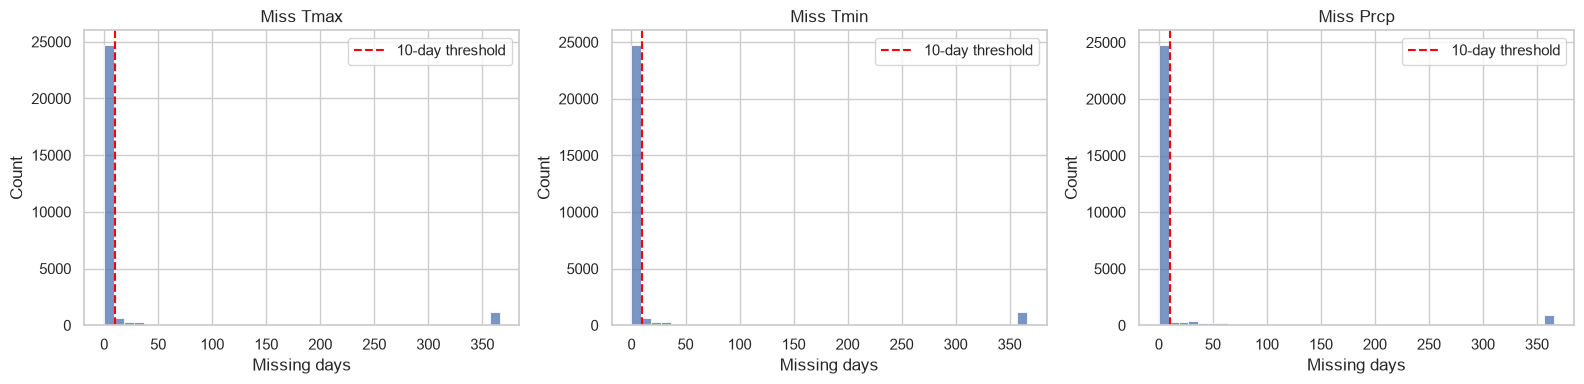

In [41]:
display(annual[missing_cols].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, missing_cols):
    sns.histplot(
        annual[col].dropna(),
        bins=40,
        ax=ax
    )
    ax.axvline(
        10,
        color="red",
        linestyle="--",
        label="10-day threshold"
    )
    ax.set_title(col)
    ax.set_xlabel("Missing days")
    ax.legend()

plt.tight_layout()
plt.show()

In [43]:
THRESHOLD = 10

# Target-specific quality flags
annual["valid_avg_temp"] = (
    (annual["Miss Tmax"] <= THRESHOLD) &
    (annual["Miss Tmin"] <= THRESHOLD) &
    annual["Avg Temp"].notna()
)

annual["valid_precip"] = (
    (annual["Miss Prcp"] <= THRESHOLD) &
    annual["ToT Prcp"].notna()
)

annual["valid_max_tmax"] = (
    (annual["Miss Tmax"] <= THRESHOLD) &
    annual["Max Tmax"].notna()
)

# cdd requires both Tmax and Tmin on the same day.
# The total number of incomplete days lies between:
# max(Miss Tmax, Miss Tmin) and Miss Tmax + Miss Tmin.

lower_bound = annual[["Miss Tmax", "Miss Tmin"]].max(axis=1)
upper_bound = annual["Miss Tmax"] + annual["Miss Tmin"]

annual["cdd_quality"] = np.select(
    [
        annual["cdd"].isna(),
        upper_bound <= THRESHOLD,
        lower_bound > THRESHOLD
    ],
    [
        "missing_target",
        "valid",
        "invalid"
    ],
    default="needs_daily_check"
)

quality_summary = pd.DataFrame({
    "Target": ["Avg Temp", "ToT Prcp", "Max Tmax"],
    "Valid City-Years": [
        annual["valid_avg_temp"].sum(),
        annual["valid_precip"].sum(),
        annual["valid_max_tmax"].sum()
    ]
})

quality_summary["Total City-Years"] = len(annual)
quality_summary["Valid %"] = (
    quality_summary["Valid City-Years"] /
    quality_summary["Total City-Years"] * 100
)

display(quality_summary.round(2))

print("\ncdd quality classification:")
display(
    annual["cdd_quality"]
    .value_counts()
    .rename_axis("Quality")
    .reset_index(name="City-Years")
)

,Target,Valid City-Years,Total City-Years,Valid %
0,Avg Temp,24583,28052,87.63
1,ToT Prcp,24858,28052,88.61
2,Max Tmax,24868,28052,88.65



cdd quality classification:


,Quality,City-Years
0,valid,23974
1,invalid,2263
2,missing_target,1206
3,needs_daily_check,609


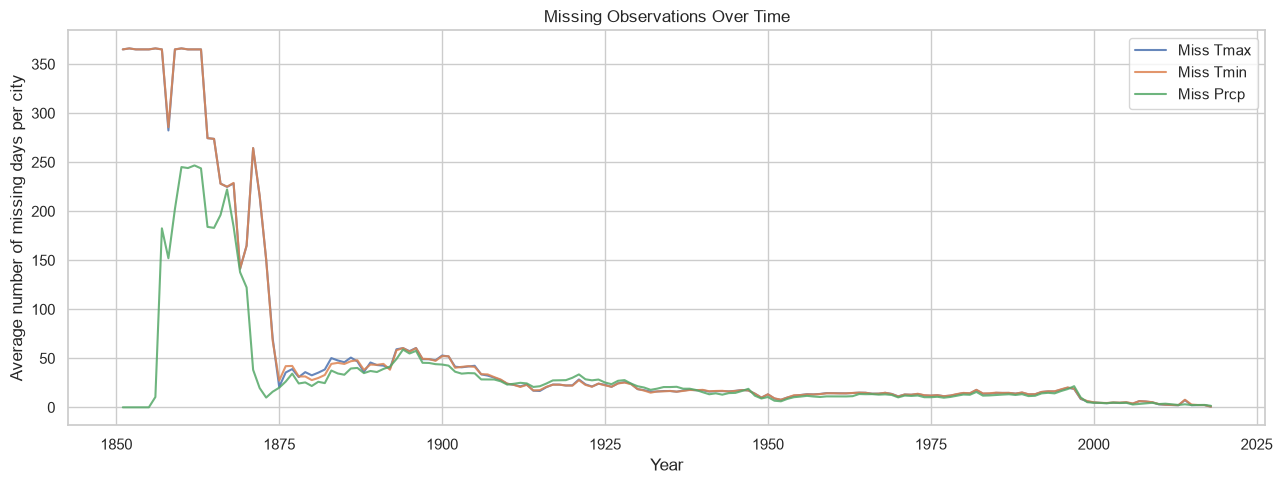

In [44]:
missing_by_year = (
    annual.groupby("Year")[missing_cols]
    .mean()
)

plt.figure(figsize=(13, 5))

for col in missing_cols:
    plt.plot(
        missing_by_year.index,
        missing_by_year[col],
        label=col,
        alpha=0.85
    )

plt.xlabel("Year")
plt.ylabel("Average number of missing days per city")
plt.title("Missing Observations Over Time")
plt.legend()
plt.tight_layout()
plt.show()

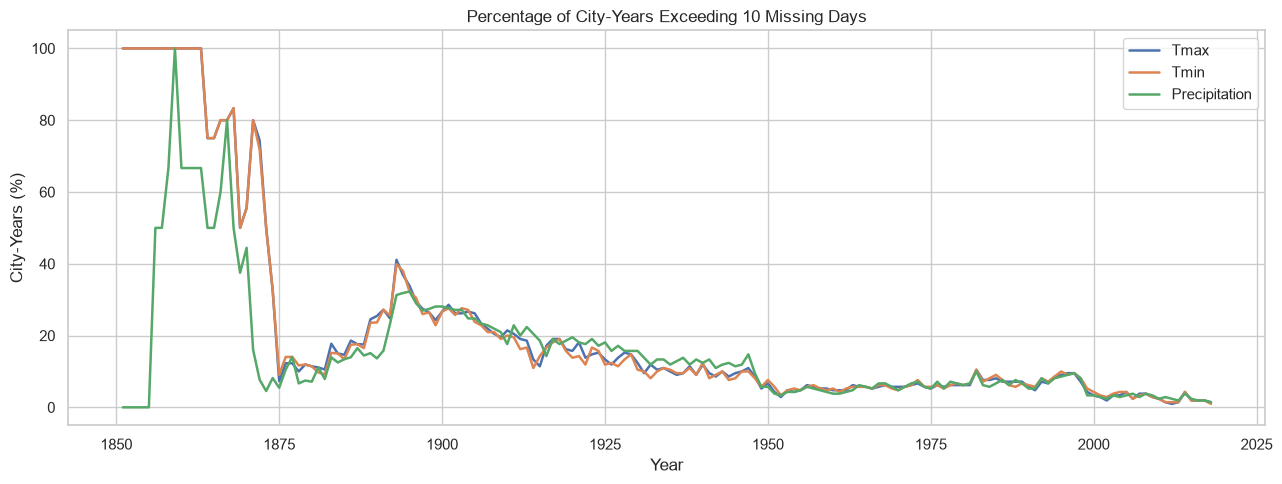

In [45]:
annual["excess_missing_tmax"] = annual["Miss Tmax"] > 10
annual["excess_missing_tmin"] = annual["Miss Tmin"] > 10
annual["excess_missing_prcp"] = annual["Miss Prcp"] > 10

missing_rate_by_year = (
    annual.groupby("Year")[
        [
            "excess_missing_tmax",
            "excess_missing_tmin",
            "excess_missing_prcp"
        ]
    ]
    .mean() * 100
)

missing_rate_by_year.plot(
    figsize=(13, 5),
    linewidth=1.8
)

plt.title("Percentage of City-Years Exceeding 10 Missing Days")
plt.xlabel("Year")
plt.ylabel("City-Years (%)")
plt.legend(["Tmax", "Tmin", "Precipitation"])
plt.tight_layout()
plt.show()

In [46]:
city_quality = (
    annual.groupby(["ID", "Name"])
    .agg(
        years_available=("Year", "count"),
        avg_missing_tmax=("Miss Tmax", "mean"),
        avg_missing_tmin=("Miss Tmin", "mean"),
        avg_missing_prcp=("Miss Prcp", "mean"),
        valid_temp_years=("valid_avg_temp", "sum"),
        valid_precip_years=("valid_precip", "sum"),
        valid_hottest_years=("valid_max_tmax", "sum")
    )
    .reset_index()
)

city_quality["valid_temp_pct"] = (
    city_quality["valid_temp_years"] /
    city_quality["years_available"] * 100
)

city_quality["valid_precip_pct"] = (
    city_quality["valid_precip_years"] /
    city_quality["years_available"] * 100
)

display(
    city_quality.sort_values("valid_temp_pct").head(15).round(2)
)

,ID,Name,years_available,avg_missing_tmax,avg_missing_tmin,avg_missing_prcp,valid_temp_years,valid_precip_years,valid_hottest_years,valid_temp_pct,valid_precip_pct
209,USW00094973,Hayward,125,195.62,196.06,48.78,23,72,25,18.40,57.60
123,USW00014943,SiouxCity,129,283.36,283.36,283.60,28,27,28,21.71,20.93
79,USW00014710,Manchester,133,205.10,205.23,165.33,44,45,44,33.08,33.83
10,USW00003812,Asheville,149,232.05,232.05,217.65,54,57,54,36.24,38.26
14,USW00003856,Huntsville,124,181.28,180.17,182.06,49,43,50,39.52,34.68
103,USW00014894,Wheeling,140,174.41,174.74,165.16,60,42,62,42.86,30.00
25,USW00003963,Jefferson,124,18.33,13.72,11.23,55,105,59,44.35,84.68
2,USC00280734,Belvidere,126,14.06,20.80,6.45,64,111,85,50.79,88.10
104,USW00014895,Akron,131,132.98,133.05,155.01,70,66,71,53.44,50.38
1,USC00166584,Natchitoches,125,89.50,89.66,85.52,68,83,75,54.40,66.40


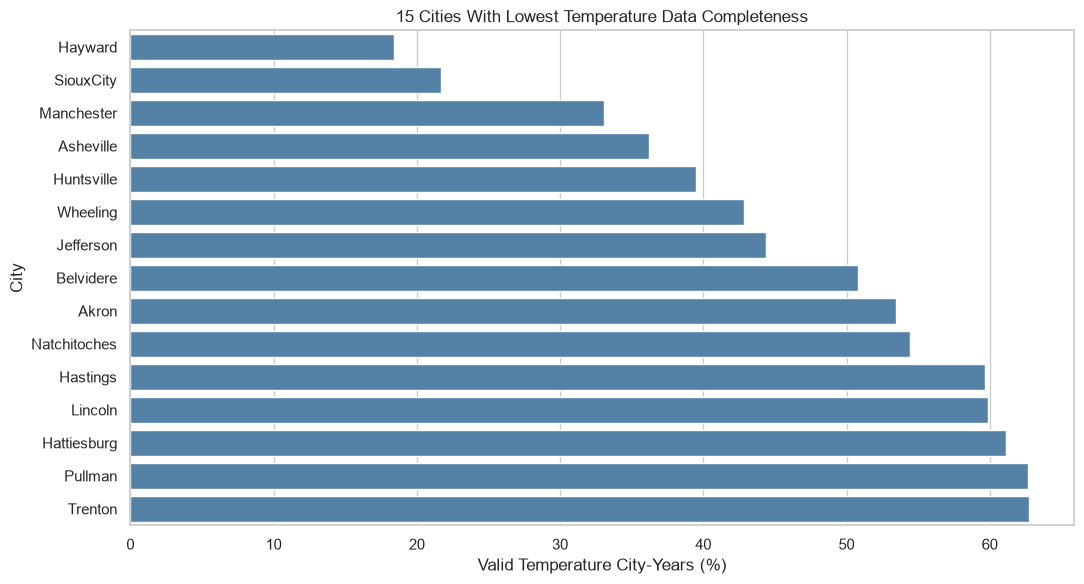

In [47]:
worst_cities = (
    city_quality
    .sort_values("valid_temp_pct")
    .head(15)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=worst_cities,
    x="valid_temp_pct",
    y="Name",
    color="steelblue"
)

plt.xlabel("Valid Temperature City-Years (%)")
plt.ylabel("City")
plt.title("15 Cities With Lowest Temperature Data Completeness")
plt.tight_layout()
plt.show()

In [48]:
# Calculate city-specific 5th percentile precipitation
precip_p05 = (
    annual.groupby("ID")["ToT Prcp"]
    .transform(lambda x: x.quantile(0.05))
)

suspicious_precip = annual.loc[
    (annual["ToT Prcp"] <= precip_p05) &
    (annual["Miss Prcp"] > 10),
    ["Name", "ID", "Year", "ToT Prcp", "Miss Prcp"]
].sort_values(
    "Miss Prcp",
    ascending=False
)

print("Low-precipitation city-years with >10 missing days:")
print("Count:", len(suspicious_precip))

display(suspicious_precip.head(20))

Low-precipitation city-years with >10 missing days:
Count: 1148


,Name,ID,Year,ToT Prcp,Miss Prcp
23859,SiouxCity,USW00014943,1908,0.0,366
23863,SiouxCity,USW00014943,1912,0.0,366
21884,Rockford,USW00094822,1948,0.0,366
22168,Russellville,USW00053920,1980,0.0,366
23014,SanDiego,USW00023188,1868,0.0,366
23847,SiouxCity,USW00014943,1896,0.0,366
23855,SiouxCity,USW00014943,1904,0.0,366
6094,CrescentCity,USW00024286,1912,0.0,366
5213,ColumbiaMO,USW00003945,1968,0.0,366
5209,ColumbiaMO,USW00003945,1964,0.0,366


In [49]:
cdd_p05 = (
    annual.groupby("ID")["cdd"]
    .transform(lambda x: x.quantile(0.05))
)

suspicious_cdd = annual.loc[
    (annual["cdd"] <= cdd_p05) &
    (
        (annual["Miss Tmax"] > 10) |
        (annual["Miss Tmin"] > 10)
    ),
    [
        "Name", "ID", "Year", "cdd",
        "Miss Tmax", "Miss Tmin"
    ]
].sort_values(
    ["Miss Tmax", "Miss Tmin"],
    ascending=False
)

print("Low-cdd city-years with high missingness:")
print("Count:", len(suspicious_cdd))

display(suspicious_cdd.head(20))

Low-cdd city-years with high missingness:
Count: 418


,Name,ID,Year,cdd,Miss Tmax,Miss Tmin
15421,Manchester,USW00014710,1962,0.0,359,359
12891,Jonesboro,USW00003953,1894,0.0,351,351
11872,Huntington,USW00003860,1928,0.0,344,349
267,Aiken,USC00380072,1901,0.0,343,344
7854,Ely,USW00023154,1907,0.0,343,344
12892,Jonesboro,USW00003953,1895,0.0,342,342
15626,McCook,USW00094040,1896,16.0,339,339
9559,Glasgow,USW00094008,1909,0.0,339,338
13950,Lansing,USW00014836,1871,0.0,337,337
11523,Hayward,USW00094973,1974,0.0,336,336


In [50]:
summary_rows = []

quality_flags = {
    "Avg Temp": "valid_avg_temp",
    "ToT Prcp": "valid_precip",
    "Max Tmax": "valid_max_tmax"
}

for target, flag in quality_flags.items():
    summary_rows.append({
        "Target": target,
        "Missing Target Values": annual[target].isna().sum(),
        "Valid City-Years": annual[flag].sum(),
        "Invalid/Unusable City-Years": (~annual[flag]).sum(),
        "Valid %": annual[flag].mean() * 100
    })

cdd_valid = annual["cdd_quality"].eq("valid")
cdd_uncertain = annual["cdd_quality"].eq("needs_daily_check")

summary_rows.append({
    "Target": "cdd",
    "Missing Target Values": annual["cdd"].isna().sum(),
    "Valid City-Years": cdd_valid.sum(),
    "Invalid/Unusable City-Years": (
        annual["cdd_quality"].isin(["invalid", "missing_target"]).sum()
    ),
    "Valid %": cdd_valid.mean() * 100
})

final_quality_report = pd.DataFrame(summary_rows)

display(final_quality_report.round(2))

print(
    "\nAdditional cdd city-years requiring daily verification:",
    cdd_uncertain.sum()
)

,Target,Missing Target Values,Valid City-Years,Invalid/Unusable City-Years,Valid %
0,Avg Temp,1193,24583,3469,87.63
1,ToT Prcp,0,24858,3194,88.61
2,Max Tmax,0,24868,3184,88.65
3,cdd,1206,23974,3469,85.46



Additional cdd city-years requiring daily verification: 609


In [51]:
# Define historical periods
annual["period"] = pd.cut(
    annual["Year"],
    bins=[1850, 1949, 1988, 2018],
    labels=["Before 1950", "1950–1988", "1989–2018"]
)

# Calculate percentage of valid city-years
period_quality = (
    annual.groupby("period", observed=True)
    .agg(
        total_city_years=("ID", "count"),
        valid_avg_temp=("valid_avg_temp", "mean"),
        valid_precip=("valid_precip", "mean"),
        valid_max_tmax=("valid_max_tmax", "mean")
    )
)

# cdd: only definitely valid observations
period_quality["valid_cdd"] = (
    annual["cdd_quality"].eq("valid")
    .groupby(annual["period"], observed=True)
    .mean()
)

quality_cols = [
    "valid_avg_temp",
    "valid_precip",
    "valid_max_tmax",
    "valid_cdd"
]

period_quality[quality_cols] *= 100

display(period_quality.round(2))

,total_city_years,valid_avg_temp,valid_precip,valid_max_tmax,valid_cdd
period,,,,,
Before 1950,13562,80.57,81.94,82.11,77.22
1950–1988,8190,93.53,94.27,94.05,92.55
1989–2018,6300,95.17,95.62,95.70,93.98


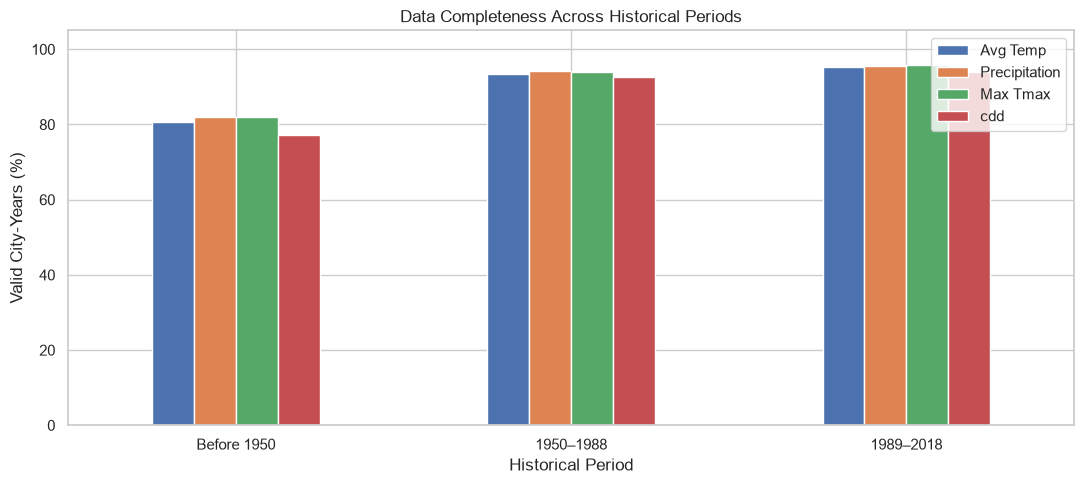

In [52]:
period_quality[quality_cols].plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Data Completeness Across Historical Periods")
plt.xlabel("Historical Period")
plt.ylabel("Valid City-Years (%)")
plt.xticks(rotation=0)
plt.ylim(0, 105)
plt.legend(["Avg Temp", "Precipitation", "Max Tmax", "cdd"])
plt.tight_layout()
plt.show()

In [53]:
recent = annual[
    annual["Year"].between(1989, 2018)
].copy()

recent_city_quality = (
    recent.groupby(["ID", "Name"])
    .agg(
        years_available=("Year", "count"),
        valid_temp_pct=("valid_avg_temp", "mean"),
        valid_precip_pct=("valid_precip", "mean"),
        valid_hottest_pct=("valid_max_tmax", "mean")
    )
    .reset_index()
)

recent_city_quality[
    ["valid_temp_pct", "valid_precip_pct", "valid_hottest_pct"]
] *= 100

display(
    recent_city_quality
    .sort_values("valid_temp_pct")
    .head(15)
    .round(2)
)

,ID,Name,years_available,valid_temp_pct,valid_precip_pct,valid_hottest_pct
14,USW00003856,Huntsville,30,3.33,3.33,3.33
2,USC00280734,Belvidere,30,13.33,73.33,53.33
0,USC00042863,Escondido,30,33.33,73.33,33.33
9,USW00003171,Riverside,30,40.00,83.33,43.33
5,USC00380072,Aiken,30,53.33,56.67,53.33
104,USW00014895,Akron,30,53.33,56.67,53.33
103,USW00014894,Wheeling,30,60.00,66.67,60.00
209,USW00094973,Hayward,30,63.33,83.33,63.33
180,USW00093821,Louisville,30,63.33,63.33,63.33
79,USW00014710,Manchester,30,63.33,73.33,63.33


In [54]:
problem_cities = [
    "Hayward",
    "SiouxCity",
    "Manchester",
    "Asheville",
    "Huntsville"
]

display(
    recent_city_quality[
        recent_city_quality["Name"].isin(problem_cities)
    ].round(2)
)

,ID,Name,years_available,valid_temp_pct,valid_precip_pct,valid_hottest_pct
10,USW00003812,Asheville,30,100.00,100.00,100.00
14,USW00003856,Huntsville,30,3.33,3.33,3.33
79,USW00014710,Manchester,30,63.33,73.33,63.33
123,USW00014943,SiouxCity,30,76.67,76.67,76.67
209,USW00094973,Hayward,30,63.33,83.33,63.33


### Distribution & Outlier Analysis

In [55]:
sns.set_theme(style="whitegrid")

targets = ["Avg Temp", "ToT Prcp", "Max Tmax", "cdd"]

quality_flags = {
    "Avg Temp": "valid_avg_temp",
    "ToT Prcp": "valid_precip",
    "Max Tmax": "valid_max_tmax",
}

eda = annual.copy()

# Store original target values for reference
# and create separate quality-filtered columns.

for target in targets:
    clean_col = f"{target}_clean"

    if target == "cdd":
        valid = eda["cdd_quality"].eq("valid")
    else:
        valid = eda[quality_flags[target]].fillna(False)

    eda[clean_col] = eda[target].where(valid)

clean_targets = {
    target: f"{target}_clean"
    for target in targets
}

print("Original rows:", len(annual))
print("EDA rows:", len(eda))

display(
    eda[
        ["Name", "Year"] + list(clean_targets.values())
    ].head()
)

Original rows: 28052
EDA rows: 28052


,Name,Year,Avg Temp_clean,ToT Prcp_clean,Max Tmax_clean,cdd_clean
0,Aberdeen,1893,NaN,NaN,NaN,NaN
1,Aberdeen,1894,NaN,NaN,NaN,NaN
2,Aberdeen,1895,NaN,30.23,NaN,NaN
3,Aberdeen,1896,41.16,42.11,105.0,NaN
4,Aberdeen,1897,NaN,35.54,NaN,NaN


In [56]:
summary = eda[
    list(clean_targets.values())
].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

summary.index = targets

summary["IQR"] = summary["75%"] - summary["25%"]

summary["Skewness"] = [
    eda[clean_targets[t]].skew()
    for t in targets
]

display(summary.round(2))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,IQR,Skewness
Avg Temp,24583.0,55.14,8.91,32.02,38.69,42.33,48.39,53.38,62.16,70.77,76.04,79.97,13.77,0.39
ToT Prcp,24858.0,34.24,16.24,0.03,4.31,8.47,22.00,34.80,44.66,61.60,74.71,114.03,22.66,0.25
Max Tmax,24868.0,98.50,5.83,69.00,85.00,90.00,95.00,98.00,102.00,108.00,115.00,125.00,7.00,0.17
cdd,23974.0,1315.86,979.99,0.00,18.37,202.33,582.50,1023.50,1870.50,3224.50,4449.41,5538.75,1288.00,1.17


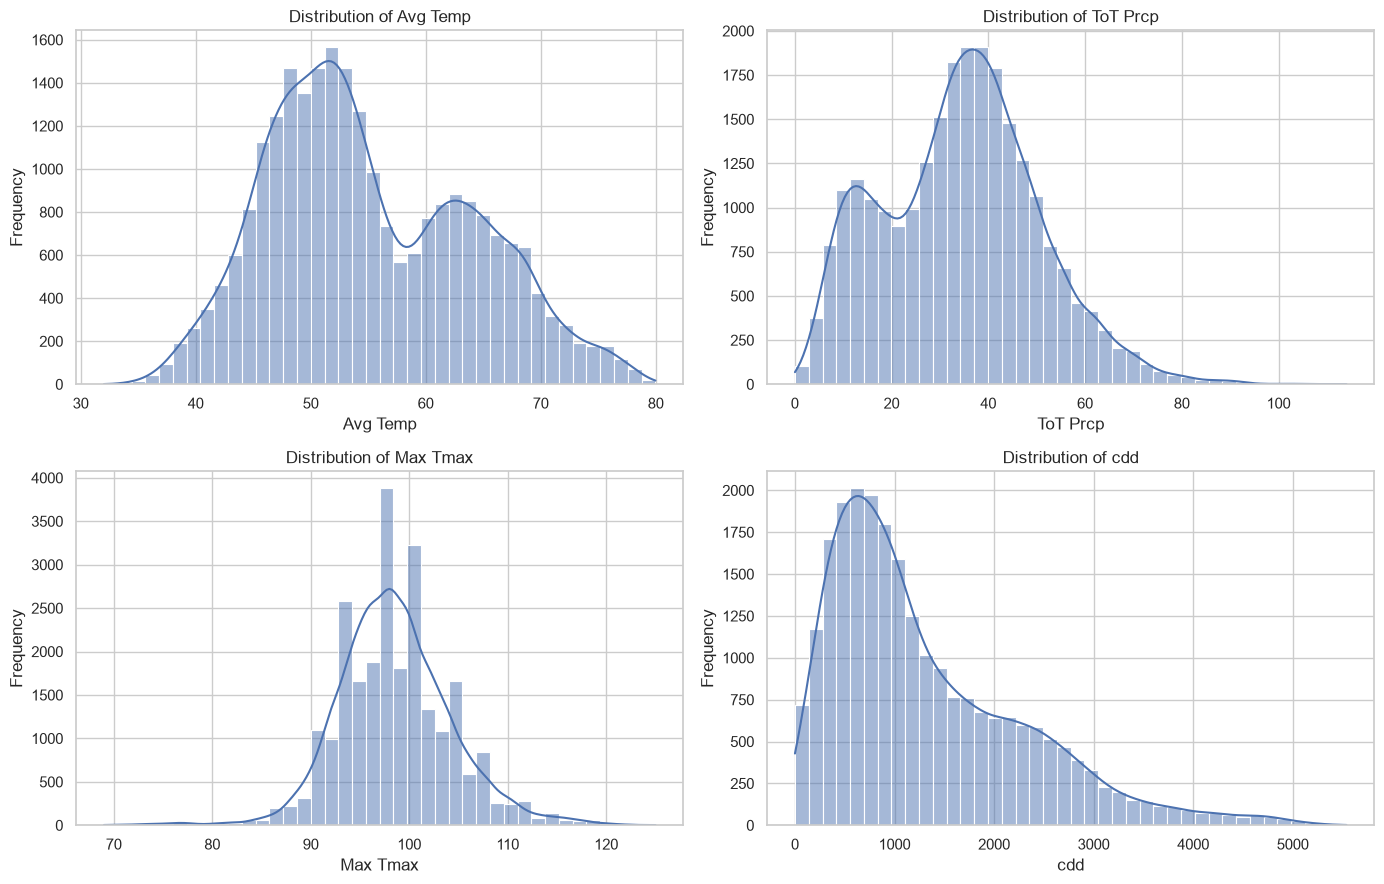

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes = axes.flatten()

for ax, target in zip(axes, targets):

    sns.histplot(
        data=eda,
        x=clean_targets[target],
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {target}")
    ax.set_xlabel(target)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

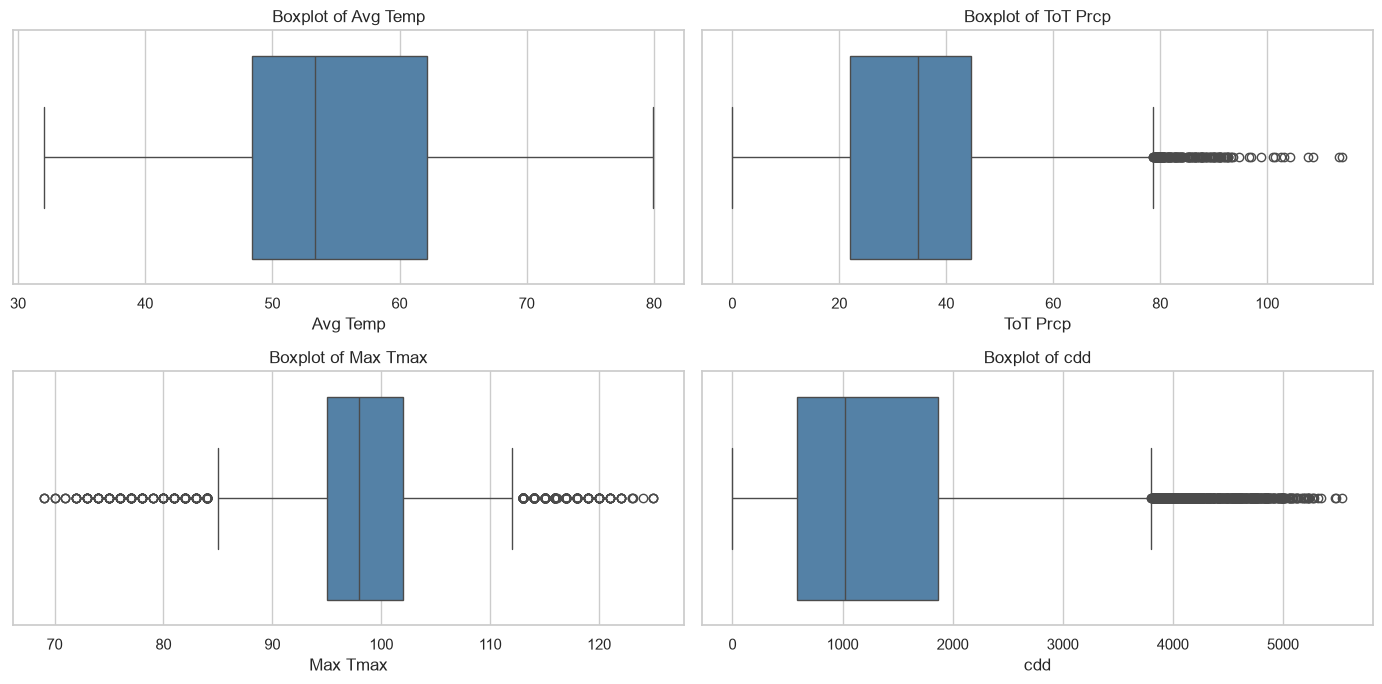

In [58]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))

axes = axes.flatten()

for ax, target in zip(axes, targets):

    sns.boxplot(
        x=eda[clean_targets[target]].dropna(),
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"Boxplot of {target}")
    ax.set_xlabel(target)

plt.tight_layout()
plt.show()

In [59]:
city_stats = (
    eda.groupby(["ID", "Name"])
    .agg(
        avg_temp_mean=("Avg Temp_clean", "mean"),
        avg_temp_std=("Avg Temp_clean", "std"),

        precip_mean=("ToT Prcp_clean", "mean"),
        precip_std=("ToT Prcp_clean", "std"),

        hottest_mean=("Max Tmax_clean", "mean"),
        hottest_std=("Max Tmax_clean", "std"),

        cdd_mean=("cdd_clean", "mean"),
        cdd_std=("cdd_clean", "std"),

        valid_temp_years=("Avg Temp_clean", "count"),
        valid_precip_years=("ToT Prcp_clean", "count"),
        valid_hottest_years=("Max Tmax_clean", "count"),
        valid_cdd_years=("cdd_clean", "count")
    )
    .reset_index()
)

display(city_stats.head())

,ID,Name,avg_temp_mean,avg_temp_std,precip_mean,precip_std,hottest_mean,hottest_std,cdd_mean,cdd_std,valid_temp_years,valid_precip_years,valid_hottest_years,valid_cdd_years
0,USC00042863,Escondido,62.330000,2.009269,15.229222,6.362929,103.193902,3.557512,980.340385,300.223059,82,90,82,78
1,USC00166584,Natchitoches,66.537206,1.288576,53.851325,11.151604,101.254667,3.326685,2556.429032,263.945112,68,83,75,62
2,USC00280734,Belvidere,51.096094,1.513315,46.162523,7.492243,96.482353,3.577748,753.701923,206.602827,64,111,85,52
3,USC00286055,NewBrunswick,53.012203,1.255702,46.421917,7.468535,97.134454,3.394723,929.743534,161.327649,118,120,119,116
4,USC00356749,Portland,54.107594,1.298458,42.920963,8.724388,97.664179,3.881601,354.958984,118.186738,133,135,134,128


In [60]:
recent_eda = eda[
    eda["Year"].between(1989, 2018)
].copy()

for target in targets:

    col = clean_targets[target]

    variability = (
        recent_eda.groupby(["ID", "Name"])[col]
        .agg(["count", "mean", "std"])
        .reset_index()
    )

    variability = variability[
        variability["count"] >= 20
    ]

    top_variable = (
        variability
        .sort_values("std", ascending=False)
        .head(10)
    )

    print(f"\nTop 10 cities by variability: {target}")

    display(top_variable.round(2))


Top 10 cities by variability: Avg Temp


,ID,Name,count,mean,std
100,USW00014847,SaultSteMarie,30,41.88,2.12
108,USW00014914,Fargo,30,42.59,2.12
116,USW00014929,Aberdeen,30,43.71,2.06
112,USW00014922,Minneapolis,30,46.70,2.03
115,USW00014926,SaintCloud,30,43.20,1.99
208,USW00094950,Mitchell,27,47.43,1.99
114,USW00014925,RochesterMN,30,44.95,1.98
186,USW00094008,Glasgow,30,43.32,1.97
105,USW00014897,Wausau,30,44.18,1.97
109,USW00014916,GrandForks,28,40.52,1.96



Top 10 cities by variability: ToT Prcp


,ID,Name,count,mean,std
166,USW00024286,CrescentCity,22,59.99,15.98
63,USW00013899,Pensacola,30,68.04,14.36
143,USW00023275,Ukiah,27,36.62,13.50
173,USW00093729,CapeHatteras,30,61.04,13.27
184,USW00093874,Gulfport,28,64.63,12.87
191,USW00094224,Astoria,30,70.62,12.70
20,USW00003937,LakeCharles,30,59.25,12.58
38,USW00012960,Houston,30,51.70,12.45
65,USW00013957,Shreveport,30,52.13,12.16
72,USW00013970,BatonRouge,30,62.66,12.10



Top 10 cities by variability: Max Tmax


,ID,Name,count,mean,std
166,USW00024286,CrescentCity,26,80.23,5.18
141,USW00023188,SanDiego,30,93.84,4.72
119,USW00014936,Huron,30,100.43,4.54
116,USW00014929,Aberdeen,30,98.13,4.50
26,USW00003965,Stillwater,26,105.88,4.45
167,USW00053920,Russellville,30,102.06,4.43
68,USW00013963,LittleRock,30,102.63,4.42
73,USW00013971,Harrison,30,98.97,4.40
208,USW00094950,Mitchell,28,100.43,4.39
124,USW00014944,SiouxFalls,30,97.40,4.37



Top 10 cities by variability: cdd


,ID,Name,count,mean,std
1,USC00166584,Natchitoches,21,2599.91,343.57
138,USW00023179,Needles,29,4798.25,329.05
67,USW00013962,Abilene,30,2510.08,321.70
19,USW00003927,DallasFortWorth,30,2904.87,317.95
170,USW00093134,LosAngeles,30,1414.24,316.80
136,USW00023155,Bakersfield,30,2336.19,305.43
139,USW00023183,Phoenix,30,4736.29,300.35
65,USW00013957,Shreveport,30,2653.36,296.35
69,USW00013964,FortSmith,30,2155.38,296.04
129,USW00023044,ElPaso,29,2552.98,292.33


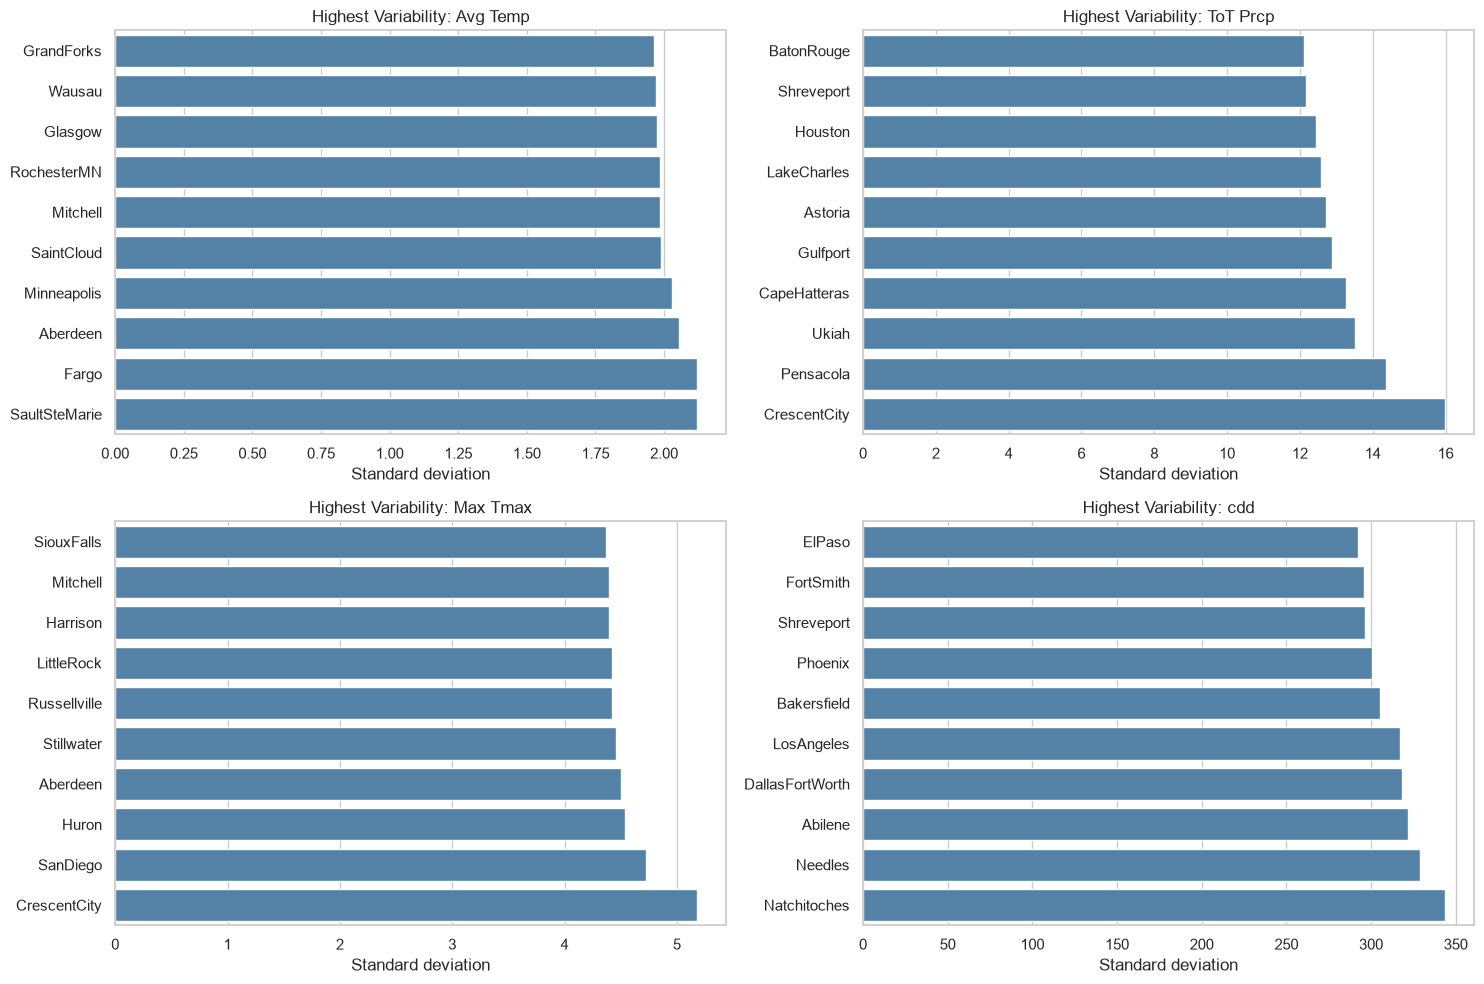

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, target in zip(axes.flatten(), targets):

    col = clean_targets[target]

    variability = (
        recent_eda.groupby(["ID", "Name"])[col]
        .agg(["count", "std"])
        .reset_index()
    )

    top10 = (
        variability[variability["count"] >= 20]
        .nlargest(10, "std")
        .sort_values("std")
    )

    sns.barplot(
        data=top10,
        x="std",
        y="Name",
        color="steelblue",
        ax=ax
    )

    ax.set_title(f"Highest Variability: {target}")
    ax.set_xlabel("Standard deviation")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [62]:
MIN_VALID_YEARS = 20

for target in targets:

    col = clean_targets[target]

    grouped = eda.groupby("ID")[col]

    q1 = grouped.transform(
        lambda x: x.quantile(0.25)
    )

    q3 = grouped.transform(
        lambda x: x.quantile(0.75)
    )

    n_valid = grouped.transform("count")

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    flag_col = f"{target}_outlier"

    eda[flag_col] = (
        (eda[col] < lower_bound) |
        (eda[col] > upper_bound)
    ) & (
        n_valid >= MIN_VALID_YEARS
    ) & (
        iqr > 0
    )

print("Outlier flags created.")

Outlier flags created.


In [63]:
outlier_summary = []

for target in targets:

    flag_col = f"{target}_outlier"
    clean_col = clean_targets[target]

    n_outliers = eda[flag_col].sum()
    n_valid = eda[clean_col].notna().sum()

    outlier_summary.append({
        "Target": target,
        "Valid Observations": n_valid,
        "Outlier Count": n_outliers,
        "Outlier %": (
            n_outliers / n_valid * 100
            if n_valid > 0 else np.nan
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary.round(2))

,Target,Valid Observations,Outlier Count,Outlier %
0,Avg Temp,24583,298,1.21
1,ToT Prcp,24858,355,1.43
2,Max Tmax,24868,299,1.20
3,cdd,23974,318,1.33


In [64]:
for target in targets:

    flag_col = f"{target}_outlier"

    cols = [
        "Name",
        "ID",
        "Year",
        target,
        "Miss Tmax",
        "Miss Tmin",
        "Miss Prcp"
    ]

    flagged = (
        eda.loc[eda[flag_col], cols]
        .sort_values(target, ascending=False)
    )

    print(f"\nFlagged observations for {target}:")
    display(flagged.head(15))


Flagged observations for Avg Temp:


,Name,ID,Year,Avg Temp,Miss Tmax,Miss Tmin,Miss Prcp
18312,Needles,USW00023179,2017,78.29,0,0,0
18313,Needles,USW00023179,2018,78.19,1,1,0
27001,WestPalmBeach,USW00012844,2015,78.04,0,0,0
25255,Tampa,USW00012842,2017,76.34,0,0,0
6070,CorpusChristi,USW00012924,2012,75.82,0,0,0
19403,Orlando,USW00012815,2015,75.56,0,0,0
6074,CorpusChristi,USW00012924,2016,74.88,0,0,0
13307,KeyWest,USW00012836,1901,74.73,0,0,0
9542,Galveston,USW00012923,2017,74.38,0,0,0
9537,Galveston,USW00012923,2012,73.95,0,0,0



Flagged observations for ToT Prcp:


,Name,ID,Year,ToT Prcp,Miss Tmax,Miss Tmin,Miss Prcp
1229,Astoria,USW00094224,1933,114.03,0,0,0
1246,Astoria,USW00094224,1950,113.34,0,0,3
26933,WestPalmBeach,USW00012844,1947,108.63,0,0,1
25074,Tallahassee,USW00093805,1964,104.18,0,0,0
12577,Jackson,USW00003940,1979,92.75,0,0,0
16961,Mobile,USW00013838,1881,92.32,0,1,0
3599,CapeHatteras,USW00093729,1989,90.84,0,0,0
11246,Hattiesburg,USW00013833,1961,90.71,6,2,0
3628,CapeHatteras,USW00093729,2018,90.07,5,5,2
11268,Hattiesburg,USW00013833,1983,85.43,7,10,0



Flagged observations for Max Tmax:


,Name,ID,Year,Max Tmax,Miss Tmax,Miss Tmin,Miss Prcp
27905,Yuma,USW00003145,1995,124.0,0,0,0
27860,Yuma,USW00003145,1950,123.0,0,0,0
27900,Yuma,USW00003145,1990,122.0,0,0,0
19412,Pendleton,USW00024155,1898,119.0,0,16,21
21447,Riverside,USW00003171,1917,118.0,3,2,195
21455,Riverside,USW00003171,1925,118.0,0,0,256
21548,Riverside,USW00003171,2018,118.0,0,0,0
1922,Bakersfield,USW00023155,1931,117.0,0,0,0
25908,Tucson,USW00023160,1990,117.0,0,0,0
10084,GrandIsland,USW00014935,1936,117.0,6,12,0



Flagged observations for cdd:


,Name,ID,Year,cdd,Miss Tmax,Miss Tmin,Miss Prcp
18313,Needles,USW00023179,2018,5538.75,1,1,0
18312,Needles,USW00023179,2017,5476.50,0,0,0
16144,Miami,USW00012839,2015,5232.00,0,0,0
27001,WestPalmBeach,USW00012844,2015,4849.00,0,0,0
26997,WestPalmBeach,USW00012844,2011,4721.00,0,0,0
6070,CorpusChristi,USW00012924,2012,4449.00,0,0,0
25253,Tampa,USW00012842,2015,4410.50,0,0,0
25255,Tampa,USW00012842,2017,4335.00,0,0,0
25256,Tampa,USW00012842,2018,4278.45,0,0,0
19403,Orlando,USW00012815,2015,4190.50,0,0,0


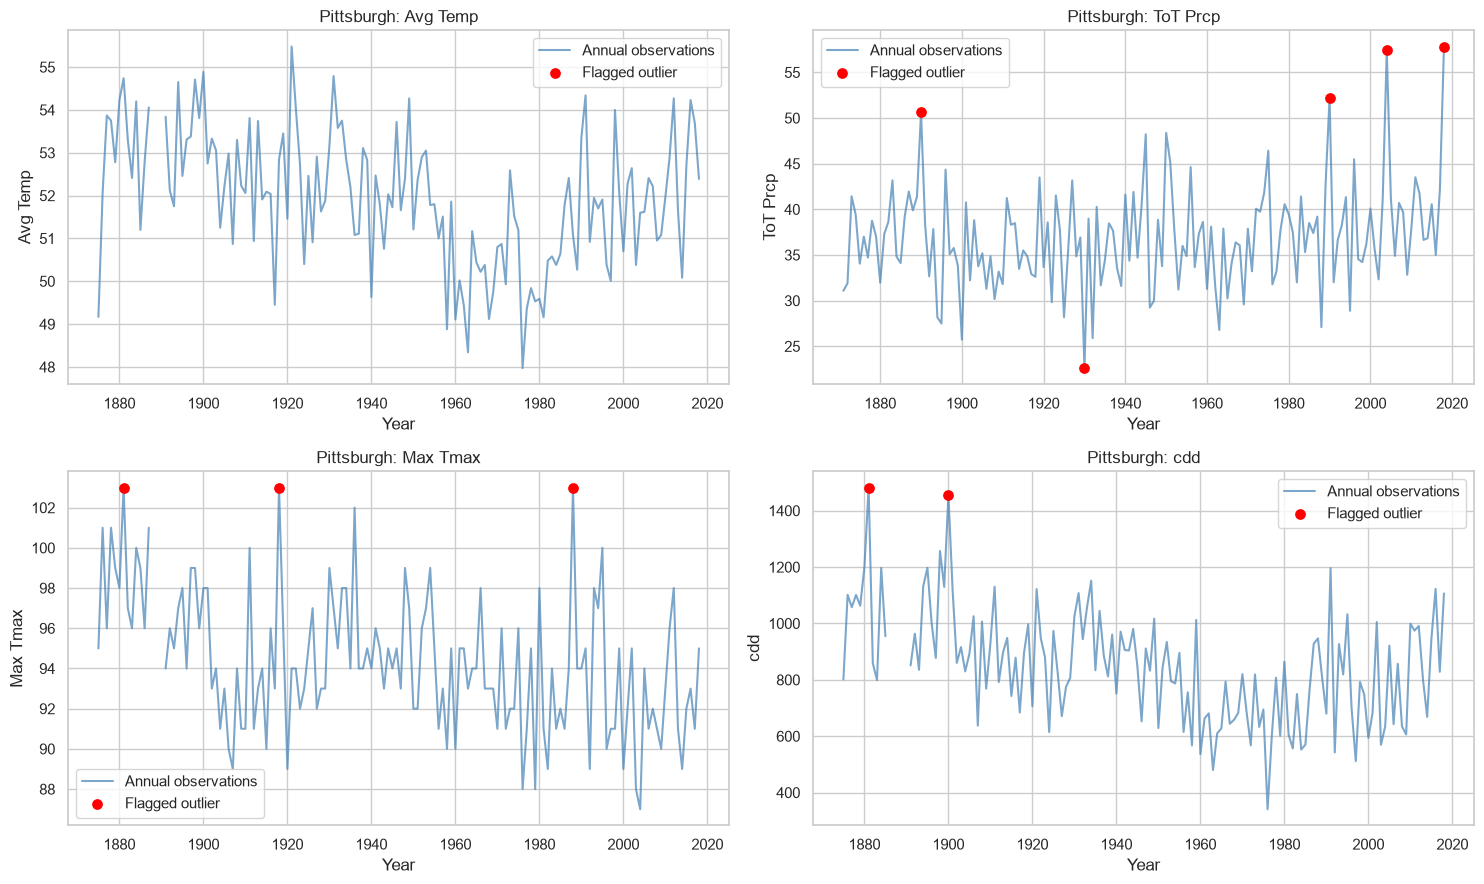

In [65]:
selected_city = "Pittsburgh"

if selected_city not in eda["Name"].values:
    selected_city = eda["Name"].iloc[0]

city_data = (
    eda[eda["Name"] == selected_city]
    .sort_values("Year")
)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for ax, target in zip(axes.flatten(), targets):

    col = clean_targets[target]
    flag_col = f"{target}_outlier"

    ax.plot(
        city_data["Year"],
        city_data[col],
        color="steelblue",
        alpha=0.7,
        label="Annual observations"
    )

    flagged = city_data[city_data[flag_col]]

    ax.scatter(
        flagged["Year"],
        flagged[col],
        color="red",
        s=45,
        label="Flagged outlier",
        zorder=3
    )

    ax.set_title(f"{selected_city}: {target}")
    ax.set_xlabel("Year")
    ax.set_ylabel(target)

    ax.legend()

plt.tight_layout()
plt.show()

In [66]:
outlier_cols = [
    f"{target}_outlier"
    for target in targets
]

city_outliers = (
    eda.groupby(["ID", "Name"])[outlier_cols]
    .sum()
    .reset_index()
)

city_outliers["total_outlier_flags"] = (
    city_outliers[outlier_cols].sum(axis=1)
)

display(
    city_outliers
    .sort_values("total_outlier_flags", ascending=False)
    .head(15)
)

,ID,Name,Avg Temp_outlier,ToT Prcp_outlier,Max Tmax_outlier,cdd_outlier,total_outlier_flags
171,USW00093193,Fresno,3,2,10,3,18
0,USC00042863,Escondido,5,4,2,5,16
140,USW00023185,Reno,0,0,4,12,16
116,USW00014929,Aberdeen,4,5,2,4,15
59,USW00013893,Memphis,2,0,9,4,15
191,USW00094224,Astoria,6,2,2,5,15
141,USW00023188,SanDiego,3,4,2,5,14
129,USW00023044,ElPaso,4,6,1,3,14
138,USW00023179,Needles,3,6,1,3,13
36,USW00012923,Galveston,3,1,2,7,13


In [67]:
final_summary = []

for target in targets:

    col = clean_targets[target]
    valid_values = eda[col].dropna()

    final_summary.append({
        "Target": target,
        "Valid Observations": len(valid_values),
        "Mean": valid_values.mean(),
        "Median": valid_values.median(),
        "Std Dev": valid_values.std(),
        "Minimum": valid_values.min(),
        "Maximum": valid_values.max(),
        "Skewness": valid_values.skew(),
        "Flagged Outliers": eda[f"{target}_outlier"].sum()
    })

checkpoint3_report = pd.DataFrame(final_summary)

display(checkpoint3_report.round(2))

,Target,Valid Observations,Mean,Median,Std Dev,Minimum,Maximum,Skewness,Flagged Outliers
0,Avg Temp,24583,55.14,53.38,8.91,32.02,79.97,0.39,298
1,ToT Prcp,24858,34.24,34.80,16.24,0.03,114.03,0.25,355
2,Max Tmax,24868,98.50,98.00,5.83,69.00,125.00,0.17,299
3,cdd,23974,1315.86,1023.50,979.99,0.00,5538.75,1.17,318


### Historical Trend Analysis

In [68]:
from scipy.stats import linregress

sns.set_theme(style="whitegrid")

targets = ["Avg Temp", "ToT Prcp", "Max Tmax", "cdd"]

clean_targets = {
    "Avg Temp": "Avg Temp_clean",
    "ToT Prcp": "ToT Prcp_clean",
    "Max Tmax": "Max Tmax_clean",
    "cdd": "cdd_clean"
}

# Work on a copy
trend_df = eda.copy()

trend_df = trend_df.sort_values(
    ["ID", "Year"]
).reset_index(drop=True)

print("Number of cities:", trend_df["ID"].nunique())
print("Year range:", trend_df["Year"].min(), "-", trend_df["Year"].max())

Number of cities: 210
Year range: 1851 - 2018


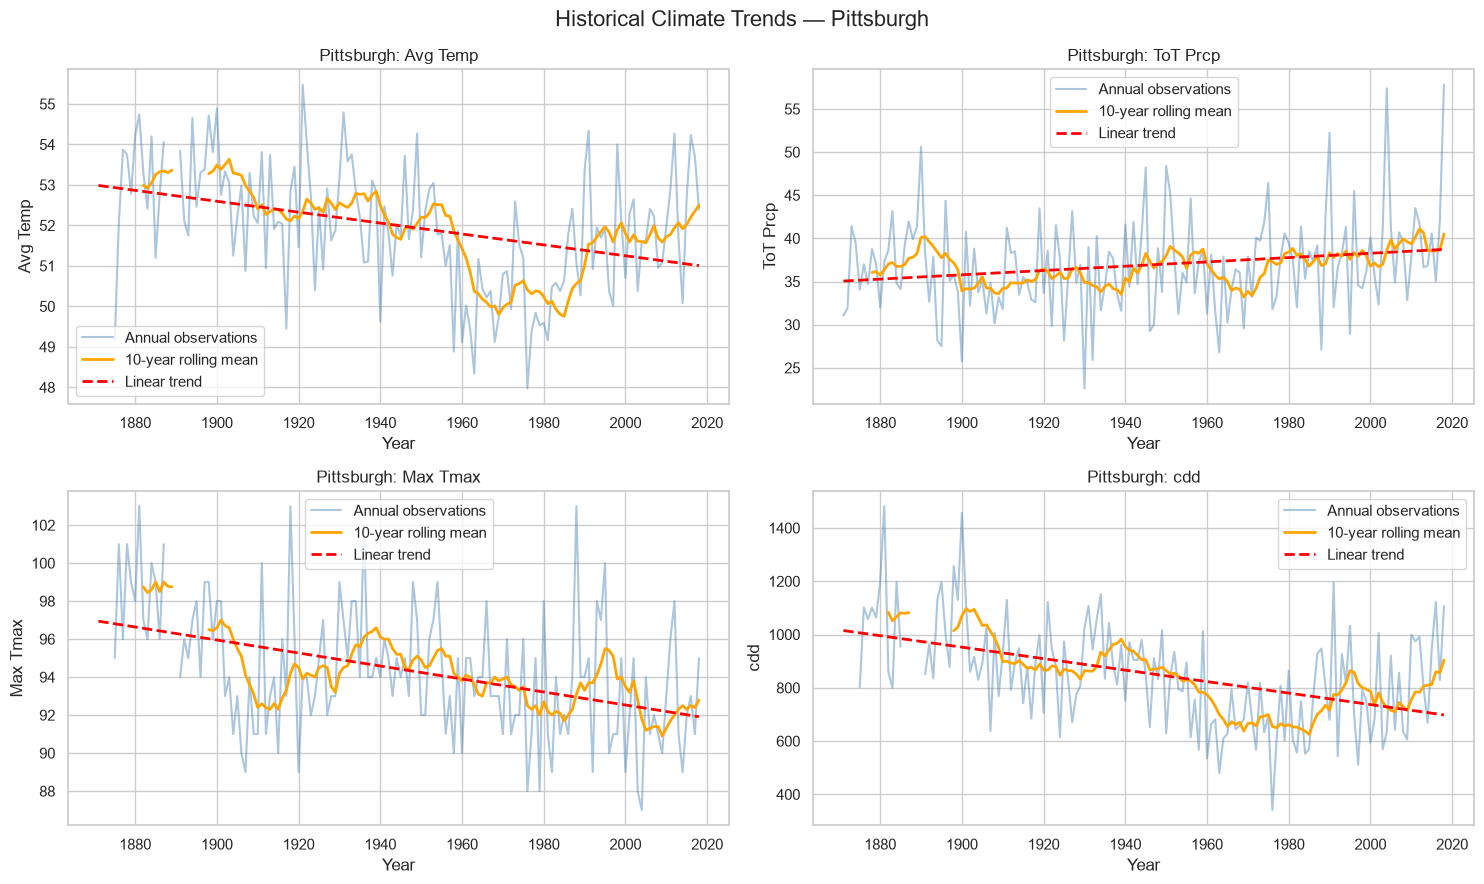

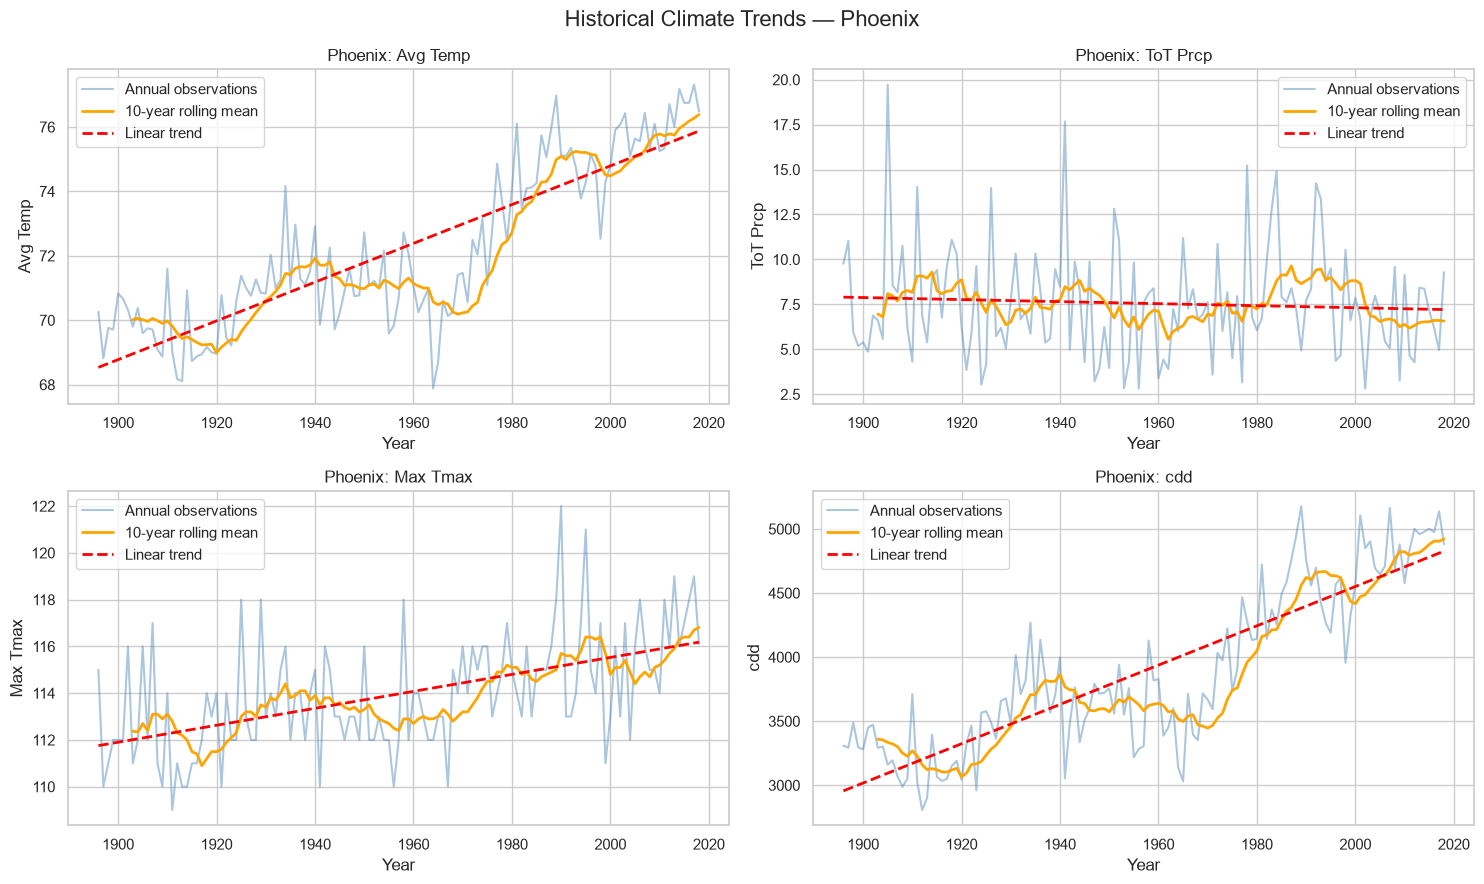

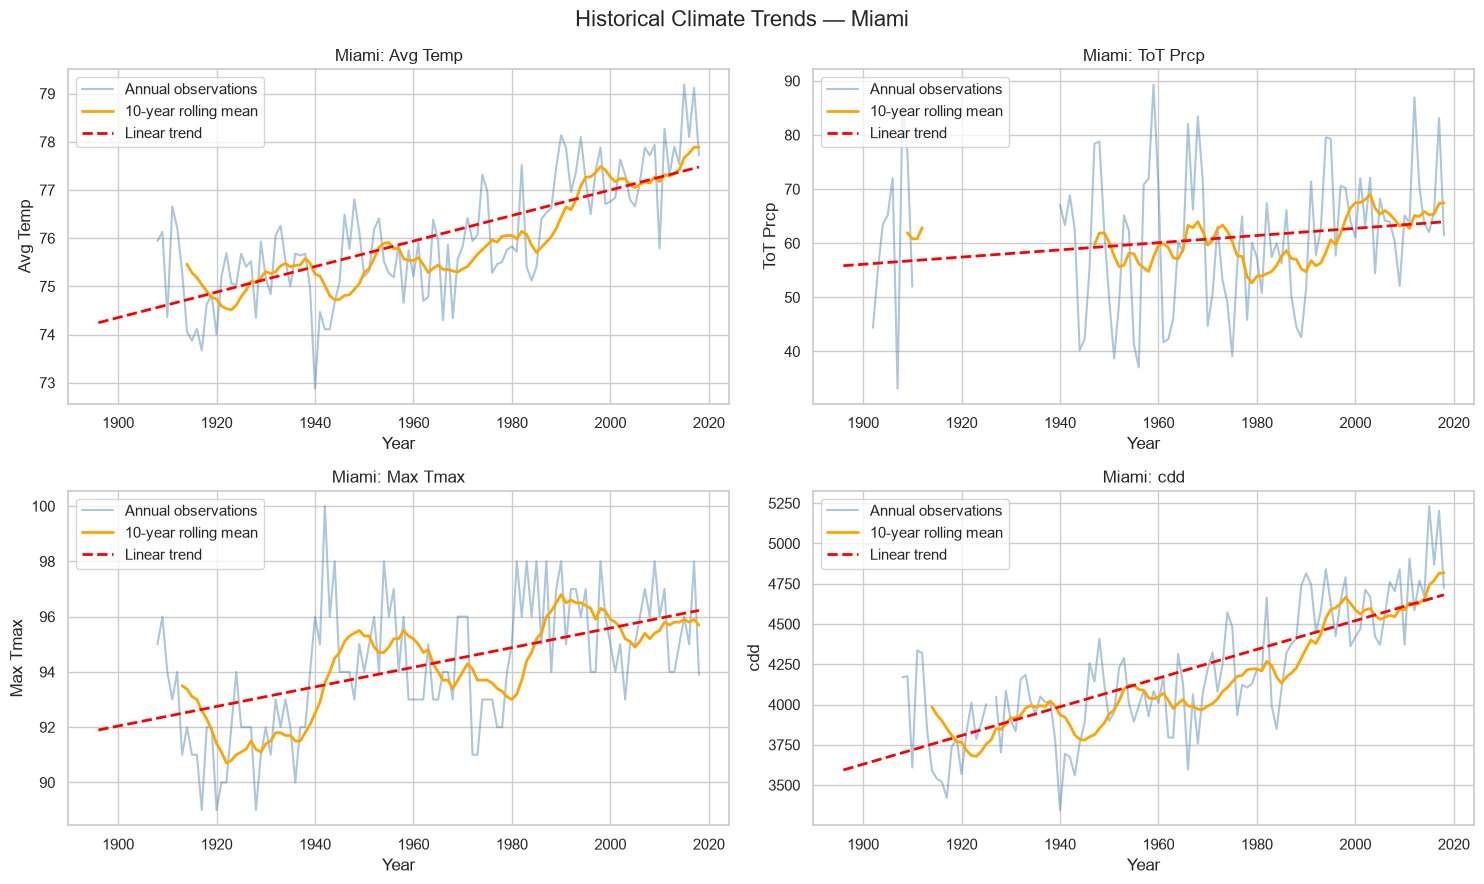

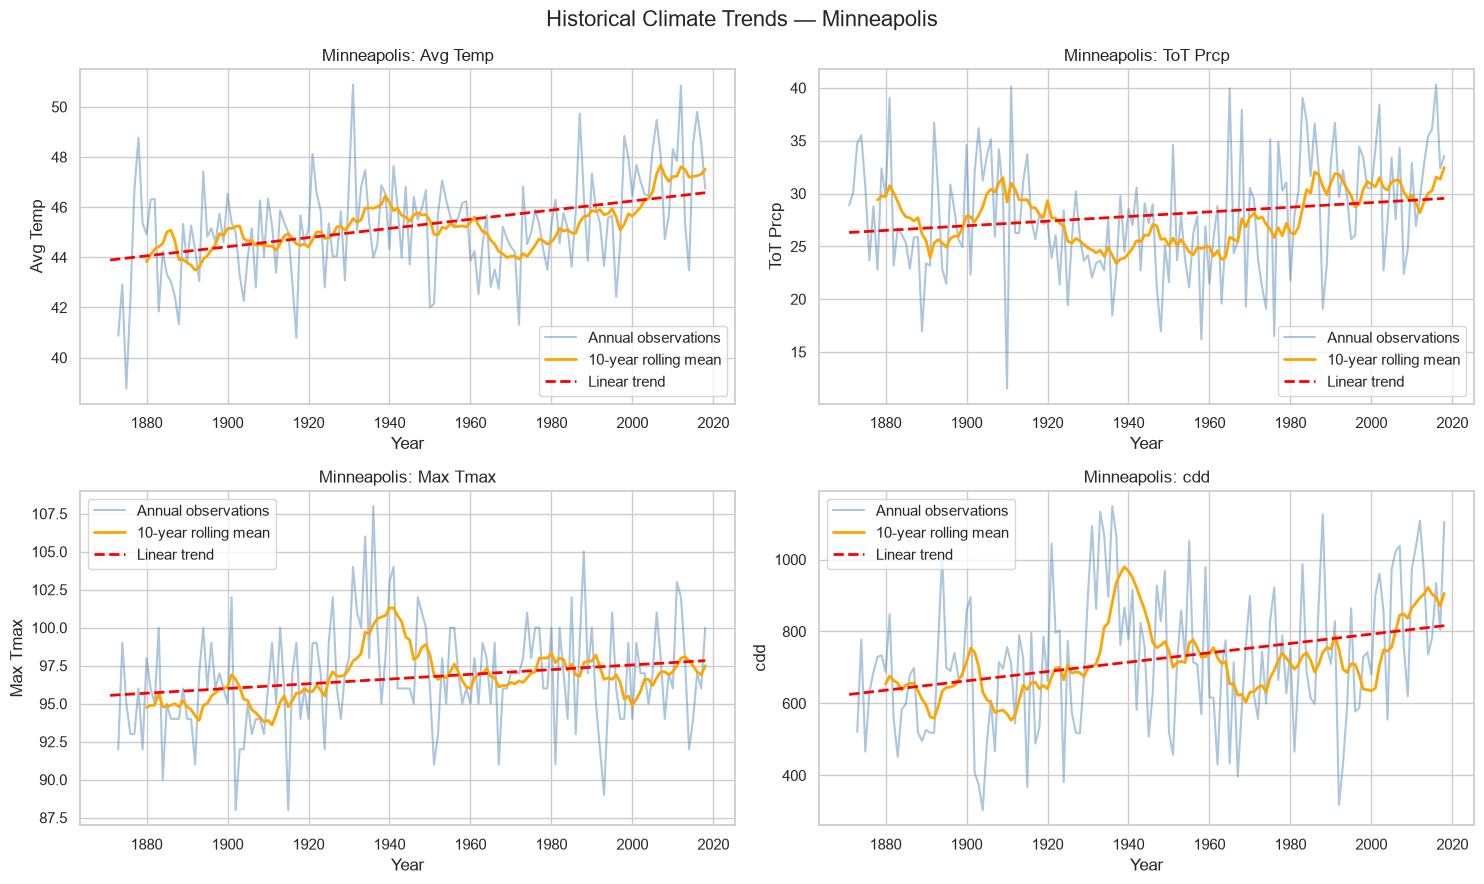

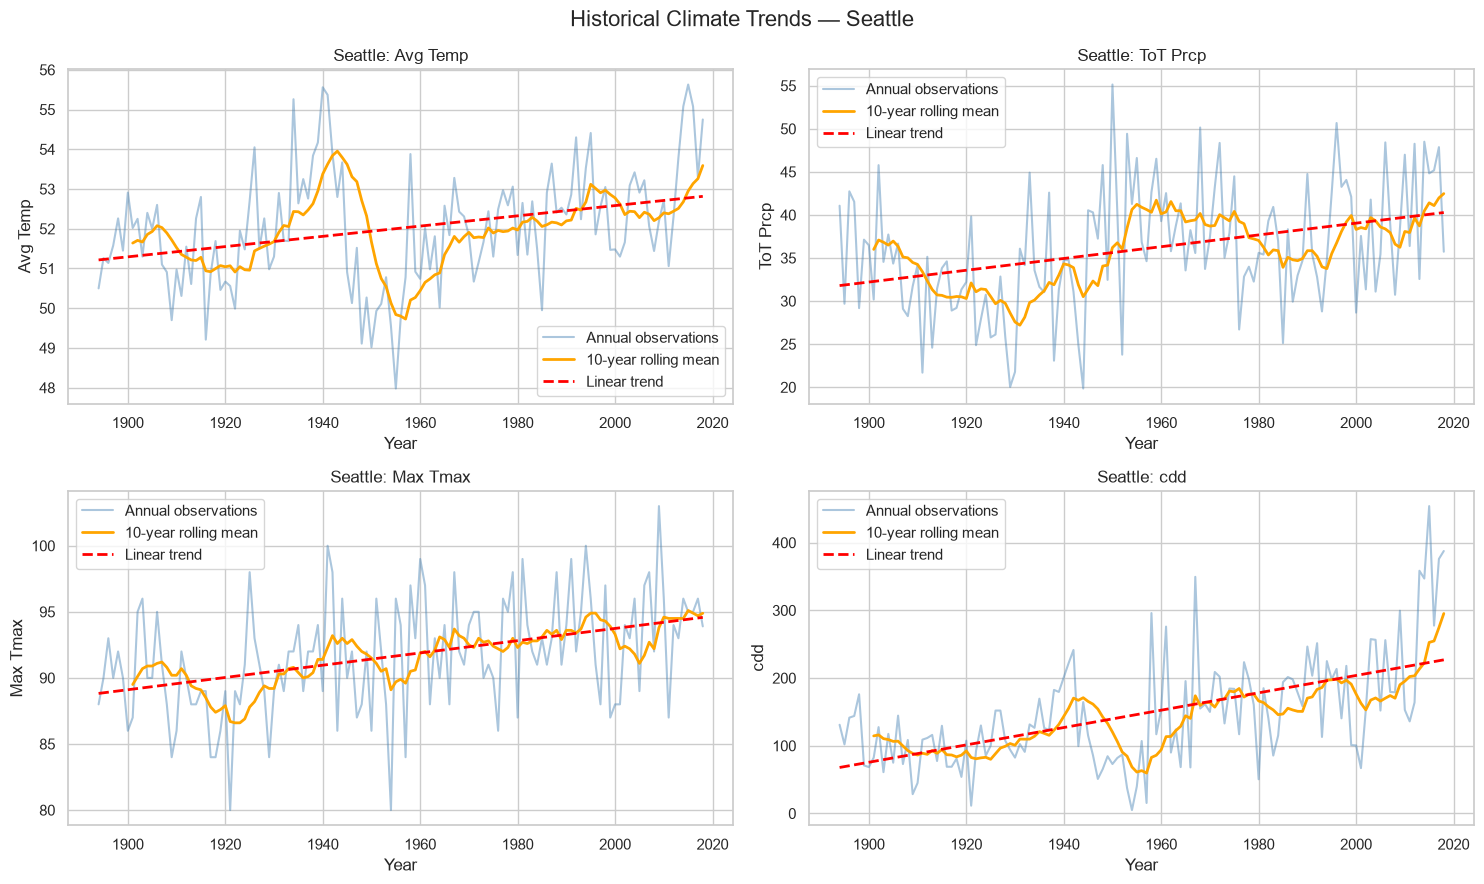

In [69]:
selected_cities = [
    "Pittsburgh",
    "Phoenix",
    "Miami",
    "Minneapolis",
    "Seattle"
]

# Keep only cities available in dataset
selected_cities = [
    city for city in selected_cities
    if city in trend_df["Name"].unique()
]

for city in selected_cities:

    city_data = (
        trend_df[trend_df["Name"] == city]
        .sort_values("Year")
        .copy()
    )

    fig, axes = plt.subplots(2, 2, figsize=(15, 9))

    for ax, target in zip(axes.flatten(), targets):

        col = clean_targets[target]

        # Annual observations
        ax.plot(
            city_data["Year"],
            city_data[col],
            alpha=0.45,
            color="steelblue",
            label="Annual observations"
        )

        # 10-year rolling mean
        # Require at least 8 valid observations
        rolling_mean = (
            city_data[col]
            .rolling(window=10, min_periods=8)
            .mean()
        )

        ax.plot(
            city_data["Year"],
            rolling_mean,
            color="orange",
            linewidth=2,
            label="10-year rolling mean"
        )

        # Linear trend
        valid = city_data[["Year", col]].dropna()

        if len(valid) >= 20:

            slope, intercept, r, p, stderr = linregress(
                valid["Year"],
                valid[col]
            )

            trend_line = (
                intercept + slope * city_data["Year"]
            )

            ax.plot(
                city_data["Year"],
                trend_line,
                color="red",
                linestyle="--",
                linewidth=2,
                label="Linear trend"
            )

        ax.set_title(f"{city}: {target}")
        ax.set_xlabel("Year")
        ax.set_ylabel(target)
        ax.legend()

    plt.suptitle(
        f"Historical Climate Trends — {city}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

In [70]:
periods = {
    "Full History": (1851, 2018),
    "1950–2018": (1950, 2018),
    "1989–2018": (1989, 2018)
}

def calculate_trend(data, target_col, min_years=20):

    valid = (
        data[["Year", target_col]]
        .dropna()
        .sort_values("Year")
    )

    if len(valid) < min_years:
        return {
            "slope_per_decade": np.nan,
            "r_squared": np.nan,
            "p_value": np.nan,
            "valid_years": len(valid)
        }

    result = linregress(
        valid["Year"],
        valid[target_col]
    )

    return {
        "slope_per_decade": result.slope * 10,
        "r_squared": result.rvalue ** 2,
        "p_value": result.pvalue,
        "valid_years": len(valid)
    }


trend_results = []

for (city_id, city_name), city_data in trend_df.groupby(
    ["ID", "Name"]
):

    for period_name, (start, end) in periods.items():

        period_data = city_data[
            city_data["Year"].between(start, end)
        ]

        for target in targets:

            result = calculate_trend(
                period_data,
                clean_targets[target]
            )

            trend_results.append({
                "ID": city_id,
                "Name": city_name,
                "Period": period_name,
                "Target": target,
                **result
            })


trend_results = pd.DataFrame(trend_results)

display(trend_results.head())

,ID,Name,Period,Target,slope_per_decade,r_squared,p_value,valid_years
0,USC00042863,Escondido,Full History,Avg Temp,0.452711,0.552779,1.242966e-15,82
1,USC00042863,Escondido,Full History,ToT Prcp,-0.421689,0.046058,4.223000e-02,90
2,USC00042863,Escondido,Full History,Max Tmax,-0.203907,0.035773,8.878856e-02,82
3,USC00042863,Escondido,Full History,cdd,58.110971,0.402168,4.570713e-10,78
4,USC00042863,Escondido,1950–2018,Avg Temp,0.891637,0.803450,1.227453e-14,39


In [71]:
pittsburgh_trends = trend_results[
    trend_results["Name"] == "Pittsburgh"
]

display(
    pittsburgh_trends.pivot(
        index="Target",
        columns="Period",
        values="slope_per_decade"
    ).round(3)
)

Period,1950–2018,1989–2018,Full History
Target,,,
Avg Temp,0.280,0.310,-0.135
Max Tmax,-0.244,-0.643,-0.342
ToT Prcp,0.670,1.132,0.249
cdd,25.376,50.094,-21.541


In [72]:
trend_summary = (
    trend_results
    .groupby(["Target", "Period"])
    .agg(
        cities_with_trends=("slope_per_decade", "count"),
        mean_slope=("slope_per_decade", "mean"),
        median_slope=("slope_per_decade", "median"),
        std_slope=("slope_per_decade", "std")
    )
    .reset_index()
)

display(trend_summary.round(3))

,Target,Period,cities_with_trends,mean_slope,median_slope,std_slope
0,Avg Temp,1950–2018,207,0.283,0.280,0.190
1,Avg Temp,1989–2018,200,0.526,0.538,0.317
2,Avg Temp,Full History,210,0.095,0.076,0.122
3,Max Tmax,1950–2018,207,0.074,0.050,0.311
4,Max Tmax,1989–2018,200,0.301,0.287,0.639
5,Max Tmax,Full History,210,0.017,0.047,0.251
6,ToT Prcp,1950–2018,206,0.496,0.454,0.708
7,ToT Prcp,1989–2018,204,0.491,0.393,1.703
8,ToT Prcp,Full History,209,0.164,0.140,0.357
9,cdd,1950–2018,207,32.870,24.778,35.366


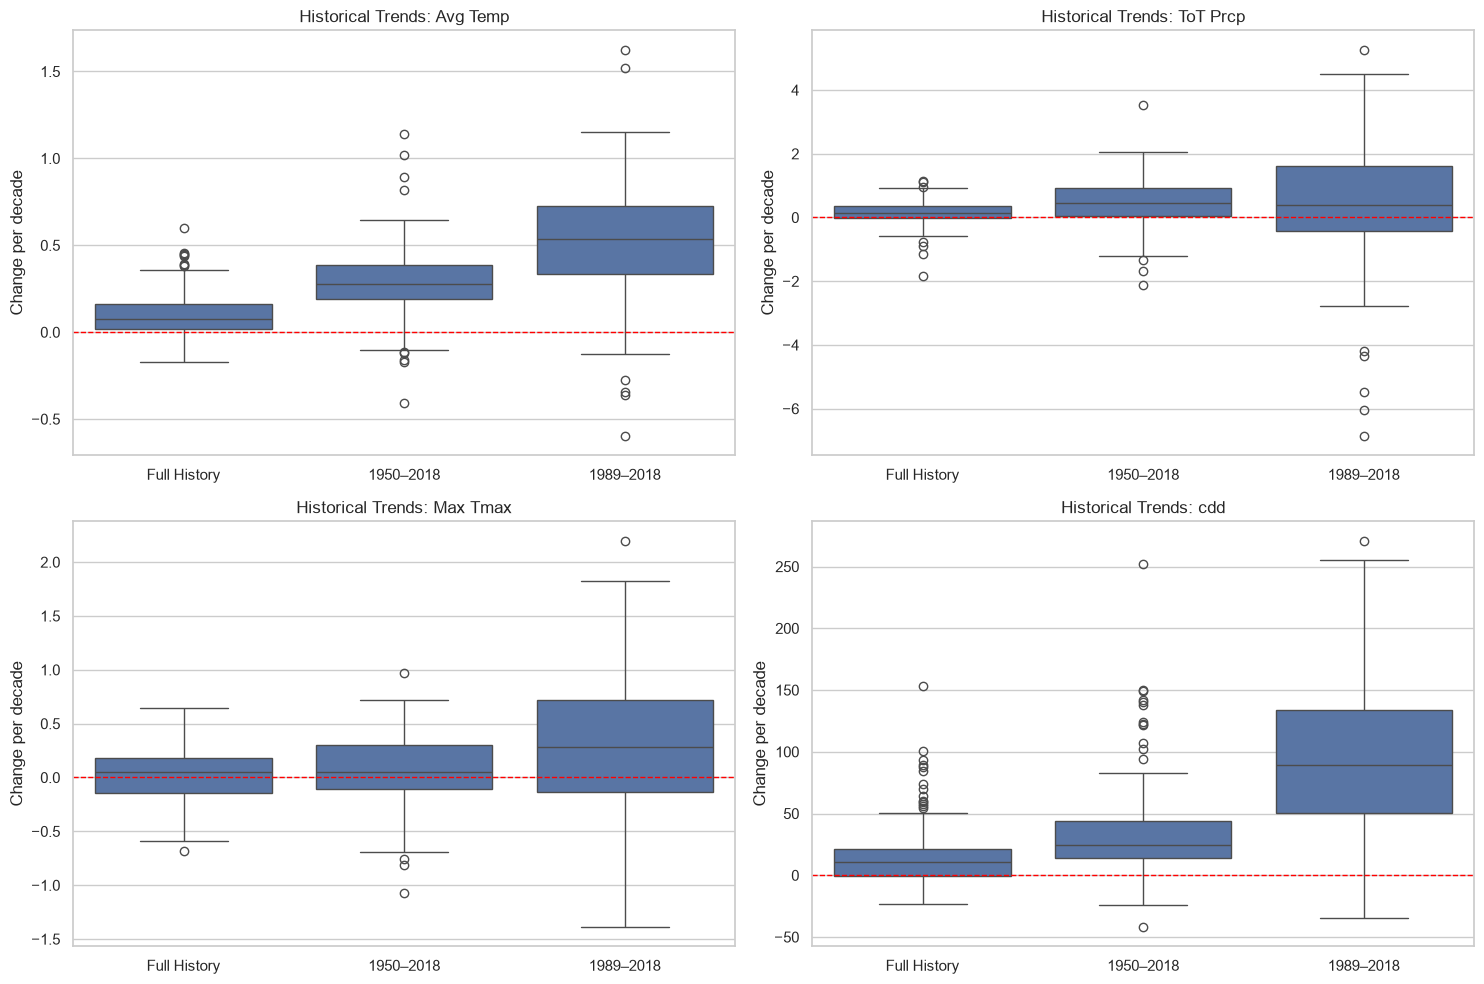

In [73]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, target in zip(axes.flatten(), targets):

    subset = trend_results[
        trend_results["Target"] == target
    ]

    sns.boxplot(
        data=subset,
        x="Period",
        y="slope_per_decade",
        order=list(periods.keys()),
        ax=ax
    )

    ax.axhline(
        0,
        color="red",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"Historical Trends: {target}")
    ax.set_xlabel("")
    ax.set_ylabel("Change per decade")

plt.tight_layout()
plt.show()

In [74]:
recent_temp_trends = (
    trend_results[
        (trend_results["Period"] == "1989–2018") &
        (trend_results["Target"] == "Avg Temp")
    ]
    .dropna(subset=["slope_per_decade"])
    .copy()
)

strongest_warming = (
    recent_temp_trends
    .sort_values("slope_per_decade", ascending=False)
    .head(15)
)

strongest_cooling = (
    recent_temp_trends
    .sort_values("slope_per_decade", ascending=True)
    .head(15)
)

print("Cities with strongest positive temperature trends:")
display(strongest_warming.round(3))

print("\nCities with strongest negative temperature trends:")
display(strongest_cooling.round(3))

Cities with strongest positive temperature trends:


,ID,Name,Period,Target,slope_per_decade,r_squared,p_value,valid_years
1688,USW00023185,Reno,1989–2018,Avg Temp,1.625,0.661,0.000,30
1808,USW00024121,Elko,1989–2018,Avg Temp,1.522,0.567,0.000,30
1640,USW00023155,Bakersfield,1989–2018,Avg Temp,1.150,0.410,0.000,30
1208,USW00014847,SaultSteMarie,1989–2018,Avg Temp,1.146,0.226,0.008,30
1100,USW00014792,Trenton,1989–2018,Avg Temp,1.106,0.212,0.041,20
1412,USW00014933,DesMoines,1989–2018,Avg Temp,1.105,0.254,0.005,30
1556,USW00023044,ElPaso,1989–2018,Avg Temp,1.044,0.504,0.000,30
1352,USW00014922,Minneapolis,1989–2018,Avg Temp,1.013,0.193,0.015,30
1664,USW00023179,Needles,1989–2018,Avg Temp,1.012,0.418,0.000,29
2504,USW00094950,Mitchell,1989–2018,Avg Temp,1.007,0.177,0.029,27



Cities with strongest negative temperature trends:


,ID,Name,Period,Target,slope_per_decade,r_squared,p_value,valid_years
2312,USW00094236,KlamathFalls,1989–2018,Avg Temp,-0.598,0.074,0.234,21
1928,USW00024163,TriCities,1989–2018,Avg Temp,-0.361,0.065,0.173,30
1940,USW00024213,Eureka,1989–2018,Avg Temp,-0.345,0.084,0.120,30
2000,USW00024286,CrescentCity,1989–2018,Avg Temp,-0.277,0.047,0.286,26
2480,USW00094929,Ashland,1989–2018,Avg Temp,-0.128,0.004,0.758,25
2228,USW00093988,PineBluff,1989–2018,Avg Temp,-0.103,0.006,0.676,30
2048,USW00093134,LosAngeles,1989–2018,Avg Temp,-0.074,0.002,0.798,30
656,USW00013881,Charlotte,1989–2018,Avg Temp,-0.015,0.000,0.957,30
1328,USW00014918,InternationalFalls,1989–2018,Avg Temp,0.008,0.000,0.984,30
488,USW00013733,Lynchburg,1989–2018,Avg Temp,0.030,0.001,0.905,30


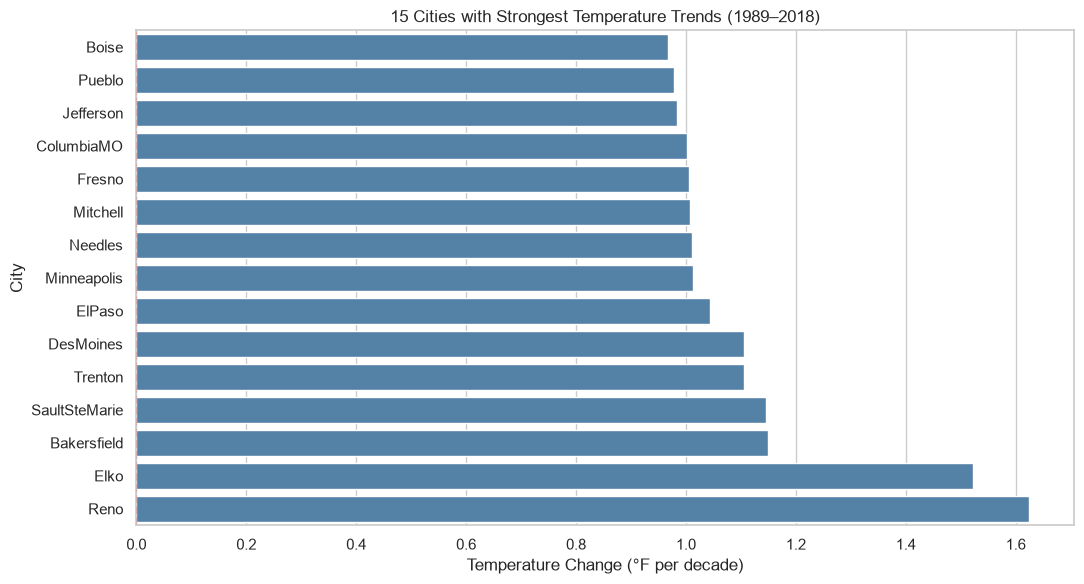

In [75]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=strongest_warming.sort_values("slope_per_decade"),
    x="slope_per_decade",
    y="Name",
    color="steelblue"
)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Temperature Change (°F per decade)")
plt.ylabel("City")
plt.title("15 Cities with Strongest Temperature Trends (1989–2018)")

plt.tight_layout()
plt.show()

In [76]:
temp_trend_comparison = (
    trend_results[
        trend_results["Target"] == "Avg Temp"
    ]
    .pivot(
        index=["ID", "Name"],
        columns="Period",
        values="slope_per_decade"
    )
    .reset_index()
)

temp_trend_comparison["Recent Minus Historical"] = (
    temp_trend_comparison["1989–2018"] -
    temp_trend_comparison["Full History"]
)

display(
    temp_trend_comparison
    .sort_values(
        "Recent Minus Historical",
        ascending=False
    )
    .head(15)
    .round(3)
)

Period,ID,Name,1950–2018,1989–2018,Full History,Recent Minus Historical
150,USW00024121,Elko,0.351,1.522,0.163,1.360
140,USW00023185,Reno,1.139,1.625,0.387,1.237
208,USW00094950,Mitchell,0.108,1.007,0.016,0.991
25,USW00003963,Jefferson,0.176,0.984,0.000,0.984
117,USW00014933,DesMoines,0.471,1.105,0.136,0.970
91,USW00014792,Trenton,0.125,1.106,0.141,0.966
22,USW00003945,ColumbiaMO,0.574,1.002,0.041,0.961
100,USW00014847,SaultSteMarie,0.520,1.146,0.193,0.953
136,USW00023155,Bakersfield,0.222,1.150,0.219,0.931
129,USW00023044,ElPaso,0.435,1.044,0.161,0.882


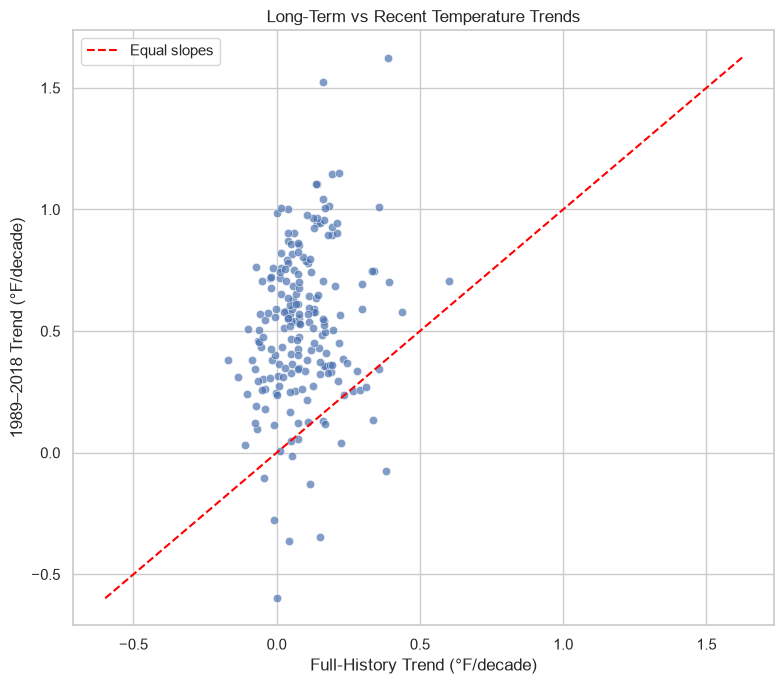

In [77]:
comparison = temp_trend_comparison.dropna(
    subset=["Full History", "1989–2018"]
)

plt.figure(figsize=(8, 7))

sns.scatterplot(
    data=comparison,
    x="Full History",
    y="1989–2018",
    alpha=0.7
)

limits = [
    min(
        comparison["Full History"].min(),
        comparison["1989–2018"].min()
    ),
    max(
        comparison["Full History"].max(),
        comparison["1989–2018"].max()
    )
]

plt.plot(
    limits,
    limits,
    color="red",
    linestyle="--",
    label="Equal slopes"
)

plt.xlabel("Full-History Trend (°F/decade)")
plt.ylabel("1989–2018 Trend (°F/decade)")
plt.title("Long-Term vs Recent Temperature Trends")
plt.legend()
plt.tight_layout()
plt.show()

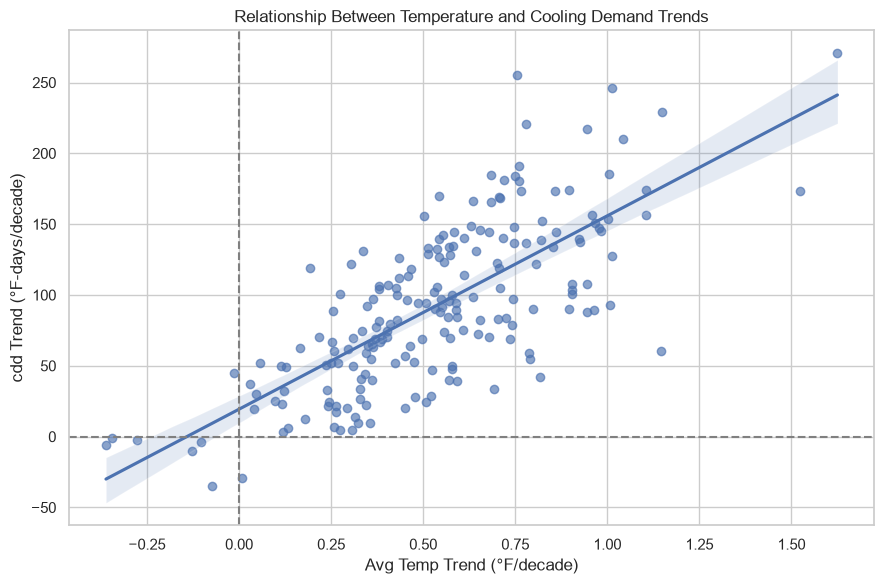

Correlation: 0.7304963041150941


In [78]:
recent_trends = trend_results[
    trend_results["Period"] == "1989–2018"
]

temp_cdd_trends = (
    recent_trends[
        recent_trends["Target"].isin(["Avg Temp", "cdd"])
    ]
    .pivot(
        index=["ID", "Name"],
        columns="Target",
        values="slope_per_decade"
    )
    .dropna()
    .reset_index()
)

plt.figure(figsize=(9, 6))

sns.regplot(
    data=temp_cdd_trends,
    x="Avg Temp",
    y="cdd",
    scatter_kws={"alpha": 0.65}
)

plt.axhline(0, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")

plt.xlabel("Avg Temp Trend (°F/decade)")
plt.ylabel("cdd Trend (°F-days/decade)")
plt.title("Relationship Between Temperature and Cooling Demand Trends")

plt.tight_layout()
plt.show()

print(
    "Correlation:",
    temp_cdd_trends["Avg Temp"].corr(temp_cdd_trends["cdd"])
)

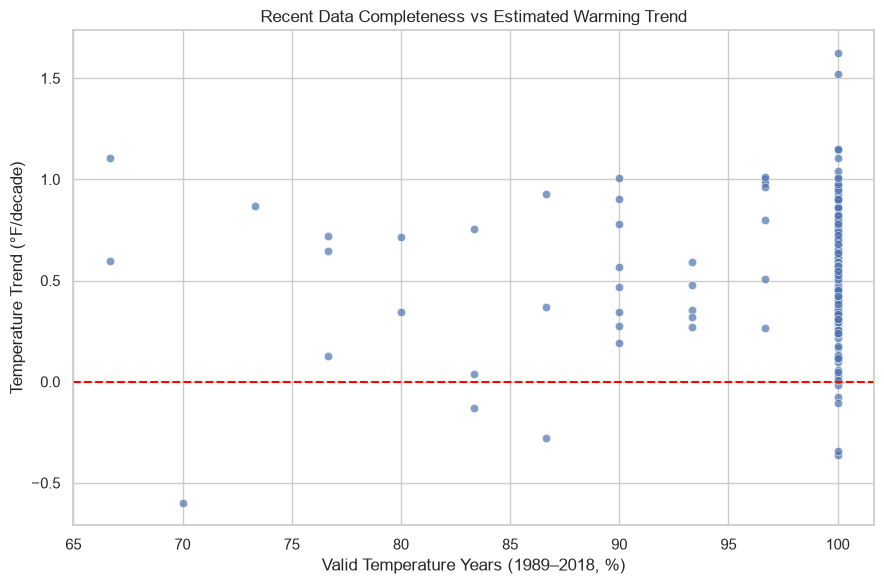

In [79]:
recent_quality = (
    trend_df[
        trend_df["Year"].between(1989, 2018)
    ]
    .groupby(["ID", "Name"])
    .agg(
        valid_temp_years=("Avg Temp_clean", "count")
    )
    .reset_index()
)

recent_quality["valid_temp_pct"] = (
    recent_quality["valid_temp_years"] / 30 * 100
)

quality_vs_trend = recent_temp_trends.merge(
    recent_quality,
    on=["ID", "Name"],
    how="left"
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=quality_vs_trend,
    x="valid_temp_pct",
    y="slope_per_decade",
    alpha=0.7
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Valid Temperature Years (1989–2018, %)")
plt.ylabel("Temperature Trend (°F/decade)")
plt.title("Recent Data Completeness vs Estimated Warming Trend")

plt.tight_layout()
plt.show()

In [80]:
final_trend_report = (
    trend_results
    .groupby(["Target", "Period"])
    .agg(
        cities_analyzed=("slope_per_decade", "count"),
        median_trend=("slope_per_decade", "median"),
        mean_trend=("slope_per_decade", "mean"),
        std_trend=("slope_per_decade", "std"),
        median_r_squared=("r_squared", "median"),
        positive_trend_cities=(
            "slope_per_decade",
            lambda x: (x > 0).sum()
        ),
        negative_trend_cities=(
            "slope_per_decade",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

final_trend_report["positive_trend_pct"] = (
    final_trend_report["positive_trend_cities"] /
    final_trend_report["cities_analyzed"] * 100
)

display(final_trend_report.round(3))

,Target,Period,cities_analyzed,median_trend,mean_trend,std_trend,median_r_squared,positive_trend_cities,negative_trend_cities,positive_trend_pct
0,Avg Temp,1950–2018,207,0.280,0.283,0.190,0.155,192,15,92.754
1,Avg Temp,1989–2018,200,0.538,0.526,0.317,0.109,192,8,96.000
2,Avg Temp,Full History,210,0.076,0.095,0.122,0.051,169,41,80.476
3,Max Tmax,1950–2018,207,0.050,0.074,0.311,0.015,120,87,57.971
4,Max Tmax,1989–2018,200,0.287,0.301,0.639,0.018,139,61,69.500
5,Max Tmax,Full History,210,0.047,0.017,0.251,0.038,116,94,55.238
6,ToT Prcp,1950–2018,206,0.454,0.496,0.708,0.026,162,44,78.641
7,ToT Prcp,1989–2018,204,0.393,0.491,1.703,0.021,127,77,62.255
8,ToT Prcp,Full History,209,0.140,0.164,0.357,0.014,150,59,71.770
9,cdd,1950–2018,207,24.778,32.870,35.366,0.086,188,19,90.821


In [81]:
recent_report = final_trend_report[
    final_trend_report["Period"] == "1989–2018"
]

display(
    recent_report[
        [
            "Target",
            "cities_analyzed",
            "median_trend",
            "median_r_squared",
            "positive_trend_pct"
        ]
    ].round(3)
)

,Target,cities_analyzed,median_trend,median_r_squared,positive_trend_pct
1,Avg Temp,200,0.538,0.109,96.000
4,Max Tmax,200,0.287,0.018,69.500
7,ToT Prcp,204,0.393,0.021,62.255
10,cdd,196,89.457,0.162,96.429


### Difference Between Cities

In [82]:
sns.set_theme(style="whitegrid")

targets = ["Avg Temp", "ToT Prcp", "Max Tmax", "cdd"]

clean_targets = {
    "Avg Temp": "Avg Temp_clean",
    "ToT Prcp": "ToT Prcp_clean",
    "Max Tmax": "Max Tmax_clean",
    "cdd": "cdd_clean"
}

MIN_VALID_YEARS = 20

geo_df = eda[
    eda["Year"].between(1989, 2018)
].copy()

print("Cities:", geo_df["ID"].nunique())
print("Year range:", geo_df["Year"].min(), geo_df["Year"].max())

Cities: 210
Year range: 1989 2018


In [83]:
city_climate = (
    geo_df.groupby(["ID", "Name"])
    .agg(
        Lat=("Lat", "first"),
        Lon=("Lon", "first"),

        avg_temp=("Avg Temp_clean", "mean"),
        avg_temp_std=("Avg Temp_clean", "std"),
        temp_count=("Avg Temp_clean", "count"),

        avg_precip=("ToT Prcp_clean", "mean"),
        precip_std=("ToT Prcp_clean", "std"),
        precip_count=("ToT Prcp_clean", "count"),

        avg_hottest=("Max Tmax_clean", "mean"),
        hottest_std=("Max Tmax_clean", "std"),
        hottest_count=("Max Tmax_clean", "count"),

        avg_cdd=("cdd_clean", "mean"),
        cdd_std=("cdd_clean", "std"),
        cdd_count=("cdd_clean", "count")
    )
    .reset_index()
)

# Mark summaries based on insufficient observations
metric_columns = {
    "temp": ["avg_temp", "avg_temp_std"],
    "precip": ["avg_precip", "precip_std"],
    "hottest": ["avg_hottest", "hottest_std"],
    "cdd": ["avg_cdd", "cdd_std"]
}

for metric, cols in metric_columns.items():

    insufficient = city_climate[f"{metric}_count"] < MIN_VALID_YEARS

    city_climate.loc[insufficient, cols] = np.nan

display(city_climate.head())

,ID,Name,Lat,Lon,avg_temp,avg_temp_std,temp_count,avg_precip,precip_std,precip_count,avg_hottest,hottest_std,hottest_count,avg_cdd,cdd_std,cdd_count
0,USC00042863,Escondido,33.1211,-117.0900,NaN,NaN,10,13.031818,6.007999,22,NaN,NaN,10,NaN,NaN,8
1,USC00166584,Natchitoches,31.8142,-93.0856,66.592917,1.624961,24,56.777241,10.147871,29,100.773077,4.144737,26,2599.909524,343.573321,21
2,USC00280734,Belvidere,40.8292,-75.0833,NaN,NaN,4,44.915000,7.510848,22,NaN,NaN,16,NaN,NaN,3
3,USC00286055,NewBrunswick,40.4728,-74.4225,53.609667,1.379439,30,49.499000,7.706053,30,97.500000,3.277404,30,994.475000,184.125102,30
4,USC00356749,Portland,45.5181,-122.6894,54.801739,1.091036,23,44.759600,10.290693,25,98.416667,2.717362,24,NaN,NaN,18


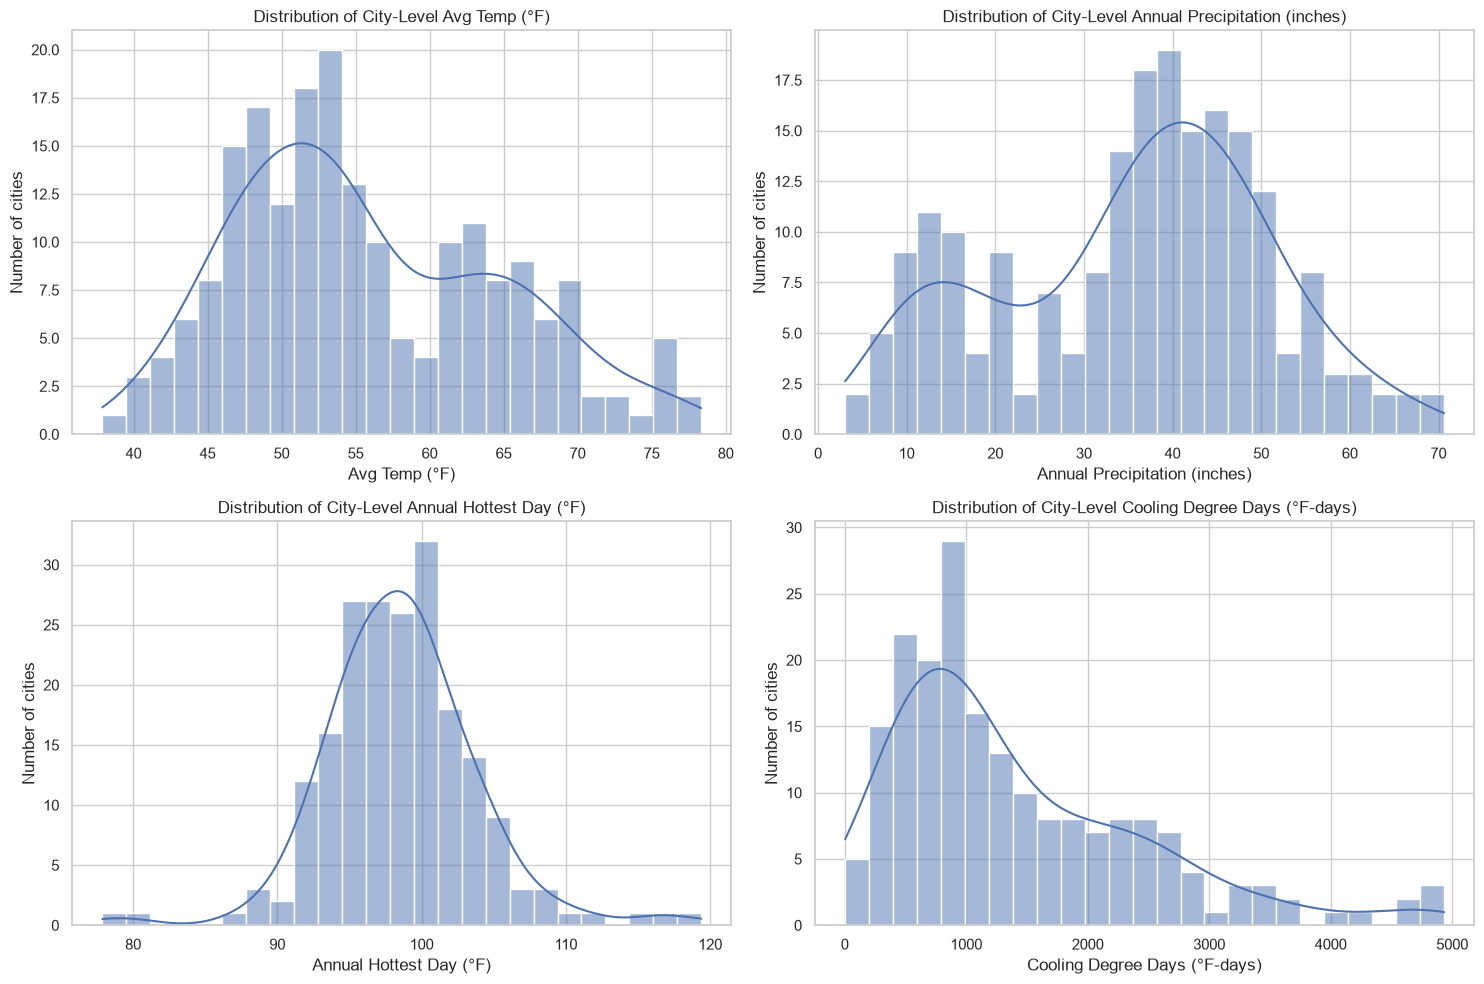

In [84]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

metrics = {
    "avg_temp": "Avg Temp (°F)",
    "avg_precip": "Annual Precipitation (inches)",
    "avg_hottest": "Annual Hottest Day (°F)",
    "avg_cdd": "Cooling Degree Days (°F-days)"
}

for ax, (col, label) in zip(axes.flatten(), metrics.items()):

    sns.histplot(
        city_climate[col].dropna(),
        bins=25,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of City-Level {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of cities")

plt.tight_layout()
plt.show()

In [85]:
comparisons = {
    "Warmest cities": ("avg_temp", False),
    "Coolest cities": ("avg_temp", True),
    "Wettest cities": ("avg_precip", False),
    "Driest cities": ("avg_precip", True),
    "Highest cooling demand": ("avg_cdd", False),
    "Lowest cooling demand": ("avg_cdd", True)
}

for title, (col, ascending) in comparisons.items():

    result = (
        city_climate[["Name", col]]
        .dropna()
        .sort_values(col, ascending=ascending)
        .head(10)
    )

    print(f"\n{title}")
    display(result.round(2))


Warmest cities


,Name,avg_temp
31,KeyWest,78.35
32,Miami,77.51
8,Yuma,76.06
34,WestPalmBeach,76.04
139,Phoenix,75.58
30,FortMyers,75.33
138,Needles,75.27
33,Tampa,73.92
28,Orlando,73.22
37,CorpusChristi,72.80



Coolest cities


,Name,avg_temp
110,InternationalFalls,37.89
107,Duluth,40.14
202,Marquette,40.42
109,GrandForks,40.52
206,Ashland,41.83
100,SaultSteMarie,41.88
188,Williston,41.91
108,Fargo,42.59
115,SaintCloud,43.20
144,Bismarck,43.24



Wettest cities


,Name,avg_precip
191,Astoria,70.62
63,Pensacola,68.04
48,Mobile,67.06
32,Miami,65.40
184,Gulfport,64.63
72,BatonRouge,62.66
173,CapeHatteras,61.04
34,WestPalmBeach,60.44
166,CrescentCity,59.99
47,Hattiesburg,59.31


... (2 outputs left out)


Highest cooling demand


,Name,avg_cdd
31,KeyWest,4932.67
138,Needles,4798.25
139,Phoenix,4736.29
8,Yuma,4706.01
32,Miami,4675.95
34,WestPalmBeach,4231.46
30,FortMyers,4021.62
33,Tampa,3741.00
37,CorpusChristi,3689.04
28,Orlando,3517.69



Lowest cooling demand


,Name,avg_cdd
161,Eureka,3.02
166,CrescentCity,3.28
191,Astoria,18.76
7,Flagstaff,134.41
110,InternationalFalls,193.66
100,SaultSteMarie,205.68
164,Seattle,220.79
107,Duluth,226.39
202,Marquette,243.03
135,Ely,251.18


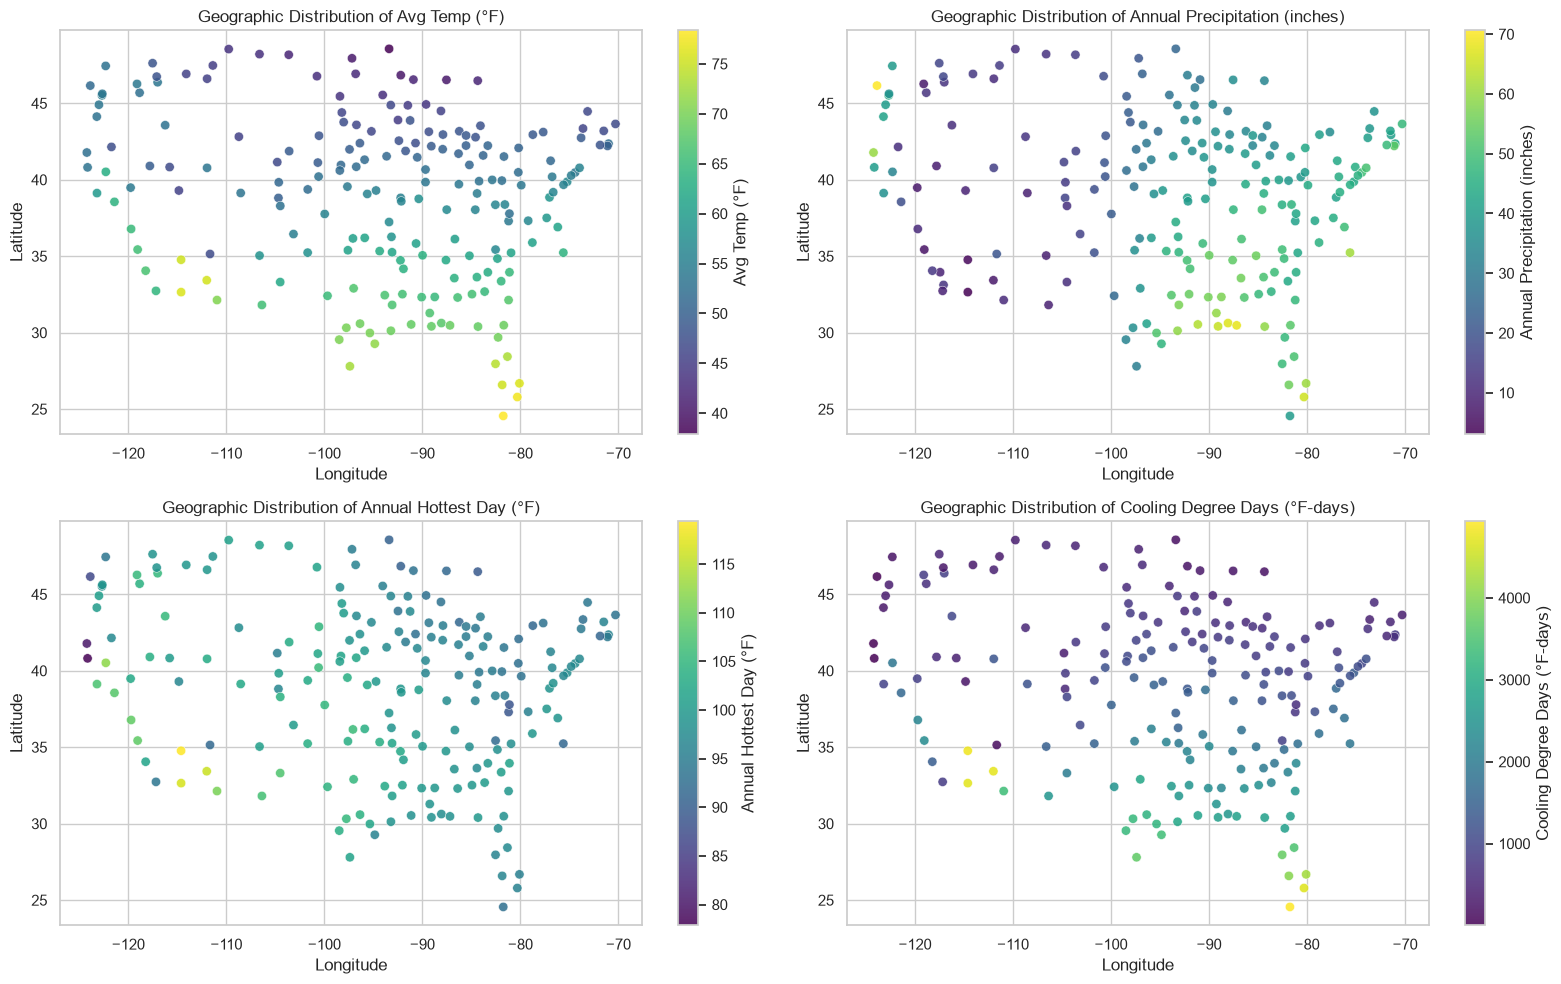

In [86]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (col, label) in zip(axes.flatten(), metrics.items()):

    valid = city_climate.dropna(subset=[col, "Lat", "Lon"])

    sc = ax.scatter(
        valid["Lon"],
        valid["Lat"],
        c=valid[col],
        cmap="viridis",
        s=45,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.4
    )

    plt.colorbar(sc, ax=ax, label=label)

    ax.set_title(f"Geographic Distribution of {label}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

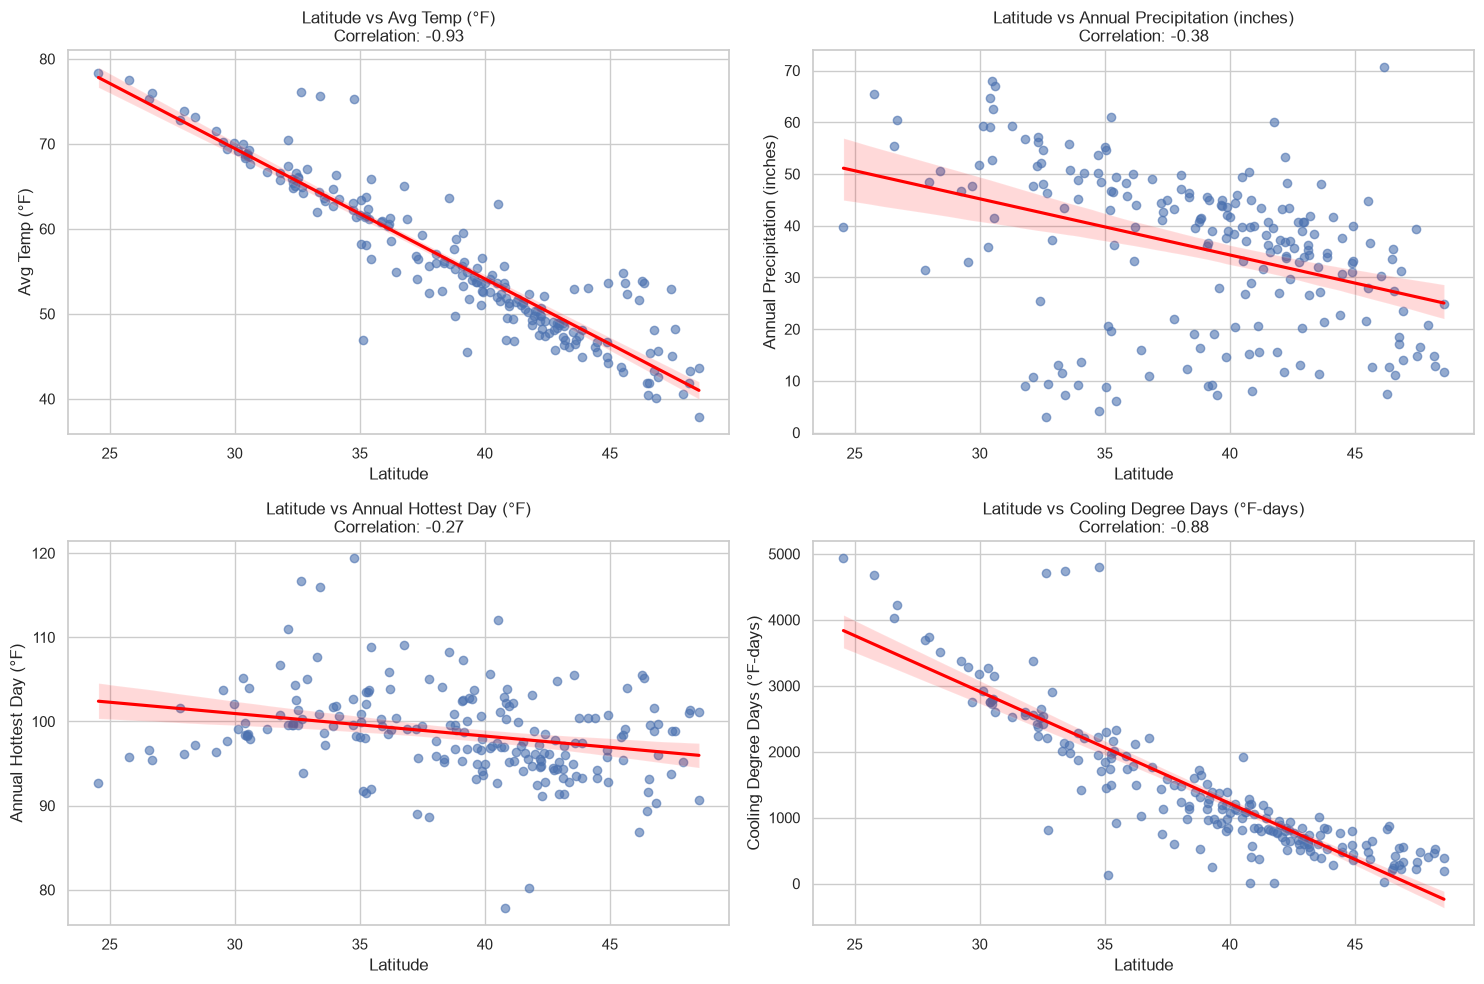

In [87]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (col, label) in zip(axes.flatten(), metrics.items()):

    valid = city_climate.dropna(subset=["Lat", col])

    sns.regplot(
        data=valid,
        x="Lat",
        y=col,
        scatter_kws={"alpha": 0.6},
        line_kws={"color": "red"},
        ax=ax
    )

    correlation = valid["Lat"].corr(valid[col])

    ax.set_title(
        f"Latitude vs {label}\nCorrelation: {correlation:.2f}"
    )

    ax.set_xlabel("Latitude")
    ax.set_ylabel(label)

plt.tight_layout()
plt.show()

In [88]:
recent_trends = trend_results[
    trend_results["Period"] == "1989–2018"
].copy()

trend_wide = (
    recent_trends
    .pivot(
        index=["ID", "Name"],
        columns="Target",
        values="slope_per_decade"
    )
    .reset_index()
)

trend_wide = trend_wide.rename(columns={
    "Avg Temp": "temp_trend",
    "ToT Prcp": "precip_trend",
    "Max Tmax": "hottest_trend",
    "cdd": "cdd_trend"
})

city_analysis = city_climate.merge(
    trend_wide,
    on=["ID", "Name"],
    how="left",
    validate="one_to_one"
)

# Remove trend estimates for cities with fewer than
# 20 valid observations for the corresponding target.
for metric, trend_col in {
    "temp": "temp_trend",
    "precip": "precip_trend",
    "hottest": "hottest_trend",
    "cdd": "cdd_trend"
}.items():

    city_analysis.loc[
        city_analysis[f"{metric}_count"] < MIN_VALID_YEARS,
        trend_col
    ] = np.nan

display(city_analysis.head())

,ID,Name,Lat,Lon,avg_temp,avg_temp_std,temp_count,avg_precip,precip_std,precip_count,avg_hottest,hottest_std,hottest_count,avg_cdd,cdd_std,cdd_count,temp_trend,hottest_trend,precip_trend,cdd_trend
0,USC00042863,Escondido,33.1211,-117.0900,NaN,NaN,10,13.031818,6.007999,22,NaN,NaN,10,NaN,NaN,8,NaN,NaN,-1.349102,NaN
1,USC00166584,Natchitoches,31.8142,-93.0856,66.592917,1.624961,24,56.777241,10.147871,29,100.773077,4.144737,26,2599.909524,343.573321,21,0.717473,0.644848,-2.100570,140.289346
2,USC00280734,Belvidere,40.8292,-75.0833,NaN,NaN,4,44.915000,7.510848,22,NaN,NaN,16,NaN,NaN,3,NaN,NaN,0.916501,NaN
3,USC00286055,NewBrunswick,40.4728,-74.4225,53.609667,1.379439,30,49.499000,7.706053,30,97.500000,3.277404,30,994.475000,184.125102,30,0.852036,0.794216,0.715484,133.733593
4,USC00356749,Portland,45.5181,-122.6894,54.801739,1.091036,23,44.759600,10.290693,25,98.416667,2.717362,24,NaN,NaN,18,0.128347,0.153846,1.171513,NaN


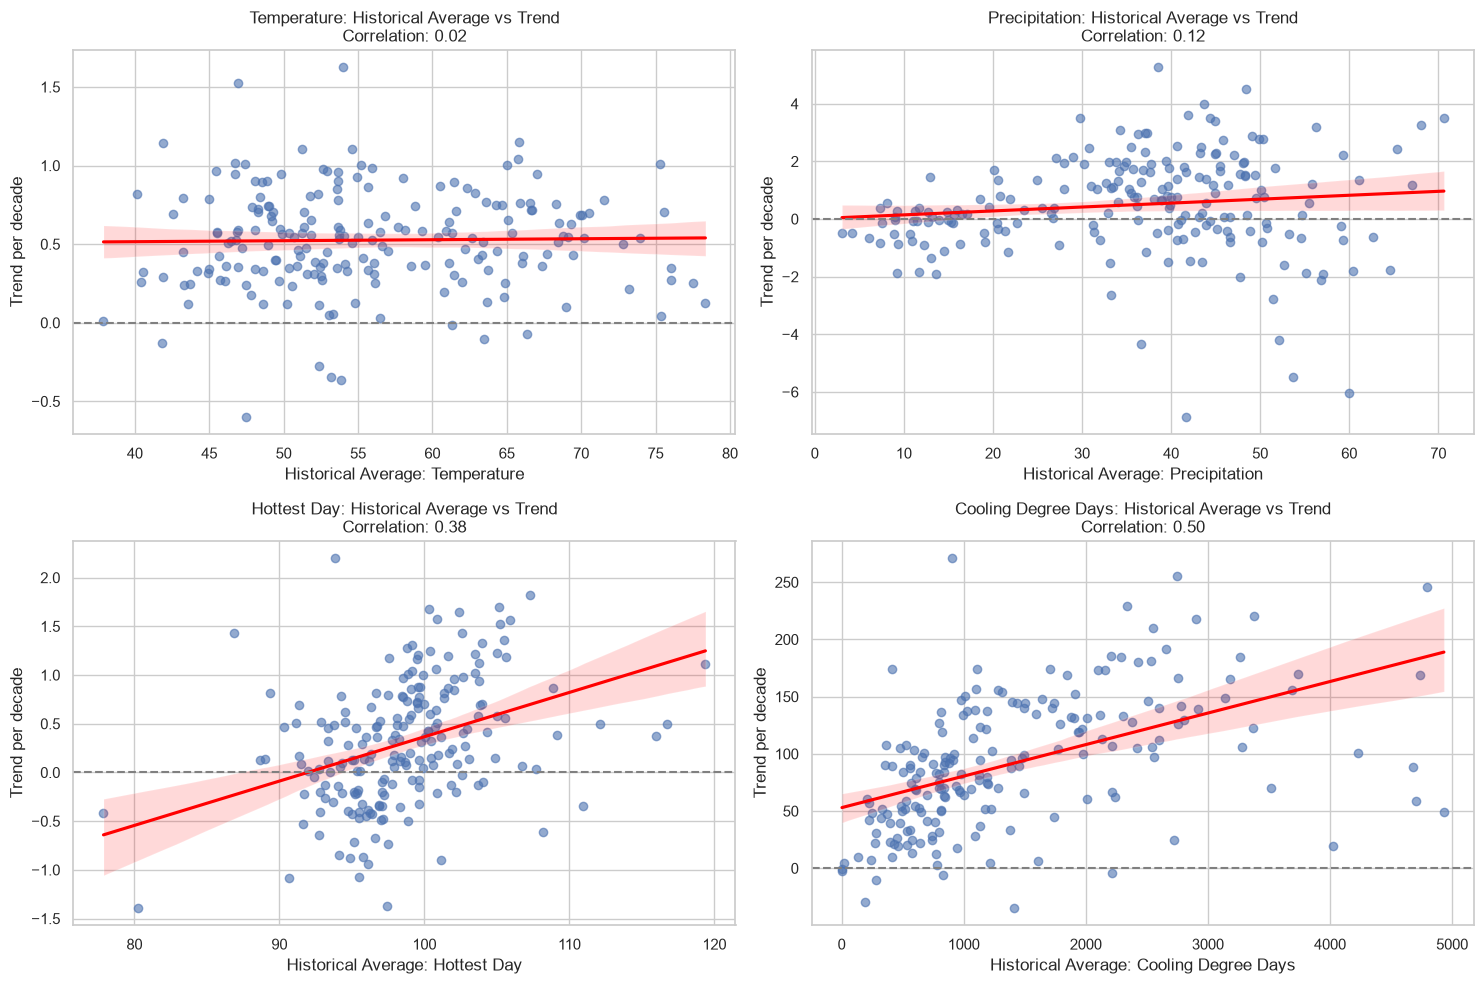

In [89]:
pairs = [
    ("avg_temp", "temp_trend", "Temperature"),
    ("avg_precip", "precip_trend", "Precipitation"),
    ("avg_hottest", "hottest_trend", "Hottest Day"),
    ("avg_cdd", "cdd_trend", "Cooling Degree Days")
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (mean_col, trend_col, label) in zip(
    axes.flatten(), pairs
):

    valid = city_analysis.dropna(
        subset=[mean_col, trend_col]
    )

    sns.regplot(
        data=valid,
        x=mean_col,
        y=trend_col,
        scatter_kws={"alpha": 0.6},
        line_kws={"color": "red"},
        ax=ax
    )

    ax.axhline(0, color="gray", linestyle="--")

    correlation = valid[mean_col].corr(valid[trend_col])

    ax.set_title(
        f"{label}: Historical Average vs Trend\n"
        f"Correlation: {correlation:.2f}"
    )

    ax.set_xlabel(f"Historical Average: {label}")
    ax.set_ylabel("Trend per decade")

plt.tight_layout()
plt.show()

In [90]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import euclidean_distances

feature_cols = [
    "avg_temp",
    "avg_precip",
    "avg_hottest",
    "avg_cdd"
]

similarity_data = (
    city_analysis[
        ["ID", "Name"] + feature_cols
    ]
    .dropna()
    .copy()
)

scaler = StandardScaler()

scaled_features = scaler.fit_transform(
    similarity_data[feature_cols]
)

distance_matrix = euclidean_distances(
    scaled_features
)

distance_df = pd.DataFrame(
    distance_matrix,
    index=similarity_data["ID"],
    columns=similarity_data["ID"]
)

print(
    "Cities with sufficient data for similarity analysis:",
    len(similarity_data)
)

Cities with sufficient data for similarity analysis: 194


In [91]:
def find_similar_cities(city_name, n=5):

    matches = similarity_data[
        similarity_data["Name"] == city_name
    ]

    if matches.empty:
        print(f"{city_name} is unavailable in similarity data.")
        return

    city_id = matches.iloc[0]["ID"]

    nearest = (
        distance_df.loc[city_id]
        .drop(index=city_id)
        .nsmallest(n)
    )

    result = similarity_data[
        similarity_data["ID"].isin(nearest.index)
    ].copy()

    result["distance"] = result["ID"].map(nearest)

    return result.sort_values("distance")


example_cities = [
    "Pittsburgh",
    "Phoenix",
    "Miami",
    "Minneapolis",
    "Seattle"
]

for city in example_cities:

    print(f"\nMost similar cities to {city}:")

    result = find_similar_cities(city)

    if result is not None:
        display(result.round(2))


Most similar cities to Pittsburgh:


,ID,Name,avg_temp,avg_precip,avg_hottest,avg_cdd,distance
182,USW00093824,Zaneville,52.51,38.90,93.70,843.48,0.20
27,USW00004853,Cleveland,51.35,40.67,94.07,822.71,0.28
102,USW00014860,Erie,50.39,43.23,92.40,700.23,0.32
176,USW00093815,Dayton,52.63,42.16,94.13,972.95,0.36
41,USW00013736,Morgantown,53.81,43.92,93.14,915.36,0.36



Most similar cities to Phoenix:


,ID,Name,avg_temp,avg_precip,avg_hottest,avg_cdd,distance
8,USW00003145,Yuma,76.06,3.06,116.70,4706.01,0.31
138,USW00023179,Needles,75.27,4.20,119.38,4798.25,0.68
137,USW00023160,Tucson,70.51,10.71,110.93,3369.40,1.72
136,USW00023155,Bakersfield,65.83,6.08,108.90,2336.19,2.86
129,USW00023044,ElPaso,65.74,9.00,106.73,2552.98,2.92



Most similar cities to Miami:


,ID,Name,avg_temp,avg_precip,avg_hottest,avg_cdd,distance
34,USW00012844,WestPalmBeach,76.04,60.44,95.40,4231.46,0.56
30,USW00012835,FortMyers,75.33,55.47,96.60,4021.62,0.95
33,USW00012842,Tampa,73.92,48.46,96.17,3741.00,1.48
28,USW00012815,Orlando,73.22,50.63,97.23,3517.69,1.57
31,USW00012836,KeyWest,78.35,39.73,92.73,4932.67,1.79



Most similar cities to Minneapolis:


,ID,Name,avg_temp,avg_precip,avg_hottest,avg_cdd,distance
124,USW00014944,SiouxFalls,46.45,27.11,97.40,740.93,0.30
125,USW00014972,Spencer,46.29,26.53,97.10,739.50,0.31
111,USW00014920,LaCrosse,48.04,34.72,97.47,834.73,0.33
205,USW00094910,Waterloo,47.80,35.71,96.13,770.46,0.34
127,USW00014991,EauClaire,44.93,32.74,95.77,580.11,0.35



Most similar cities to Seattle:


,ID,Name,avg_temp,avg_precip,avg_hottest,avg_cdd,distance
182,USW00093824,Zaneville,52.51,38.90,93.70,843.48,0.60
27,USW00004853,Cleveland,51.35,40.67,94.07,822.71,0.61
198,USW00094823,Pittsburgh,52.02,39.68,92.70,811.21,0.61
82,USW00014735,Albany,48.99,40.71,94.50,662.18,0.63
203,USW00094860,GrandRapids,48.89,38.94,94.33,674.34,0.63


In [92]:
anomaly_df = geo_df[
    ["ID", "Name", "Year", "Avg Temp_clean"]
].copy()

city_mean = anomaly_df.groupby("ID")[
    "Avg Temp_clean"
].transform("mean")

anomaly_df["temp_anomaly"] = (
    anomaly_df["Avg Temp_clean"] - city_mean
)

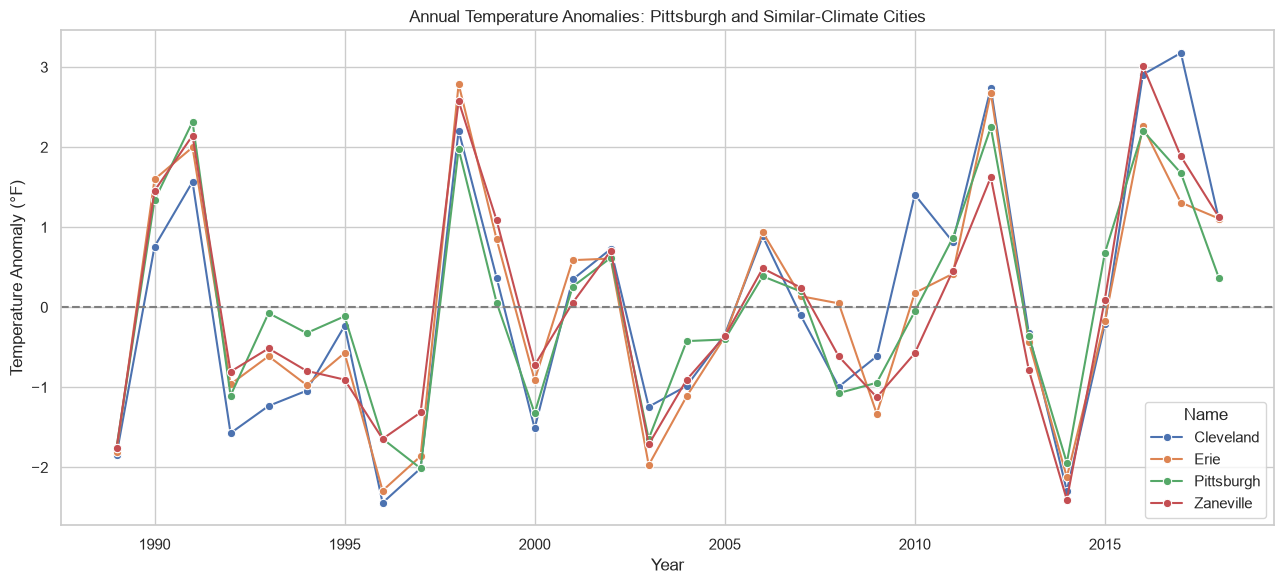

In [93]:
selected_city = "Pittsburgh"

neighbors = find_similar_cities(selected_city, n=3)

if neighbors is not None:

    comparison_cities = [
        selected_city
    ] + neighbors["Name"].tolist()

    subset = anomaly_df[
        anomaly_df["Name"].isin(comparison_cities)
    ].copy()

    plt.figure(figsize=(13, 6))

    sns.lineplot(
        data=subset,
        x="Year",
        y="temp_anomaly",
        hue="Name",
        marker="o"
    )

    plt.axhline(0, color="gray", linestyle="--")

    plt.title(
        "Annual Temperature Anomalies: "
        "Pittsburgh and Similar-Climate Cities"
    )

    plt.xlabel("Year")
    plt.ylabel("Temperature Anomaly (°F)")
    plt.tight_layout()
    plt.show()

In [94]:
if neighbors is not None:

    anomaly_wide = (
        subset.pivot_table(
            index="Year",
            columns="Name",
            values="temp_anomaly"
        )
    )

    print("Correlation between annual temperature anomalies:")

    display(
        anomaly_wide.corr().round(2)
    )

Correlation between annual temperature anomalies:


Name,Cleveland,Erie,Pittsburgh,Zaneville
Name,,,,
Cleveland,1.00,0.92,0.92,0.90
Erie,0.92,1.00,0.94,0.96
Pittsburgh,0.92,0.94,1.00,0.94
Zaneville,0.90,0.96,0.94,1.00


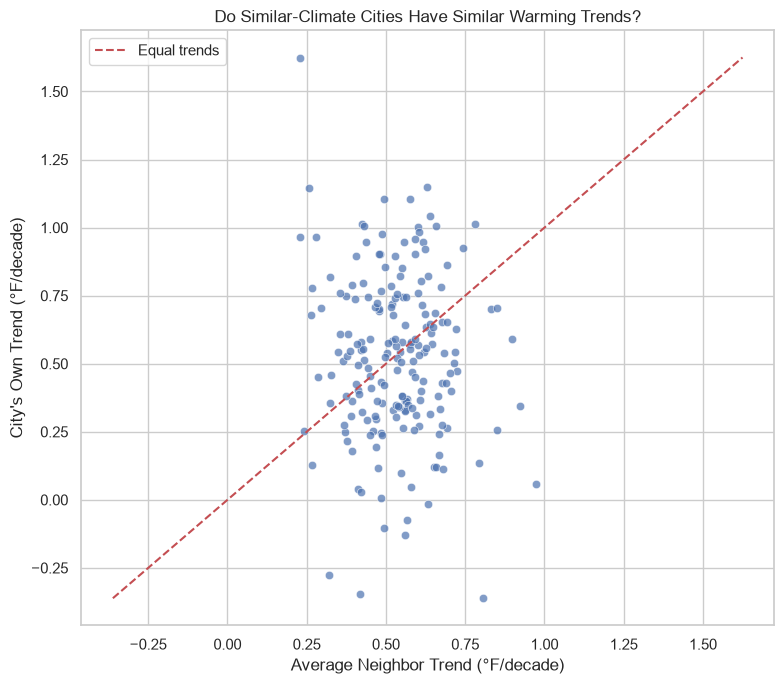

Correlation: -0.08491961931438091


In [95]:
trend_lookup = (
    city_analysis.set_index("ID")["temp_trend"]
)

similarity_ids = similarity_data["ID"].tolist()

trend_comparisons = []

for city_id in similarity_ids:

    if city_id not in trend_lookup.index:
        continue

    own_trend = trend_lookup.loc[city_id]

    if pd.isna(own_trend):
        continue

    nearest_ids = (
        distance_df.loc[city_id]
        .drop(index=city_id)
        .nsmallest(5)
        .index
    )

    neighbor_trends = (
        trend_lookup
        .reindex(nearest_ids)
        .dropna()
    )

    if len(neighbor_trends) < 3:
        continue

    trend_comparisons.append({
        "ID": city_id,
        "own_trend": own_trend,
        "neighbor_mean_trend": neighbor_trends.mean()
    })

trend_comparison_df = pd.DataFrame(trend_comparisons)

plt.figure(figsize=(8, 7))

sns.scatterplot(
    data=trend_comparison_df,
    x="neighbor_mean_trend",
    y="own_trend",
    alpha=0.7
)

limits = [
    min(
        trend_comparison_df["own_trend"].min(),
        trend_comparison_df["neighbor_mean_trend"].min()
    ),
    max(
        trend_comparison_df["own_trend"].max(),
        trend_comparison_df["neighbor_mean_trend"].max()
    )
]

plt.plot(limits, limits, "r--", label="Equal trends")

plt.xlabel("Average Neighbor Trend (°F/decade)")
plt.ylabel("City's Own Trend (°F/decade)")
plt.title("Do Similar-Climate Cities Have Similar Warming Trends?")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Correlation:",
    trend_comparison_df["own_trend"].corr(
        trend_comparison_df["neighbor_mean_trend"]
    )
)

In [96]:
coverage_report = pd.DataFrame({
    "Target": targets,
    "Cities with >=20 valid years": [
        city_climate["temp_count"].ge(20).sum(),
        city_climate["precip_count"].ge(20).sum(),
        city_climate["hottest_count"].ge(20).sum(),
        city_climate["cdd_count"].ge(20).sum()
    ],
    "Total cities": city_climate["ID"].nunique()
})

coverage_report["Coverage %"] = (
    coverage_report["Cities with >=20 valid years"] /
    coverage_report["Total cities"] * 100
)

display(coverage_report.round(2))

,Target,Cities with >=20 valid years,Total cities,Coverage %
0,Avg Temp,200,210,95.24
1,ToT Prcp,204,210,97.14
2,Max Tmax,200,210,95.24
3,cdd,196,210,93.33


In [97]:
relationship_report = []

for mean_col, trend_col, label in pairs:

    valid = city_analysis[
        [mean_col, trend_col]
    ].dropna()

    relationship_report.append({
        "Target": label,
        "Cities": len(valid),
        "Average vs Trend Correlation": (
            valid[mean_col].corr(valid[trend_col])
        )
    })

relationship_report = pd.DataFrame(relationship_report)

display(relationship_report.round(3))

,Target,Cities,Average vs Trend Correlation
0,Temperature,200,0.018
1,Precipitation,204,0.122
2,Hottest Day,200,0.377
3,Cooling Degree Days,196,0.504


In [98]:
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

sns.set_theme(style="whitegrid")

targets = ["Avg Temp", "ToT Prcp", "Max Tmax", "cdd"]

clean_targets = {
    "Avg Temp": "Avg Temp_clean",
    "ToT Prcp": "ToT Prcp_clean",
    "Max Tmax": "Max Tmax_clean",
    "cdd": "cdd_clean"
}

ts_df = eda.copy()

ts_df = ts_df.sort_values(
    ["ID", "Year"]
).reset_index(drop=True)

print("Total cities:", ts_df["ID"].nunique())
print("Year range:", ts_df["Year"].min(), ts_df["Year"].max())

Total cities: 210
Year range: 1851 2018


In [99]:
def get_city_series(city, target):

    col = clean_targets[target]

    city_data = (
        ts_df[ts_df["Name"] == city]
        .sort_values("Year")
    )

    if city_data.empty:
        raise ValueError(f"City not found: {city}")

    series = city_data.set_index("Year")[col]

    # Preserve actual calendar-year spacing
    years = np.arange(
        int(series.index.min()),
        int(series.index.max()) + 1
    )

    series = series.reindex(years).astype(float)
    series.index.name = "Year"

    return series

In [100]:
def longest_valid_run(series):

    valid = series.notna()

    groups = valid.ne(valid.shift()).cumsum()

    valid_groups = [
        group
        for _, group in series.groupby(groups)
        if group.notna().all()
    ]

    if not valid_groups:
        return pd.Series(dtype=float)

    return max(valid_groups, key=len)

In [101]:
series = get_city_series("Pittsburgh", "Avg Temp")

continuous_series = longest_valid_run(series)

print("Total valid years:", series.notna().sum())
print("Longest continuous run:", len(continuous_series))

print(
    "Period:",
    continuous_series.index.min(),
    "-",
    continuous_series.index.max()
)

Total valid years: 141
Longest continuous run: 128
Period: 1891 - 2018


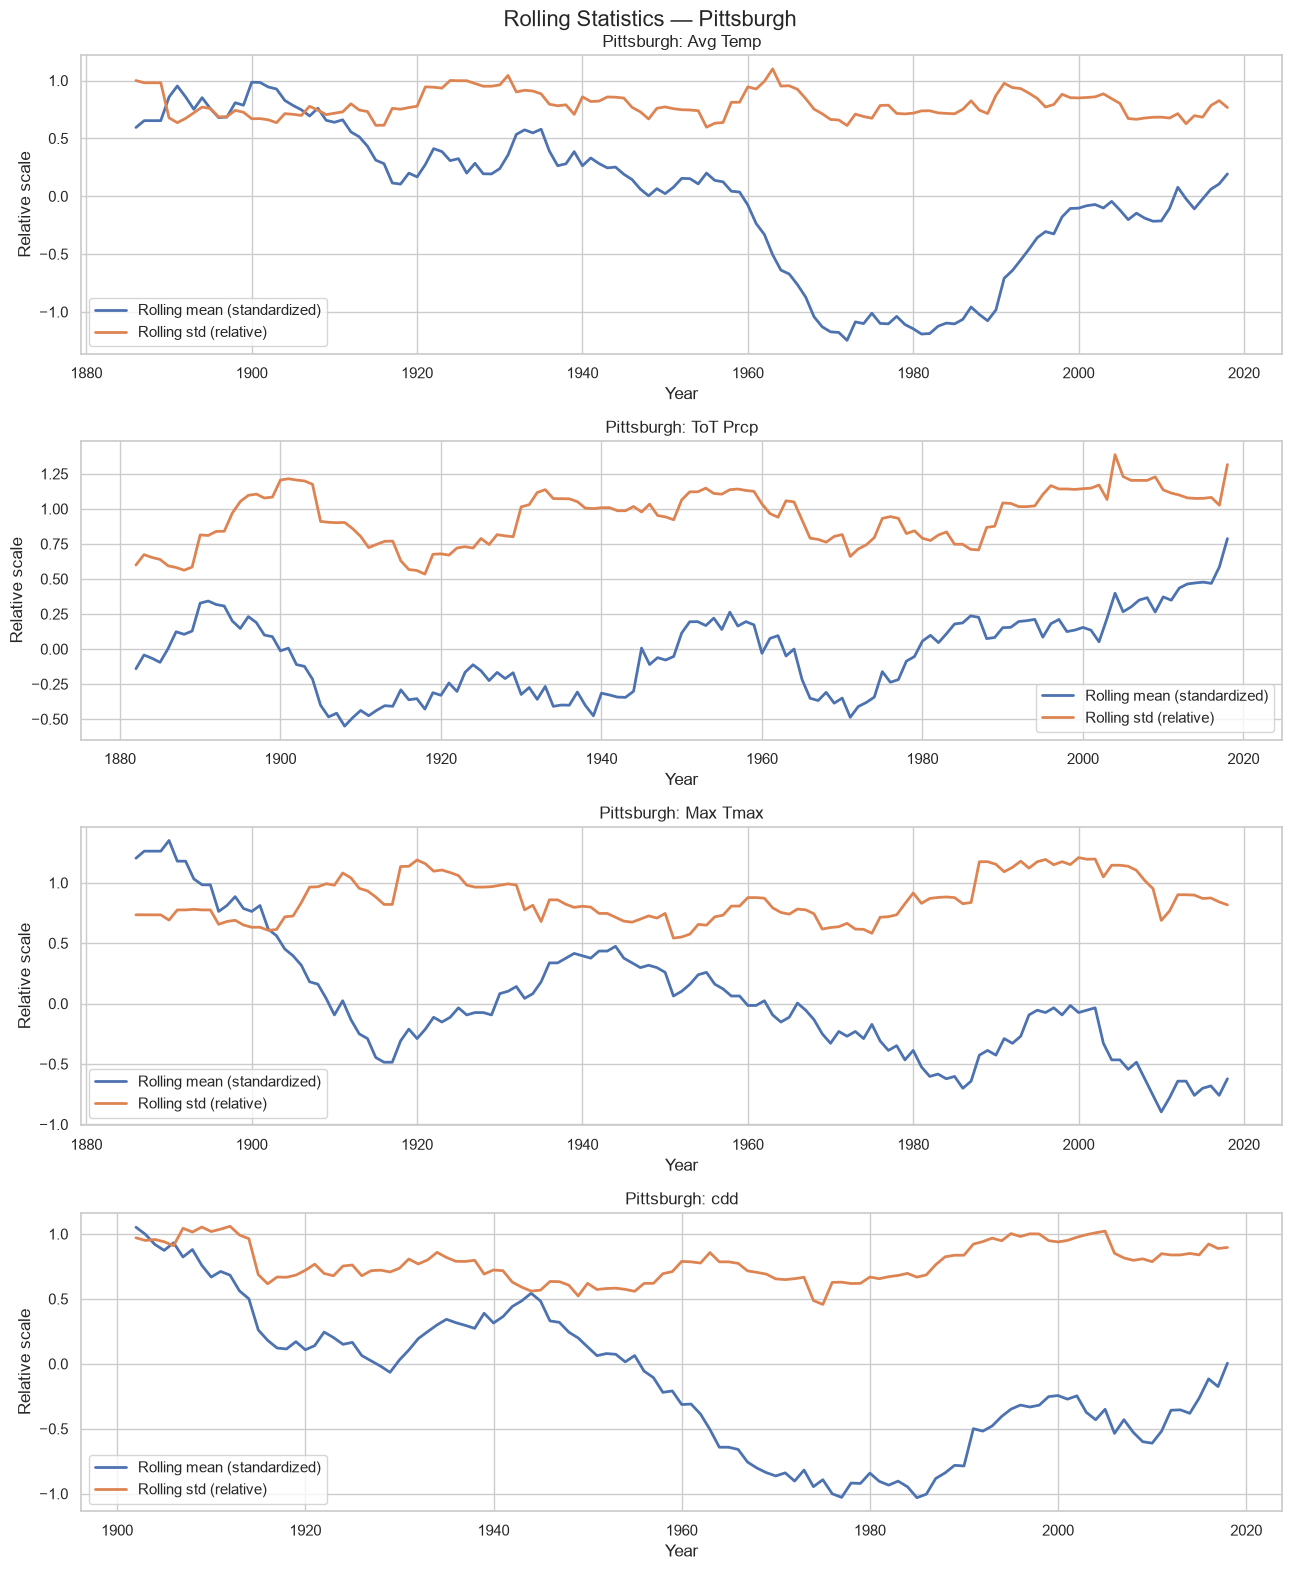

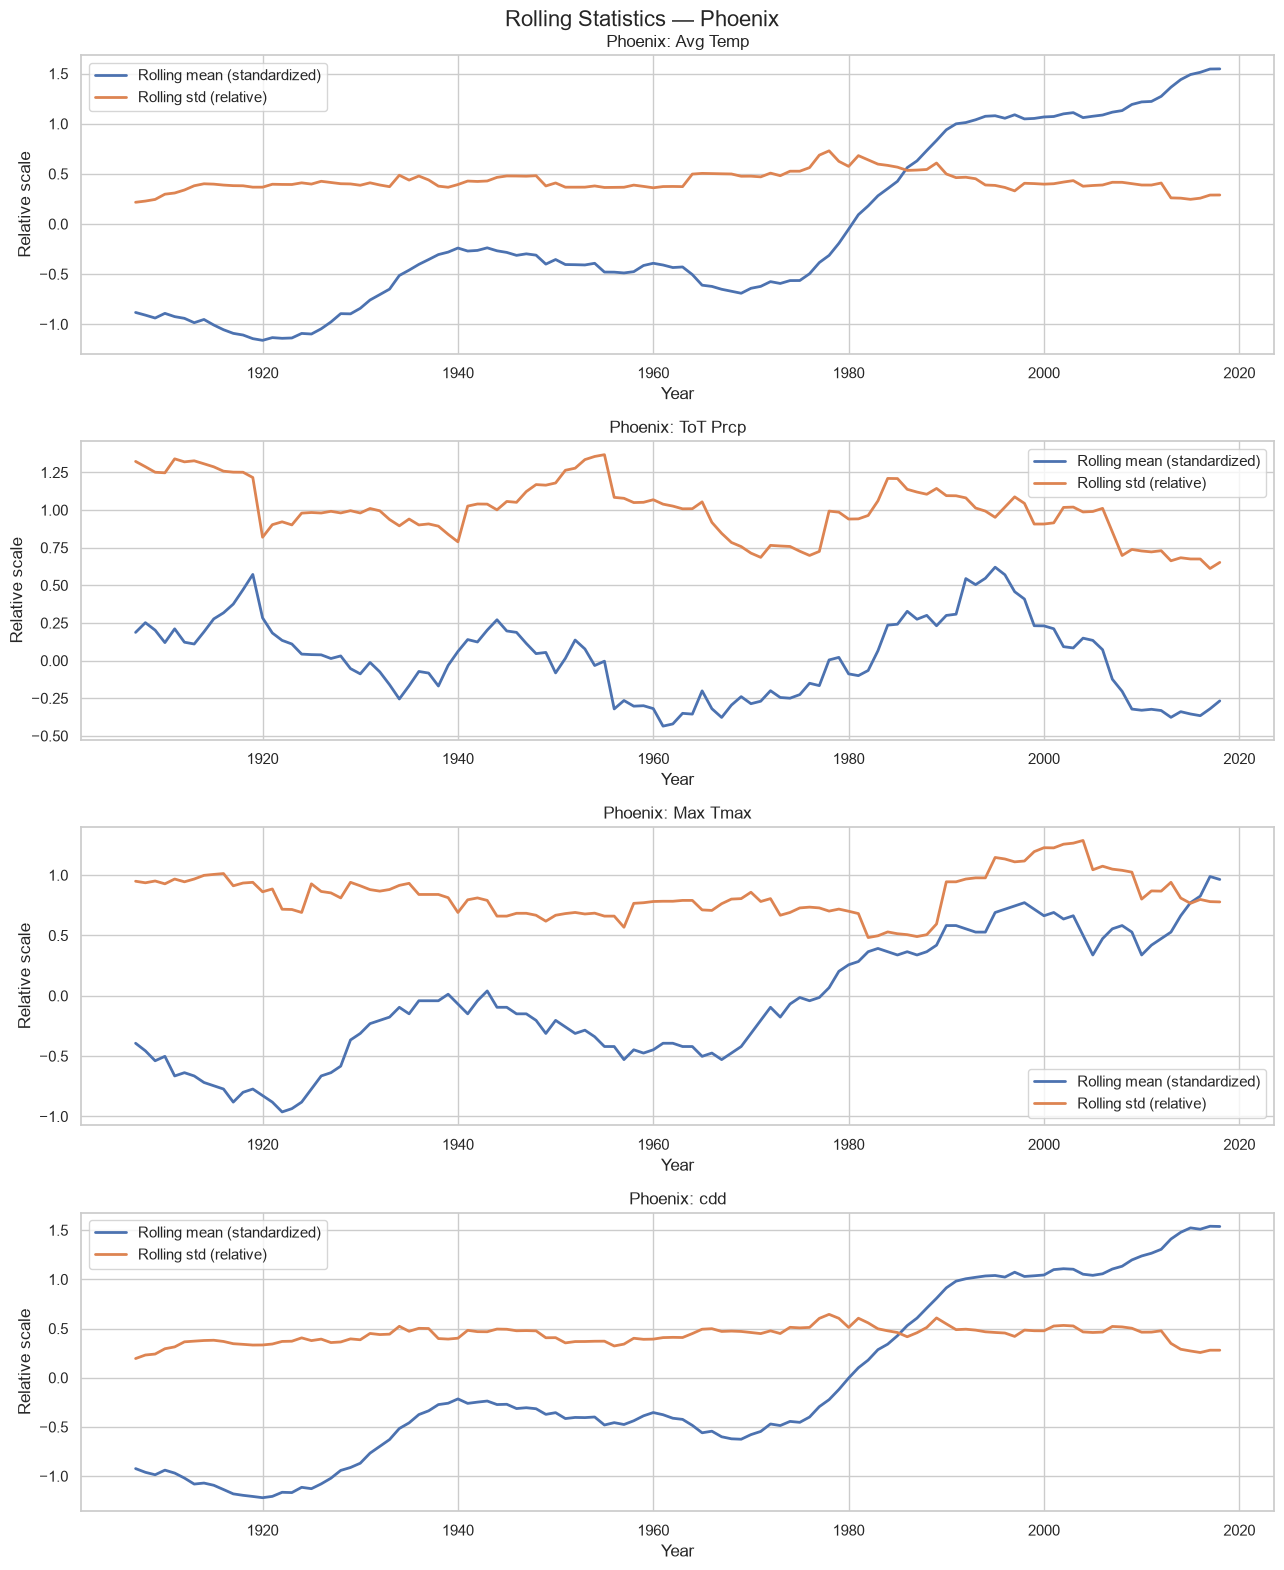

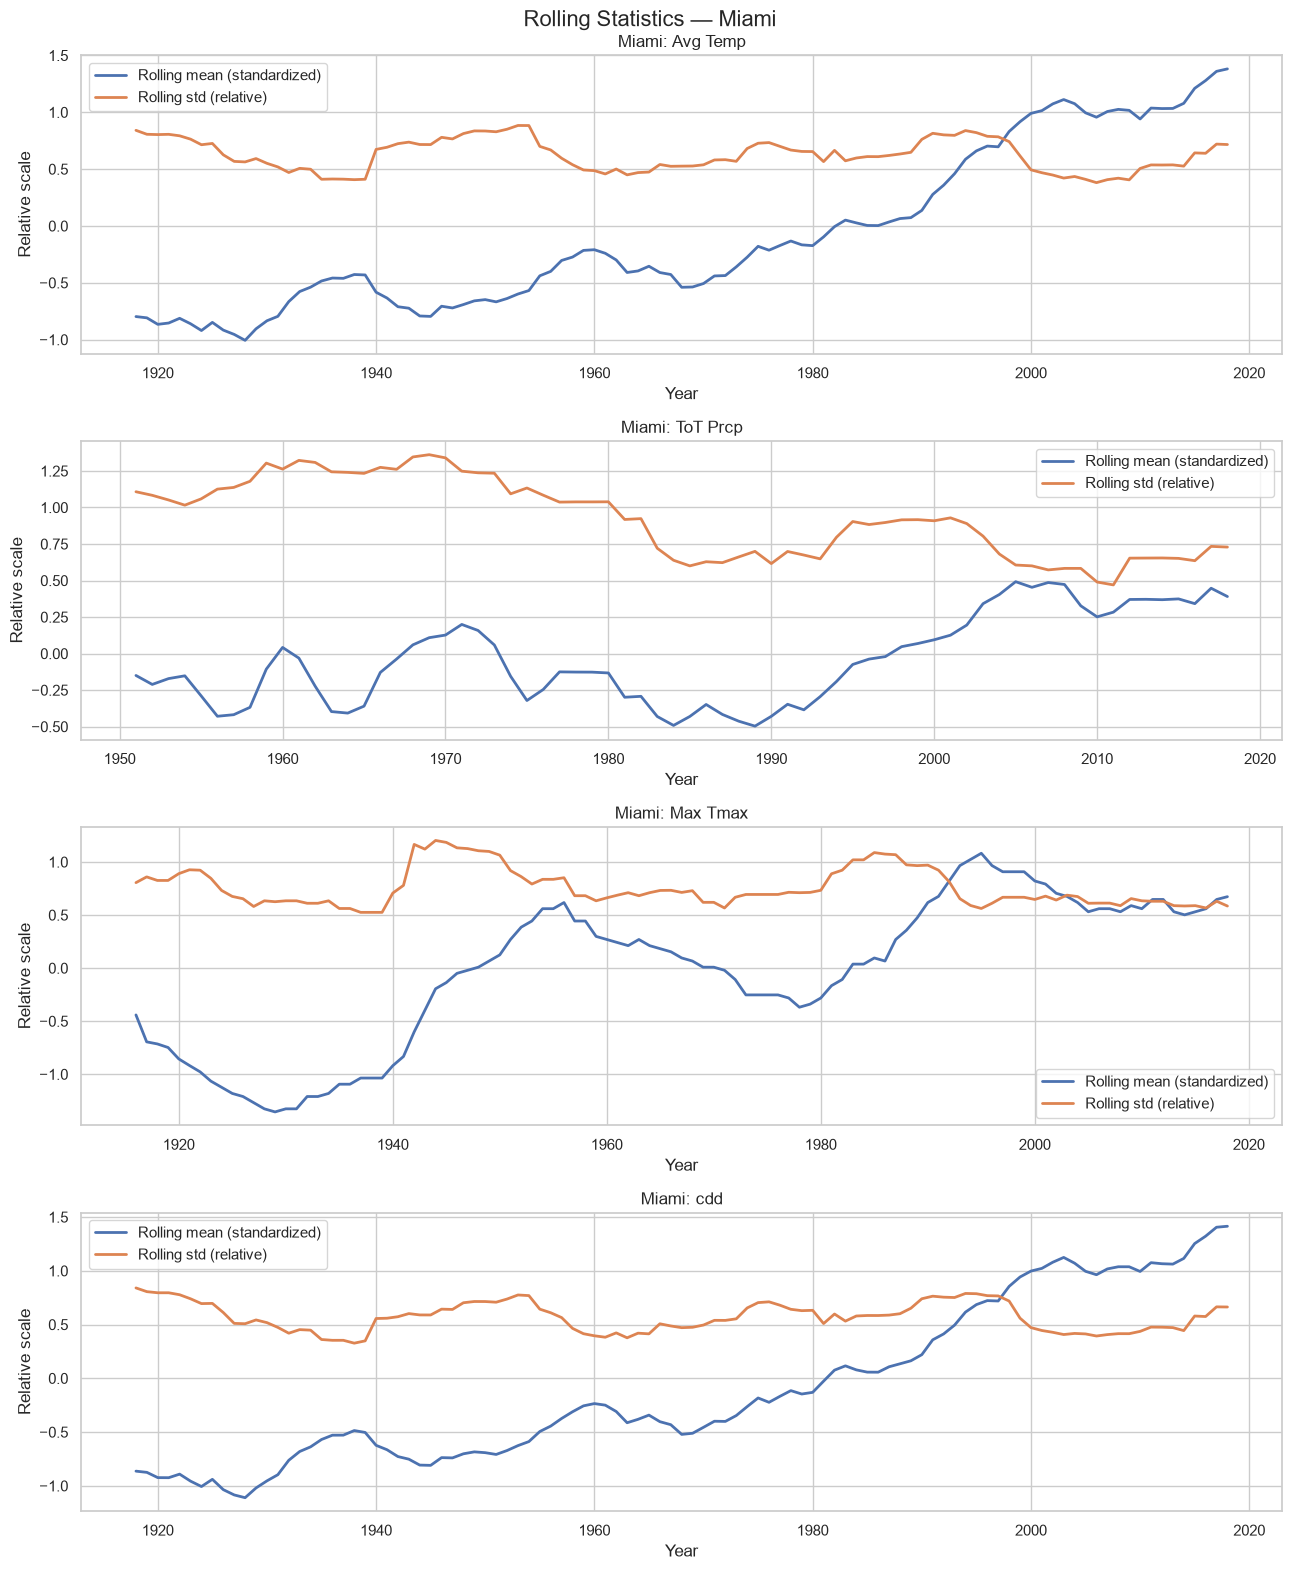

In [102]:
selected_cities = [
    "Pittsburgh",
    "Phoenix",
    "Miami"
]

WINDOW = 15

for city in selected_cities:

    fig, axes = plt.subplots(
        4, 1,
        figsize=(13, 16)
    )

    for ax, target in zip(axes, targets):

        series = get_city_series(city, target)

        rolling_mean = series.rolling(
            window=WINDOW,
            min_periods=12
        ).mean()

        rolling_std = series.rolling(
            window=WINDOW,
            min_periods=12
        ).std()

        # Normalize to compare changes in mean and variability
        # on the same plot
        series_std = series.std()

        if pd.notna(series_std) and series_std > 0:

            normalized_mean = (
                rolling_mean - series.mean()
            ) / series_std

            normalized_std = (
                rolling_std / series_std
            )

            ax.plot(
                normalized_mean.index,
                normalized_mean,
                label="Rolling mean (standardized)",
                linewidth=2
            )

            ax.plot(
                normalized_std.index,
                normalized_std,
                label="Rolling std (relative)",
                linewidth=2
            )

        ax.set_title(f"{city}: {target}")

        ax.set_xlabel("Year")
        ax.set_ylabel("Relative scale")
        ax.legend()

    plt.suptitle(
        f"Rolling Statistics — {city}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

In [103]:
def run_adf(series, regression="c", min_years=25):

    continuous = longest_valid_run(series)

    result = {
        "valid_years": len(continuous),
        "start_year": (
            continuous.index.min()
            if len(continuous) else np.nan
        ),
        "end_year": (
            continuous.index.max()
            if len(continuous) else np.nan
        ),
        "adf_statistic": np.nan,
        "p_value": np.nan,
        "lags_used": np.nan,
        "conclusion": "Insufficient data"
    }

    if len(continuous) < min_years:
        return result

    if continuous.nunique() <= 1:
        result["conclusion"] = "Constant series"
        return result

    try:

        adf_result = adfuller(
            continuous,
            regression=regression,
            autolag="AIC"
        )

        p_value = adf_result[1]

        result.update({
            "adf_statistic": adf_result[0],
            "p_value": p_value,
            "lags_used": adf_result[2],
            "conclusion": (
                "Reject unit-root null"
                if p_value < 0.05
                else "Cannot reject unit-root null"
            )
        })

    except (ValueError, np.linalg.LinAlgError):
        result["conclusion"] = "Test failed"

    return result

In [104]:
adf_results = []

for city in selected_cities:

    for target in targets:

        series = get_city_series(city, target)

        for regression in ["c", "ct"]:

            result = run_adf(
                series,
                regression=regression
            )

            adf_results.append({
                "City": city,
                "Target": target,
                "Specification": regression,
                **result
            })

adf_results = pd.DataFrame(adf_results)

display(adf_results.round(4))

C:\Users\tanis\AppData\Local\Temp\ipykernel_28928\2599658515.py:30: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
C:\Users\tanis\AppData\Local\Temp\ipykernel_28928\2599658515.py:30: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
C:\Users\tanis\AppData\Local\Temp\ipykernel_28928\2599658515.py:30: FutureWarning: adfuller currentl

,City,Target,Specification,valid_years,start_year,end_year,adf_statistic,p_value,lags_used,conclusion
0,Pittsburgh,Avg Temp,c,128,1891,2018,-3.1946,0.0203,2,Reject unit-root null
1,Pittsburgh,Avg Temp,ct,128,1891,2018,-3.3624,0.0566,2,Cannot reject unit-root null
2,Pittsburgh,ToT Prcp,c,148,1871,2018,-11.3696,0.0000,0,Reject unit-root null
3,Pittsburgh,ToT Prcp,ct,148,1871,2018,-11.7354,0.0000,0,Reject unit-root null
4,Pittsburgh,Max Tmax,c,128,1891,2018,-9.6471,0.0000,0,Reject unit-root null
5,Pittsburgh,Max Tmax,ct,128,1891,2018,-10.3086,0.0000,0,Reject unit-root null
6,Pittsburgh,cdd,c,128,1891,2018,-2.4984,0.1159,4,Cannot reject unit-root null
7,Pittsburgh,cdd,ct,128,1891,2018,-2.2949,0.4367,4,Cannot reject unit-root null
8,Phoenix,Avg Temp,c,123,1896,2018,-0.2938,0.9264,3,Cannot reject unit-root null
9,Phoenix,Avg Temp,ct,123,1896,2018,-2.0615,0.5676,3,Cannot reject unit-root null


In [105]:
adf_comparison = adf_results.pivot_table(
    index=["City", "Target"],
    columns="Specification",
    values="p_value"
)

display(adf_comparison.round(4))

Specification             c      ct
City       Target                  
Miami      Avg Temp  0.7094  0.0000
           Max Tmax  0.0427  0.0061
           ToT Prcp  0.0000  0.0000
           cdd       0.7944  0.0000
Phoenix    Avg Temp  0.9264  0.5676
           Max Tmax  0.2749  0.0000
           ToT Prcp  0.0000  0.0000
           cdd       0.8924  0.2666
Pittsburgh Avg Temp  0.0203  0.0566
           Max Tmax  0.0000  0.0000
           ToT Prcp  0.0000  0.0000
           cdd       0.1159  0.4367

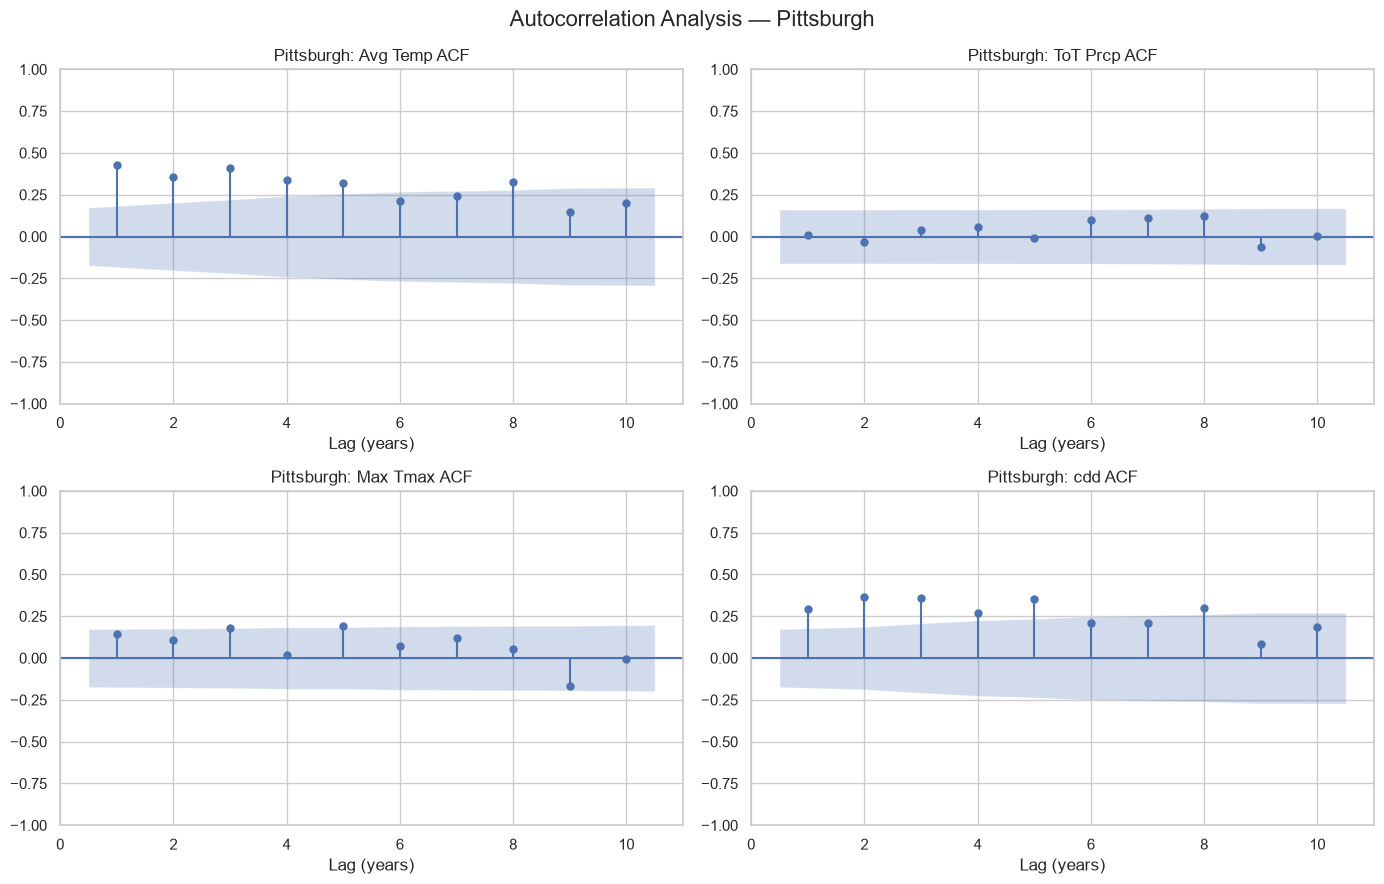

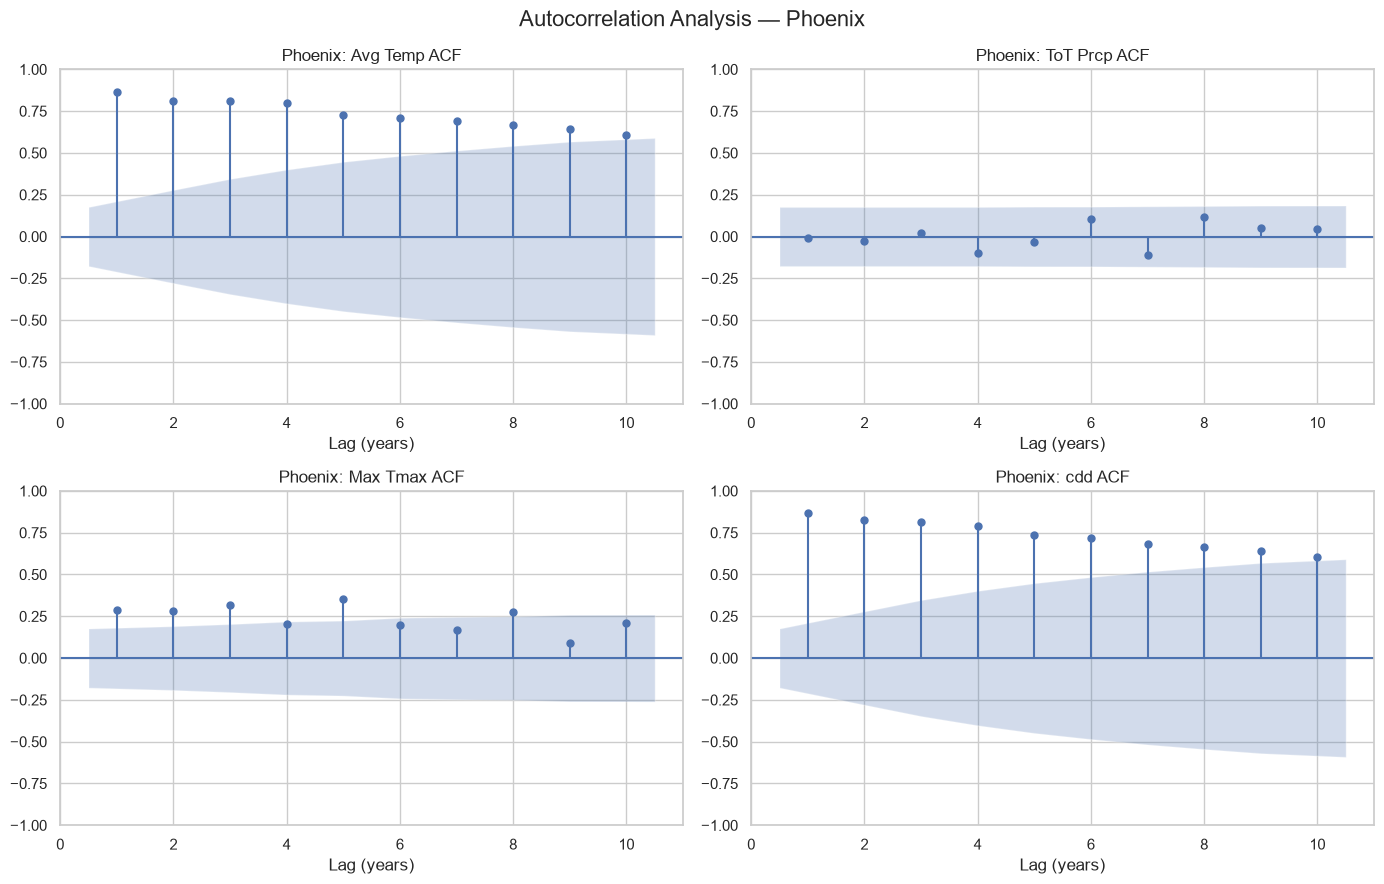

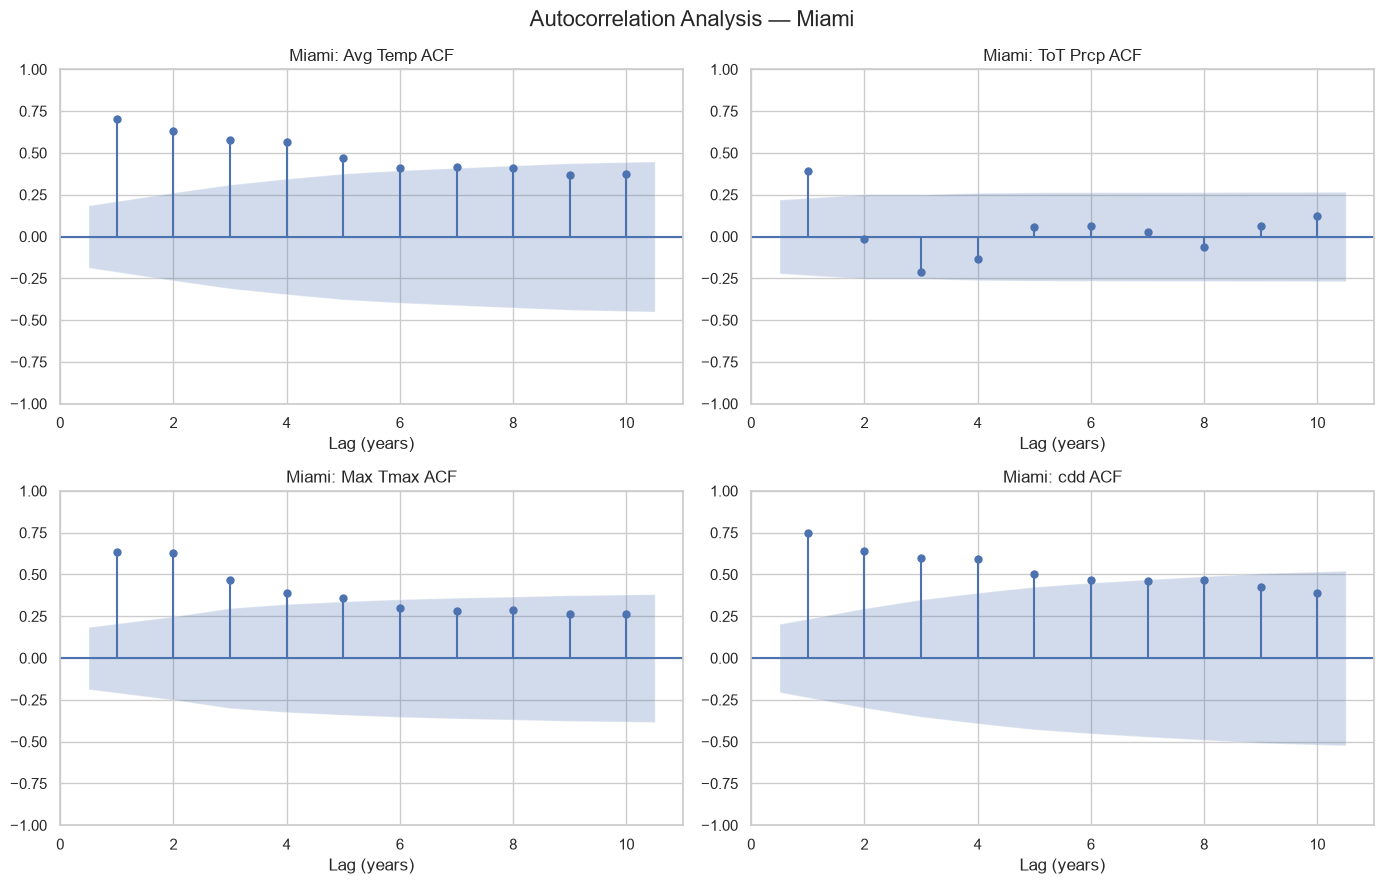

In [106]:
MAX_LAGS = 10
MIN_YEARS = 25

for city in selected_cities:

    fig, axes = plt.subplots(
        2, 2,
        figsize=(14, 9)
    )

    for ax, target in zip(axes.flatten(), targets):

        series = get_city_series(city, target)

        continuous = longest_valid_run(series)

        if len(continuous) < MIN_YEARS:
            ax.text(
                0.5, 0.5,
                "Insufficient continuous data",
                ha="center",
                va="center",
                transform=ax.transAxes
            )
            ax.set_title(f"{city}: {target}")
            continue

        plot_acf(
            continuous,
            lags=MAX_LAGS,
            alpha=0.05,
            ax=ax,
            zero=False
        )

        ax.set_title(
            f"{city}: {target} ACF"
        )

        ax.set_xlabel("Lag (years)")

    plt.suptitle(
        f"Autocorrelation Analysis — {city}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

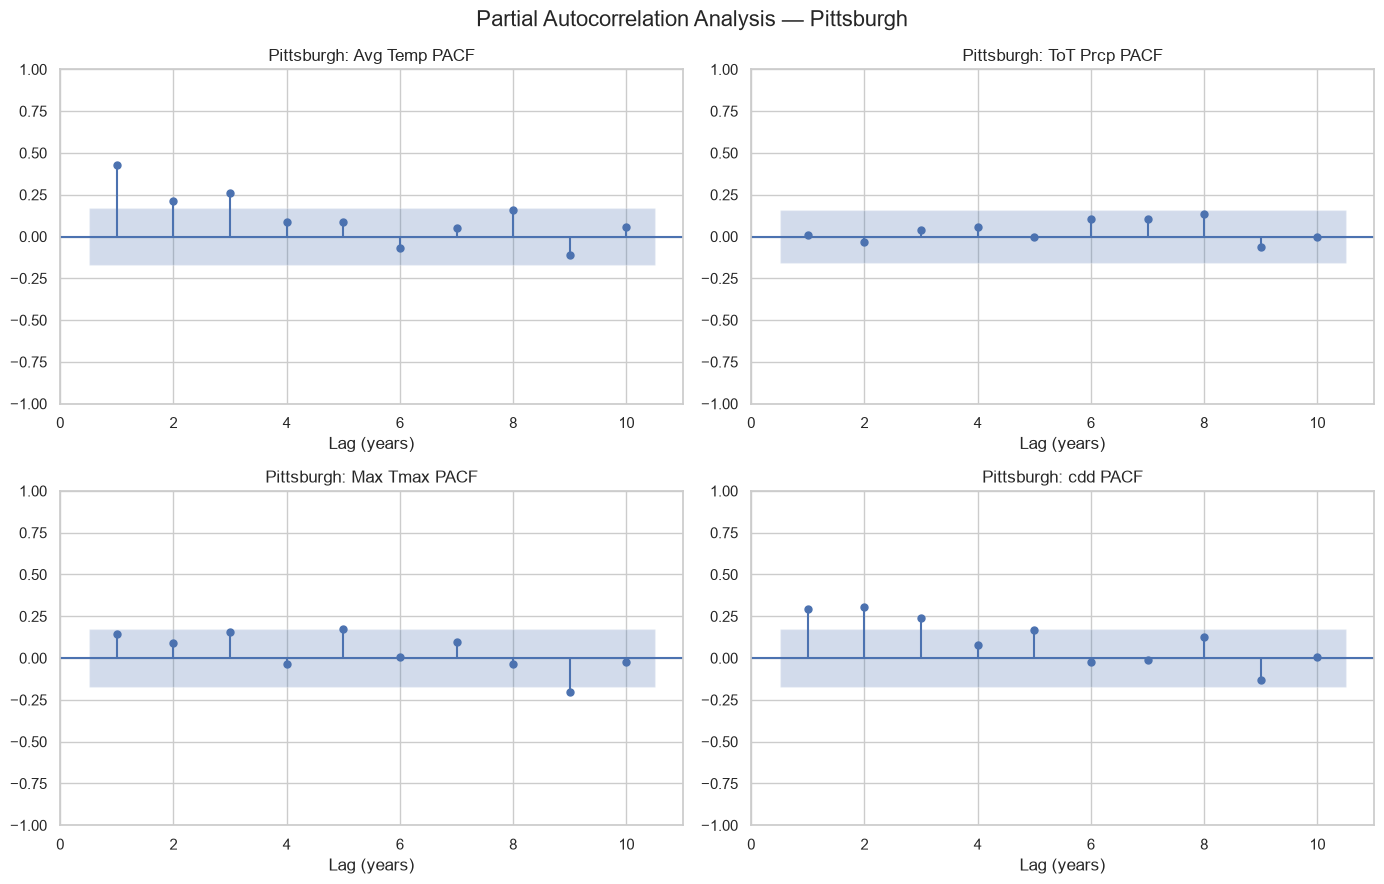

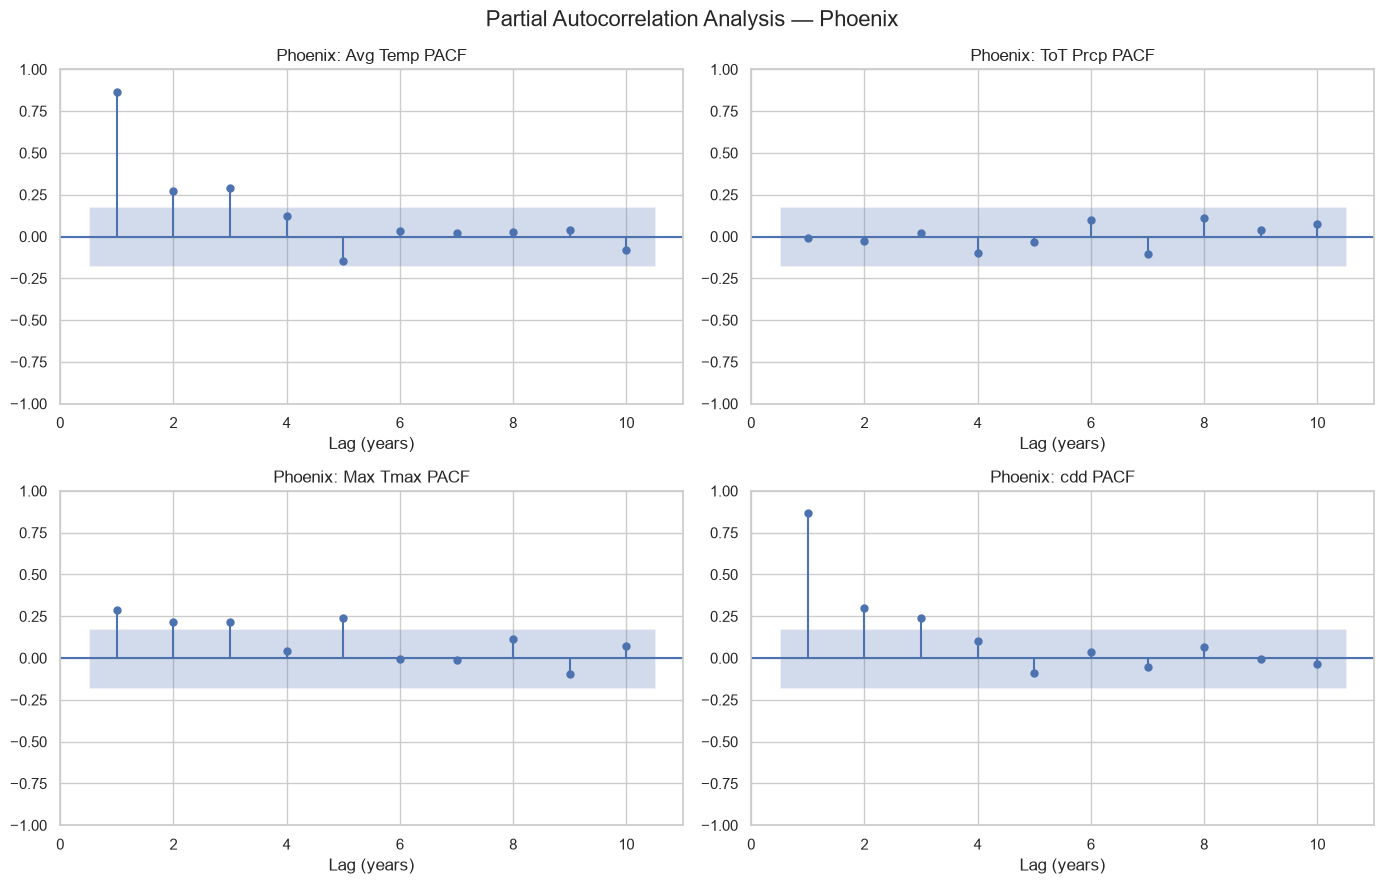

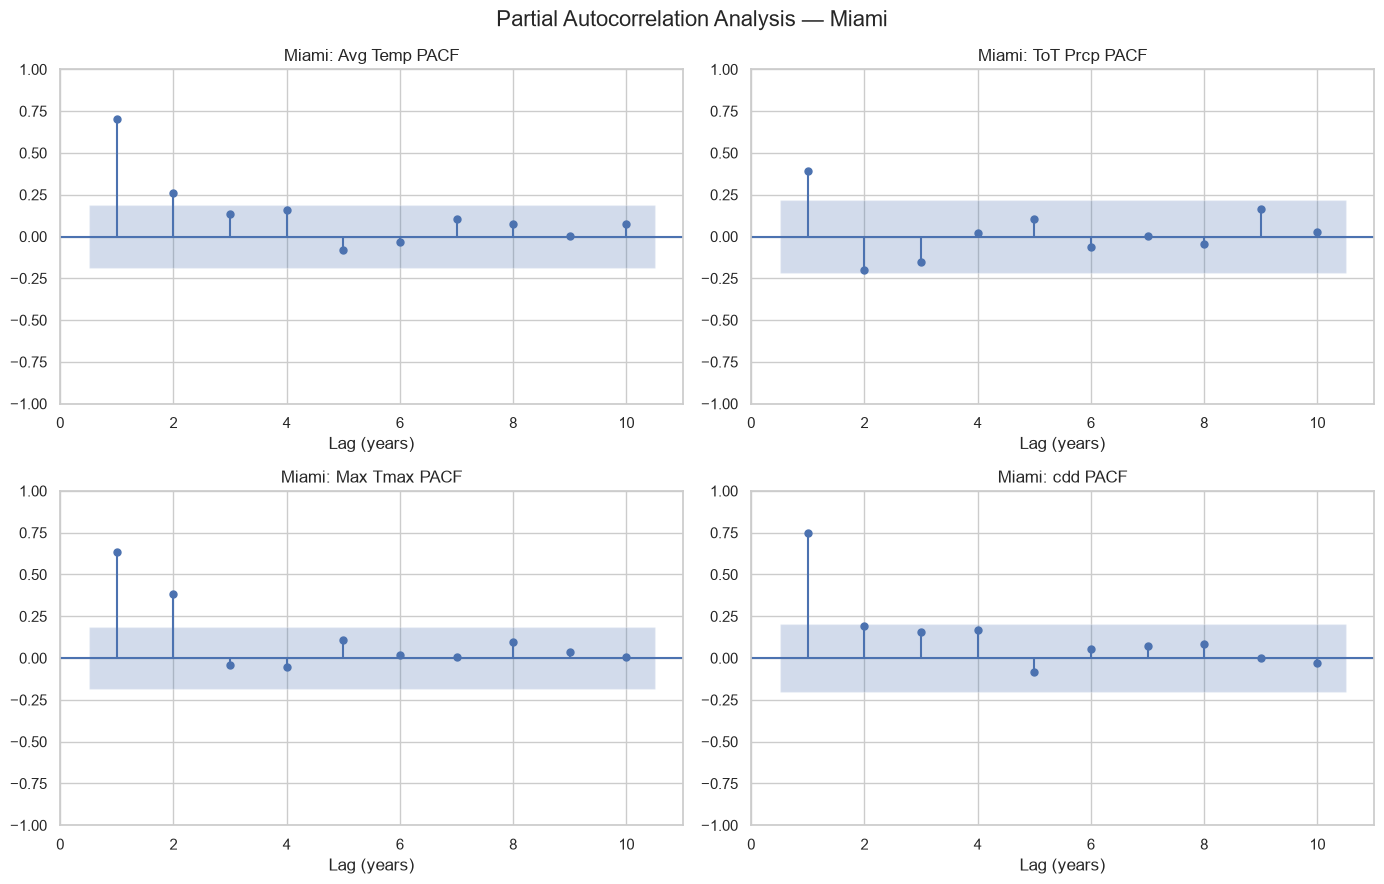

In [107]:
for city in selected_cities:

    fig, axes = plt.subplots(
        2, 2,
        figsize=(14, 9)
    )

    for ax, target in zip(axes.flatten(), targets):

        series = get_city_series(city, target)

        continuous = longest_valid_run(series)

        if len(continuous) < MIN_YEARS:
            ax.text(
                0.5, 0.5,
                "Insufficient continuous data",
                ha="center",
                va="center",
                transform=ax.transAxes
            )
            ax.set_title(f"{city}: {target}")
            continue

        n_lags = min(
            MAX_LAGS,
            len(continuous) // 2 - 1
        )

        plot_pacf(
            continuous,
            lags=n_lags,
            method="ywm",
            alpha=0.05,
            ax=ax,
            zero=False
        )

        ax.set_title(
            f"{city}: {target} PACF"
        )

        ax.set_xlabel("Lag (years)")

    plt.suptitle(
        f"Partial Autocorrelation Analysis — {city}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

In [108]:
def detrend_series(series):

    series = series.dropna().astype(float)

    years = series.index.to_numpy(dtype=float)
    values = series.to_numpy()

    slope, intercept = np.polyfit(
        years,
        values,
        1
    )

    fitted_trend = slope * years + intercept

    detrended = pd.Series(
        values - fitted_trend,
        index=series.index,
        name=series.name
    )

    return detrended

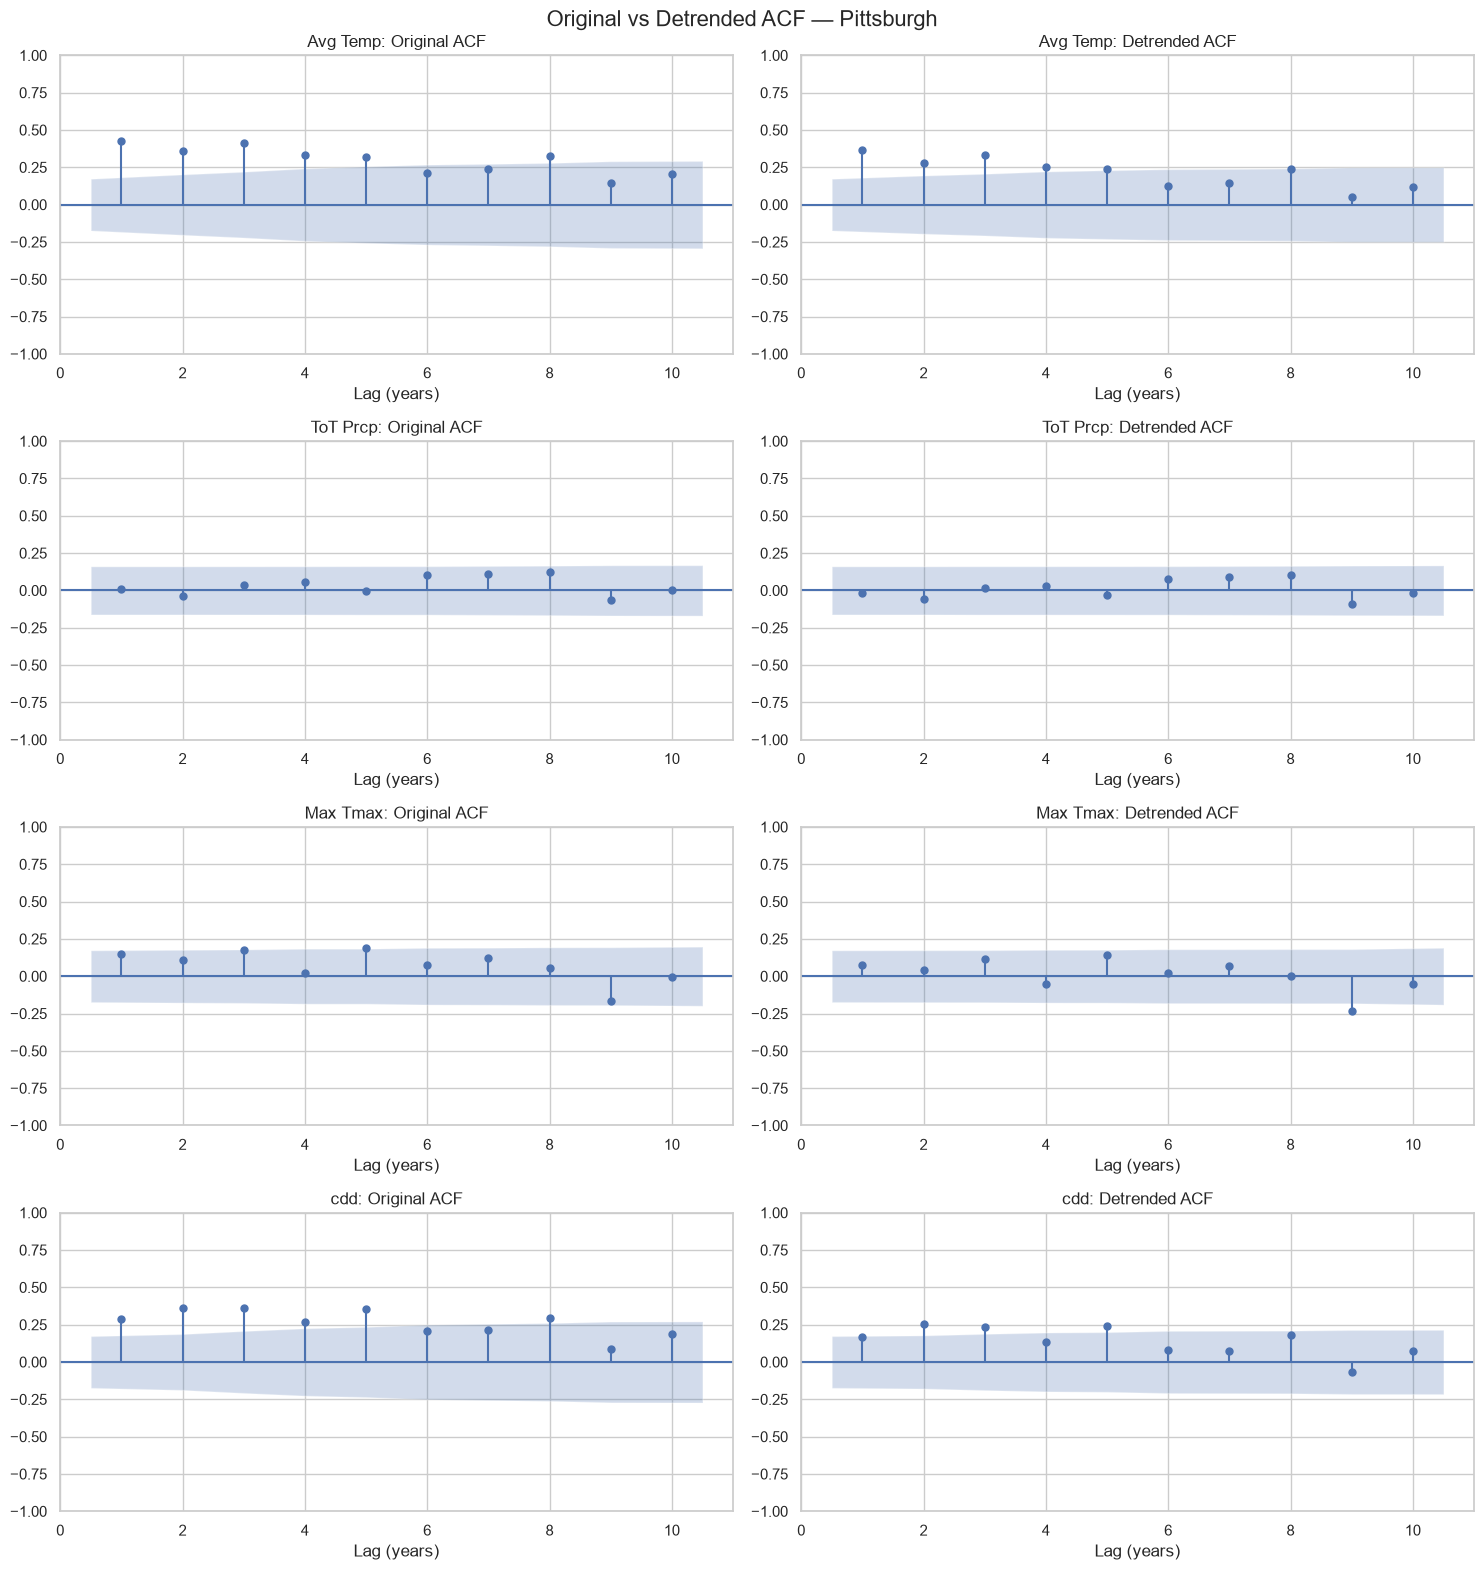

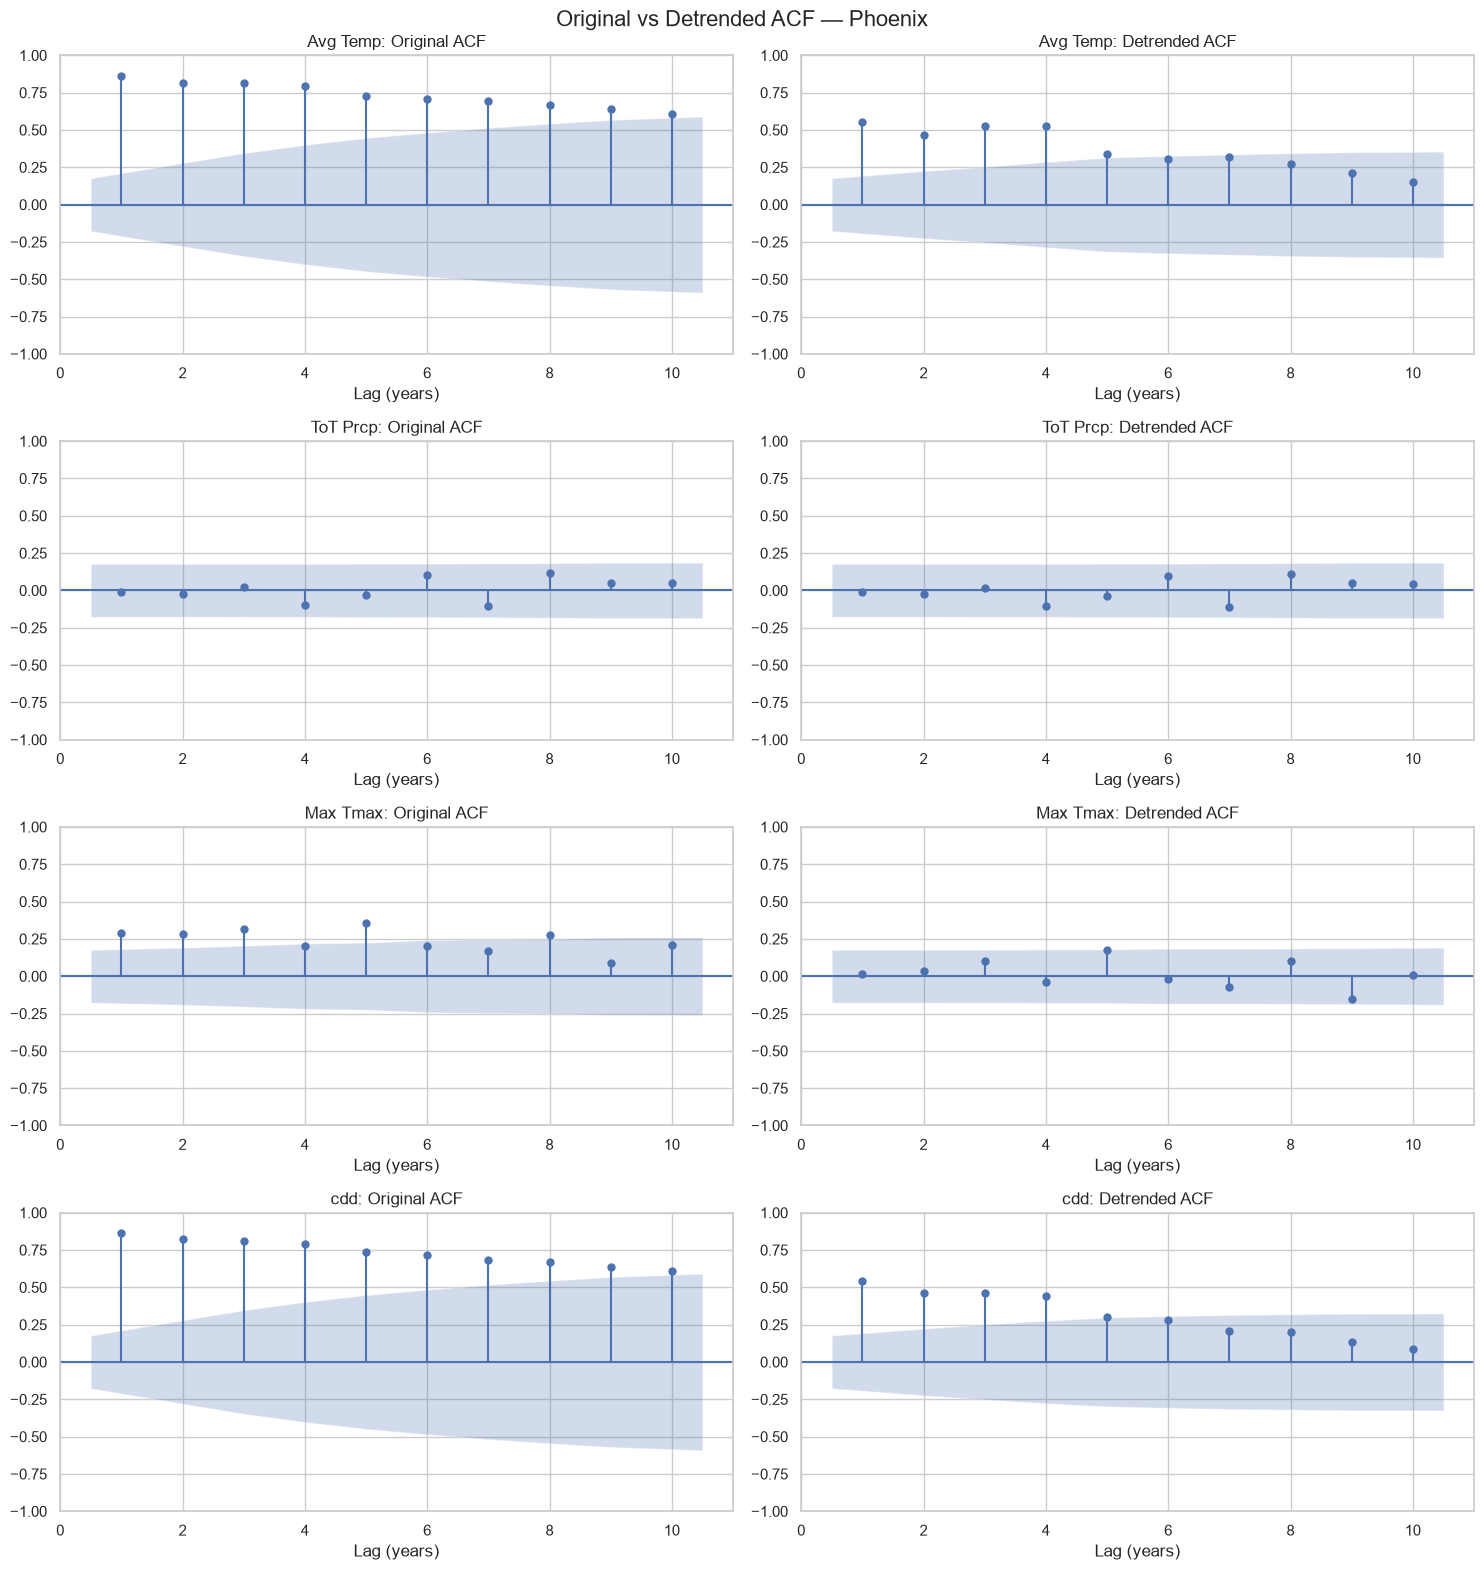

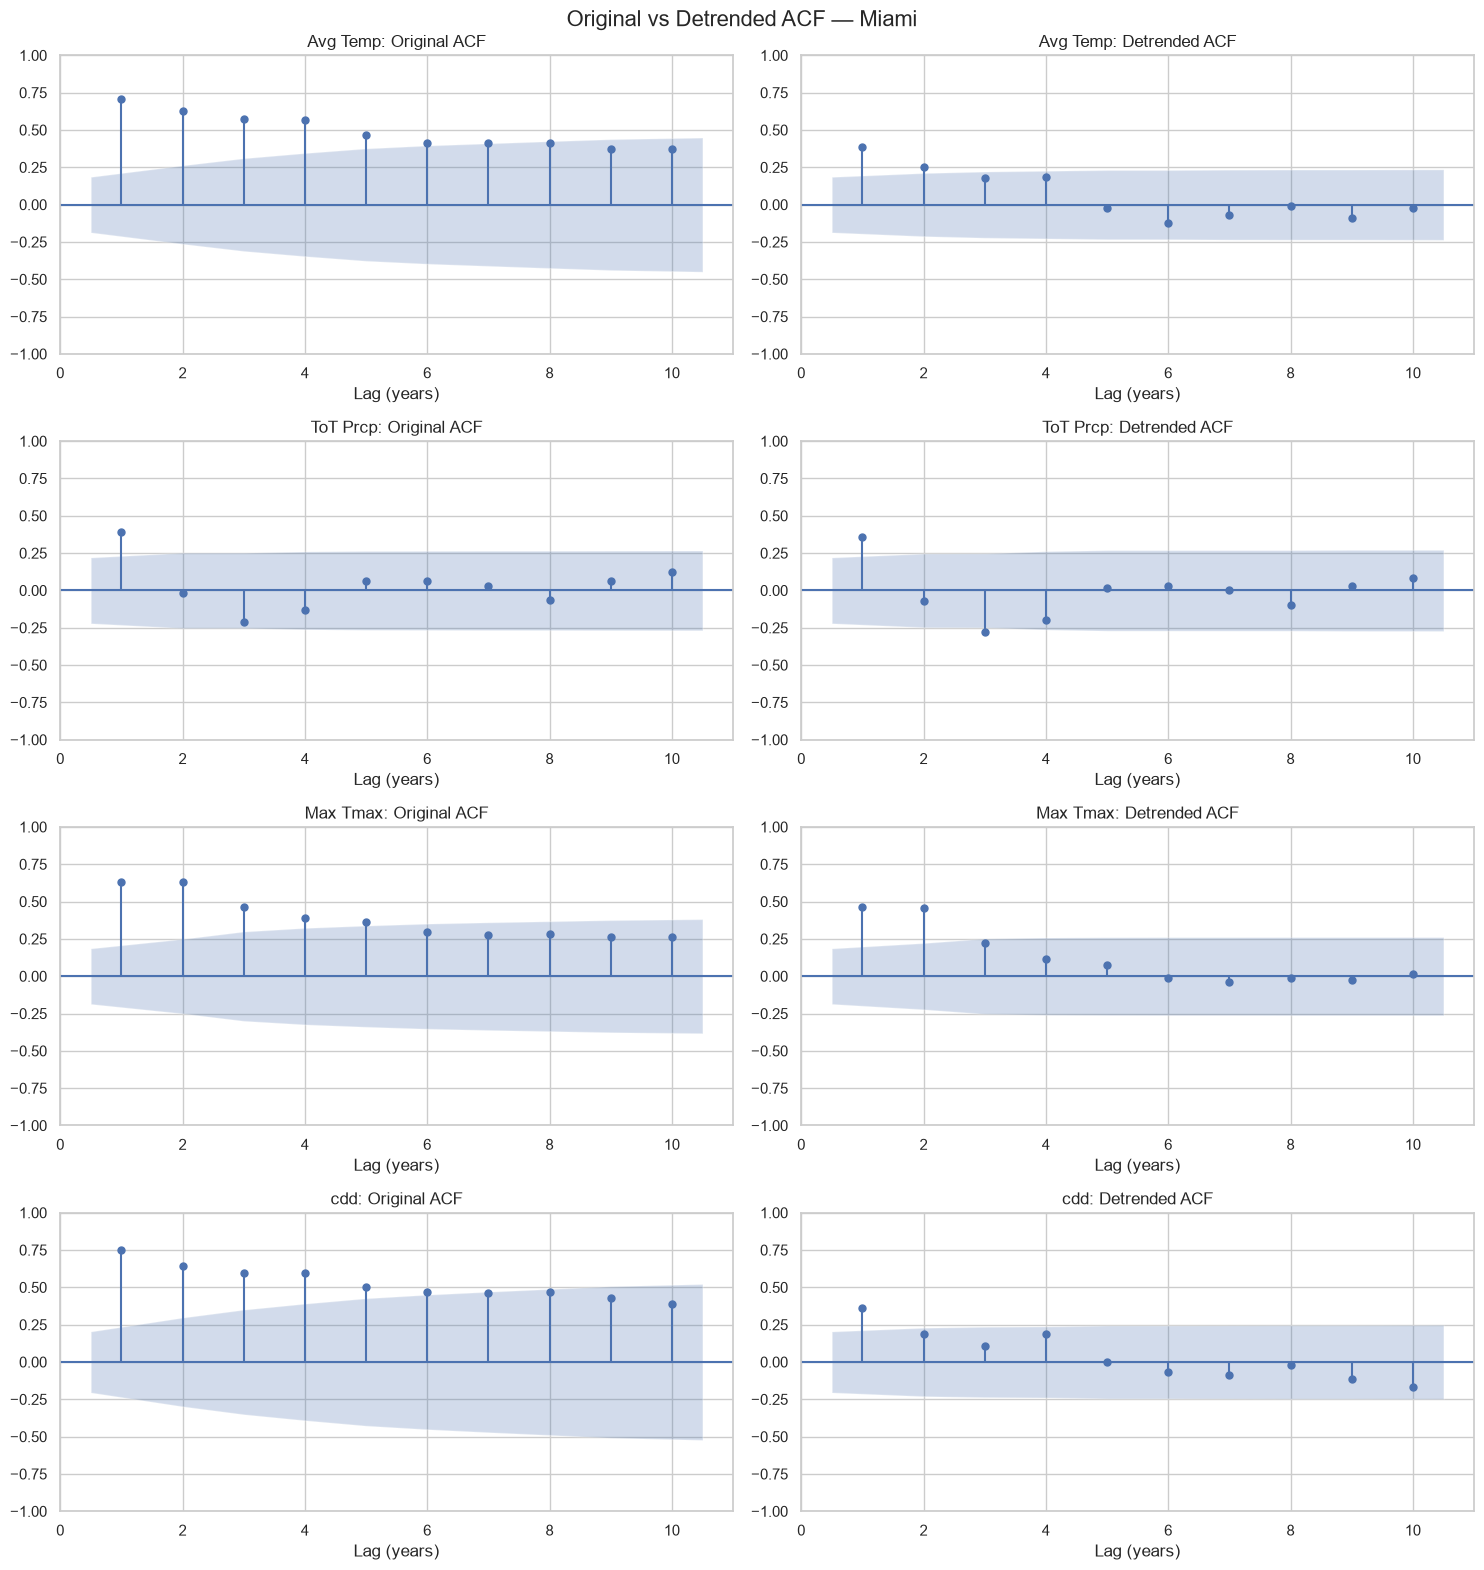

In [109]:
for city in selected_cities:

    fig, axes = plt.subplots(
        4, 2,
        figsize=(15, 16)
    )

    for i, target in enumerate(targets):

        series = get_city_series(city, target)
        continuous = longest_valid_run(series)

        if len(continuous) < MIN_YEARS:

            for ax in axes[i]:
                ax.text(
                    0.5, 0.5,
                    "Insufficient continuous data",
                    ha="center",
                    va="center",
                    transform=ax.transAxes
                )

            continue

        detrended = detrend_series(continuous)

        plot_acf(
            continuous,
            lags=MAX_LAGS,
            alpha=0.05,
            ax=axes[i, 0],
            zero=False
        )

        plot_acf(
            detrended,
            lags=MAX_LAGS,
            alpha=0.05,
            ax=axes[i, 1],
            zero=False
        )

        axes[i, 0].set_title(
            f"{target}: Original ACF"
        )

        axes[i, 1].set_title(
            f"{target}: Detrended ACF"
        )

        for ax in axes[i]:
            ax.set_xlabel("Lag (years)")

    plt.suptitle(
        f"Original vs Detrended ACF — {city}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

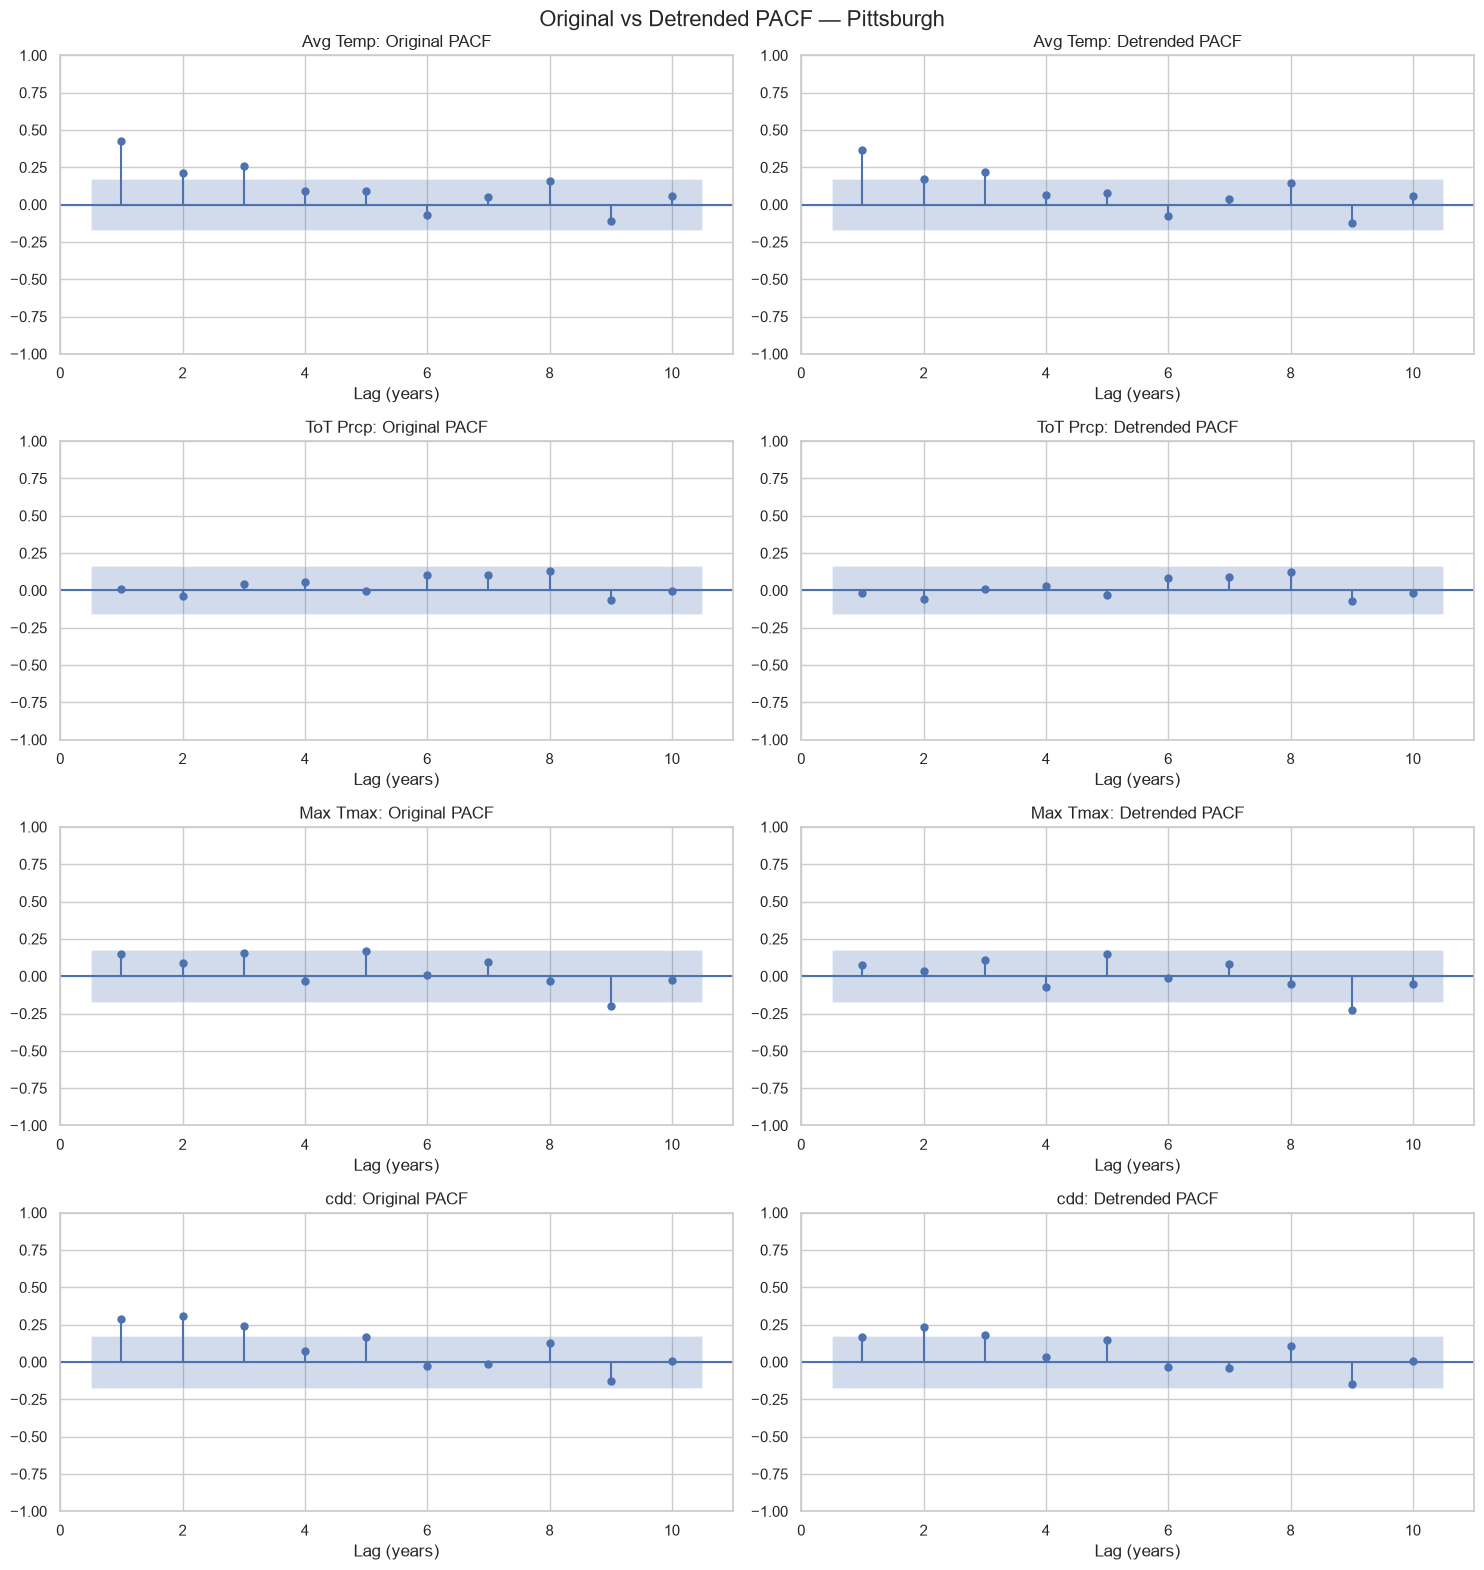

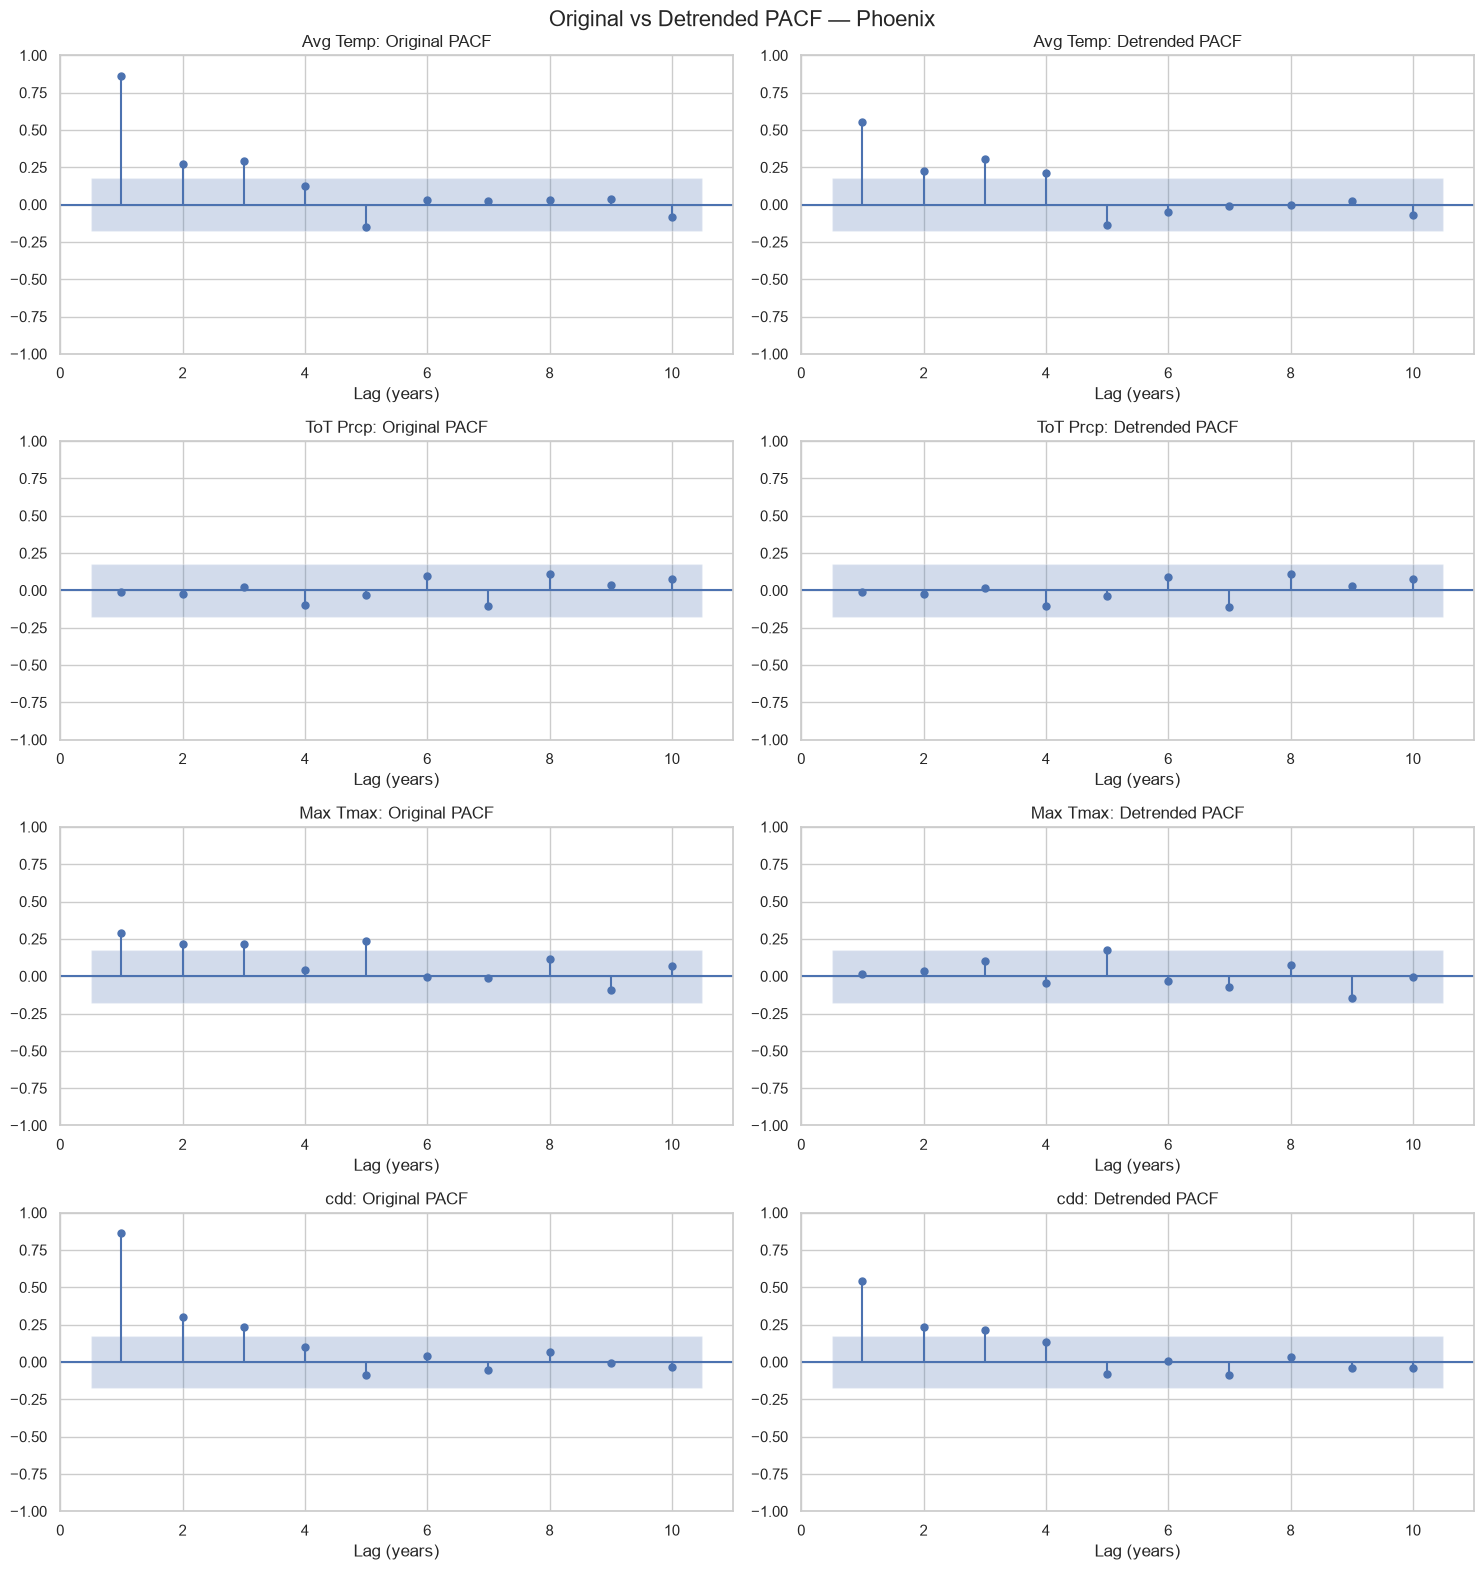

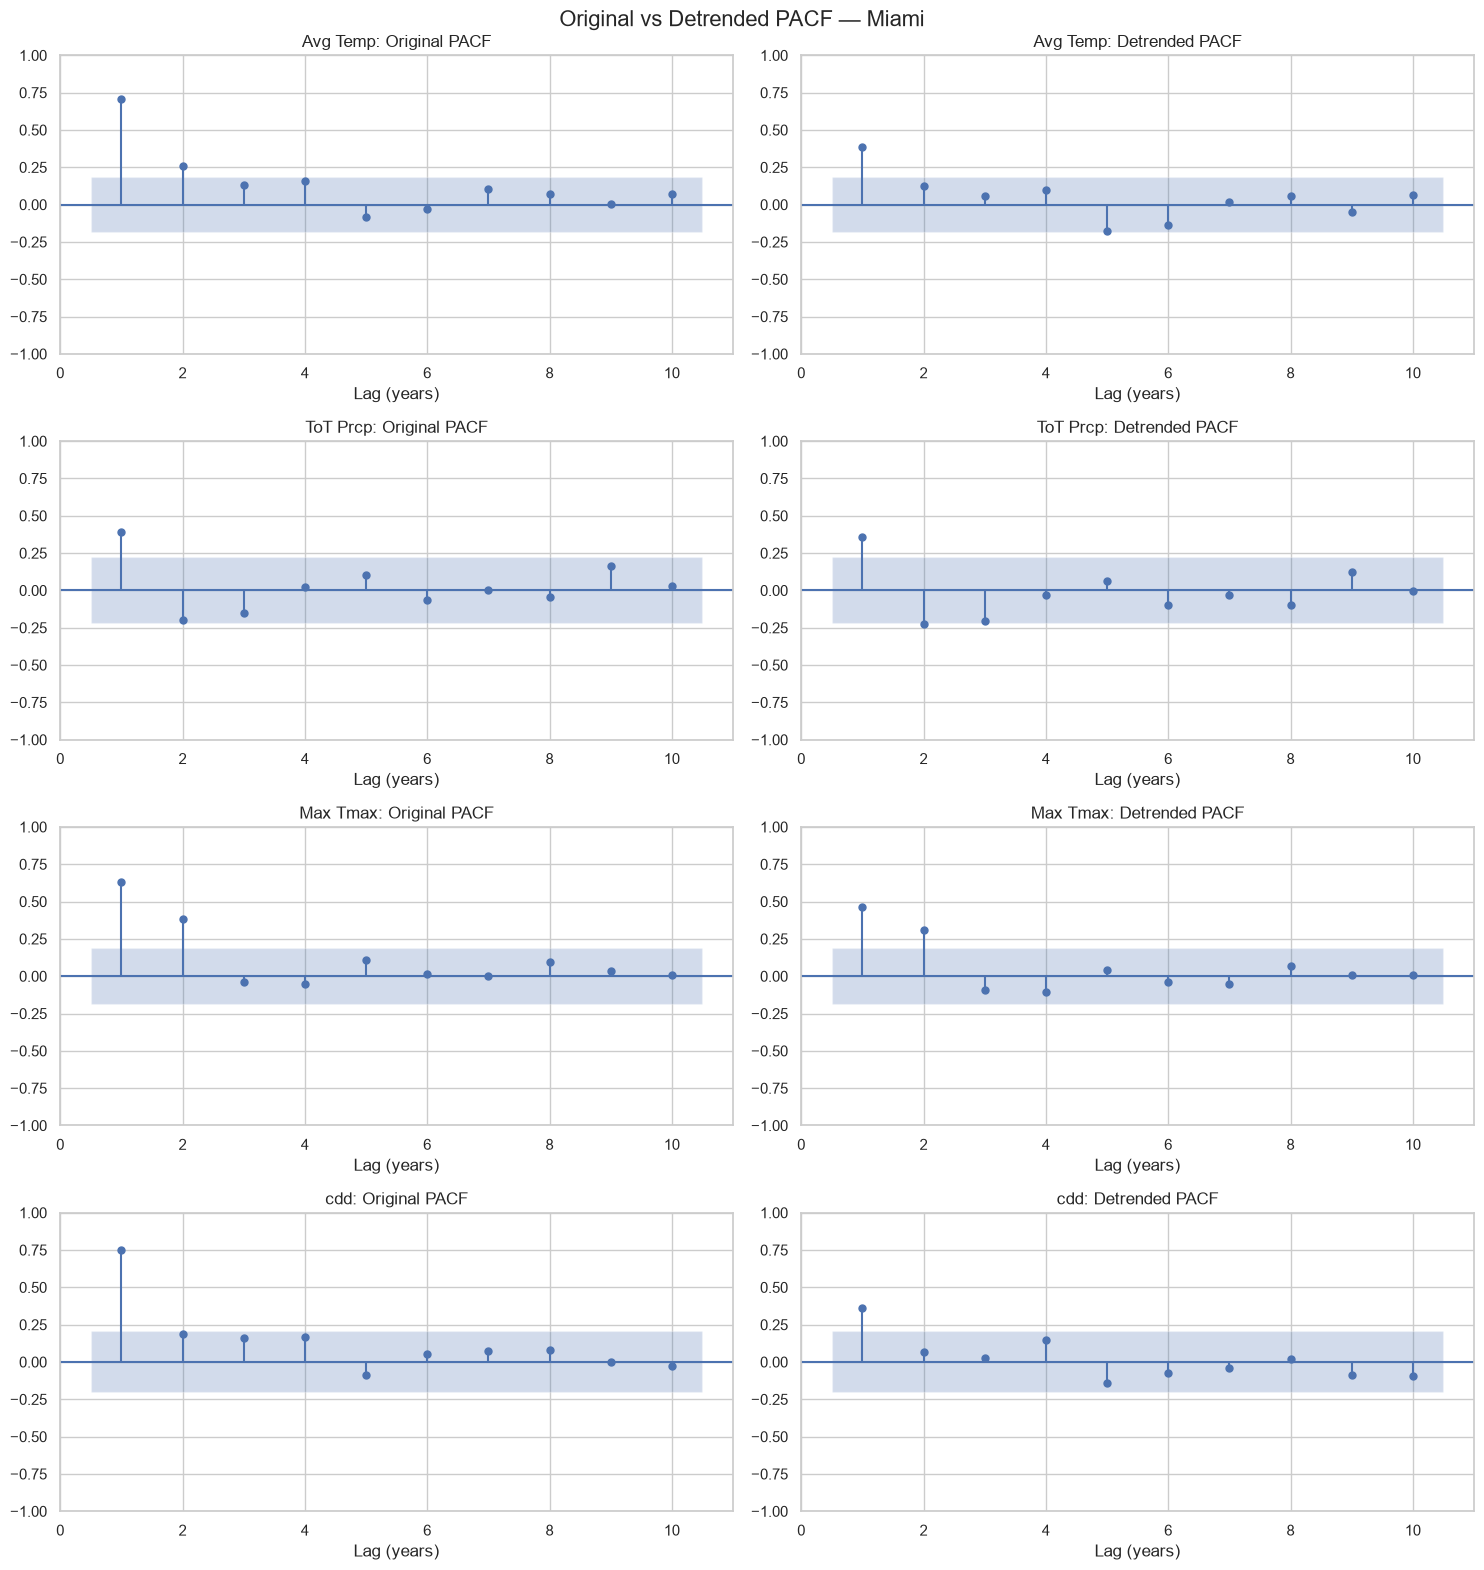

In [110]:
for city in selected_cities:

    fig, axes = plt.subplots(
        4, 2,
        figsize=(15, 16)
    )

    for i, target in enumerate(targets):

        series = get_city_series(city, target)
        continuous = longest_valid_run(series)

        if len(continuous) < MIN_YEARS:

            for ax in axes[i]:
                ax.text(
                    0.5, 0.5,
                    "Insufficient continuous data",
                    ha="center",
                    va="center",
                    transform=ax.transAxes
                )

            continue

        detrended = detrend_series(continuous)

        n_lags = min(
            MAX_LAGS,
            len(continuous) // 2 - 1
        )

        plot_pacf(
            continuous,
            lags=n_lags,
            method="ywm",
            alpha=0.05,
            ax=axes[i, 0],
            zero=False
        )

        plot_pacf(
            detrended,
            lags=n_lags,
            method="ywm",
            alpha=0.05,
            ax=axes[i, 1],
            zero=False
        )

        axes[i, 0].set_title(
            f"{target}: Original PACF"
        )

        axes[i, 1].set_title(
            f"{target}: Detrended PACF"
        )

        for ax in axes[i]:
            ax.set_xlabel("Lag (years)")

    plt.suptitle(
        f"Original vs Detrended PACF — {city}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

In [111]:
all_adf_results = []

for (city_id, city_name), city_data in ts_df.groupby(
    ["ID", "Name"]
):

    for target in targets:

        series = get_city_series(city_name, target)

        for specification in ["c", "ct"]:

            result = run_adf(
                series,
                regression=specification
            )

            all_adf_results.append({
                "ID": city_id,
                "Name": city_name,
                "Target": target,
                "Specification": specification,
                **result
            })

all_adf_results = pd.DataFrame(all_adf_results)

display(all_adf_results.head())

C:\Users\tanis\AppData\Local\Temp\ipykernel_28928\2599658515.py:30: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
C:\Users\tanis\AppData\Local\Temp\ipykernel_28928\2599658515.py:30: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
C:\Users\tanis\AppData\Local\Temp\ipykernel_28928\2599658515.py:30: FutureWarning: adfuller currentl

,ID,Name,Target,Specification,valid_years,start_year,end_year,adf_statistic,p_value,lags_used,conclusion
0,USC00042863,Escondido,Avg Temp,c,22,1957,1978,NaN,NaN,NaN,Insufficient data
1,USC00042863,Escondido,Avg Temp,ct,22,1957,1978,NaN,NaN,NaN,Insufficient data
2,USC00042863,Escondido,ToT Prcp,c,25,1931,1955,-4.419802,0.000274,0.0,Reject unit-root null
3,USC00042863,Escondido,ToT Prcp,ct,25,1931,1955,-2.296694,0.435779,7.0,Cannot reject unit-root null
4,USC00042863,Escondido,Max Tmax,c,22,1957,1978,NaN,NaN,NaN,Insufficient data


In [112]:
adf_summary = (
    all_adf_results
    .groupby(["Target", "Specification"])
    .agg(
        total_series=("ID", "count"),
        tested_series=("p_value", "count"),
        rejected_unit_root=(
            "p_value",
            lambda x: (x < 0.05).sum()
        ),
        median_p_value=("p_value", "median")
    )
    .reset_index()
)

adf_summary["rejection_pct"] = (
    adf_summary["rejected_unit_root"] /
    adf_summary["tested_series"].replace(0, np.nan)
    * 100
)

display(adf_summary.round(3))

,Target,Specification,total_series,tested_series,rejected_unit_root,median_p_value,rejection_pct
0,Avg Temp,c,210,196,111,0.007,56.633
1,Avg Temp,ct,210,196,141,0.000,71.939
2,Max Tmax,c,210,197,178,0.000,90.355
3,Max Tmax,ct,210,197,188,0.000,95.431
4,ToT Prcp,c,210,198,182,0.000,91.919
5,ToT Prcp,ct,210,198,183,0.000,92.424
6,cdd,c,210,185,118,0.007,63.784
7,cdd,ct,210,185,145,0.000,78.378


In [113]:
autocorr_results = []

for (city_id, city_name), city_data in ts_df.groupby(
    ["ID", "Name"]
):

    for target in targets:

        series = get_city_series(city_name, target)

        continuous = longest_valid_run(series)

        if len(continuous) < MIN_YEARS:
            continue

        if continuous.nunique() <= 1:
            continue

        detrended = detrend_series(continuous)

        if detrended.std() < 1e-10:
            continue

        raw_acf = acf(
            continuous,
            nlags=7,
            fft=False
        )

        detrended_acf = acf(
            detrended,
            nlags=7,
            fft=False
        )

        autocorr_results.append({
            "ID": city_id,
            "Name": city_name,
            "Target": target,
            "valid_years": len(continuous),
            "raw_lag1": raw_acf[1],
            "detrended_lag1": detrended_acf[1],
            "raw_mean_abs_acf_1_7": np.mean(
                np.abs(raw_acf[1:8])
            ),
            "detrended_mean_abs_acf_1_7": np.mean(
                np.abs(detrended_acf[1:8])
            )
        })

autocorr_results = pd.DataFrame(autocorr_results)

display(autocorr_results.head())

,ID,Name,Target,valid_years,raw_lag1,detrended_lag1,raw_mean_abs_acf_1_7,detrended_mean_abs_acf_1_7
0,USC00042863,Escondido,ToT Prcp,25,0.066688,-0.105579,0.120723,0.127109
1,USC00166584,Natchitoches,Avg Temp,28,0.190964,0.157878,0.112029,0.099633
2,USC00166584,Natchitoches,ToT Prcp,31,-0.136624,-0.154613,0.177639,0.184026
3,USC00166584,Natchitoches,Max Tmax,29,0.288680,0.275155,0.159414,0.152189
4,USC00280734,Belvidere,ToT Prcp,67,0.200319,0.192193,0.087383,0.084236


In [114]:
autocorr_summary = (
    autocorr_results
    .groupby("Target")
    .agg(
        cities_analyzed=("ID", "count"),
        median_raw_lag1=("raw_lag1", "median"),
        median_detrended_lag1=(
            "detrended_lag1", "median"
        ),
        median_raw_acf_1_7=(
            "raw_mean_abs_acf_1_7", "median"
        ),
        median_detrended_acf_1_7=(
            "detrended_mean_abs_acf_1_7", "median"
        )
    )
    .reset_index()
)

display(autocorr_summary.round(3))

,Target,cities_analyzed,median_raw_lag1,median_detrended_lag1,median_raw_acf_1_7,median_detrended_acf_1_7
0,Avg Temp,196,0.351,0.257,0.191,0.128
1,Max Tmax,197,0.177,0.125,0.106,0.085
2,ToT Prcp,198,0.069,0.046,0.089,0.082
3,cdd,185,0.267,0.191,0.174,0.128


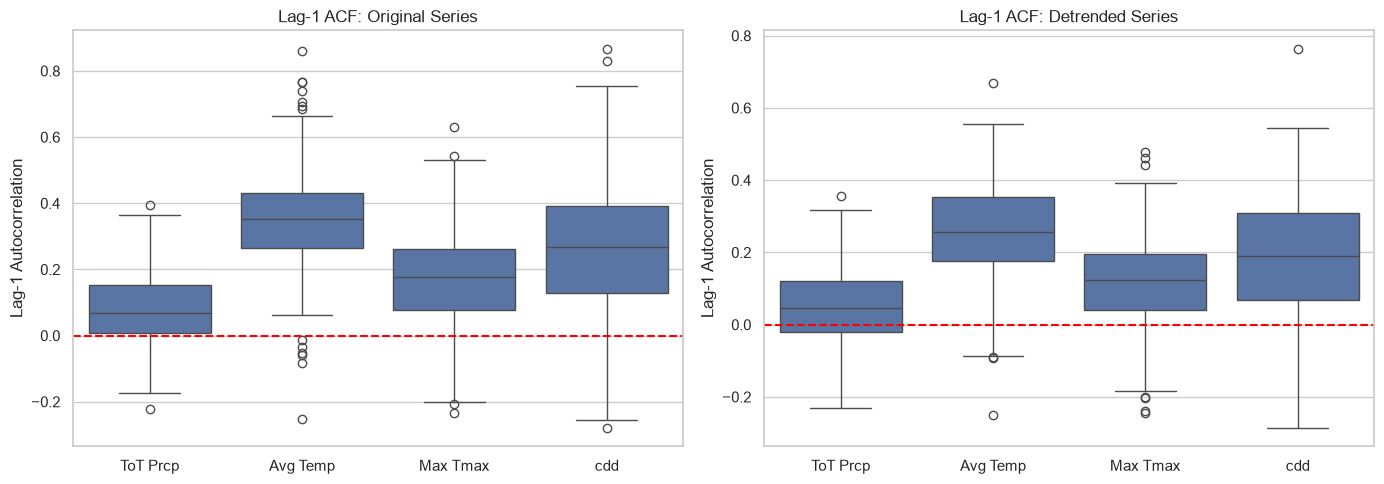

In [115]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

sns.boxplot(
    data=autocorr_results,
    x="Target",
    y="raw_lag1",
    ax=axes[0]
)

sns.boxplot(
    data=autocorr_results,
    x="Target",
    y="detrended_lag1",
    ax=axes[1]
)

axes[0].set_title("Lag-1 ACF: Original Series")
axes[1].set_title("Lag-1 ACF: Detrended Series")

for ax in axes:
    ax.axhline(0, color="red", linestyle="--")
    ax.set_xlabel("")
    ax.set_ylabel("Lag-1 Autocorrelation")

plt.tight_layout()
plt.show()

In [116]:
# ADF summary using the trend-inclusive specification
adf_final = (
    adf_summary[
        adf_summary["Specification"] == "ct"
    ][
        ["Target", "tested_series", "rejection_pct"]
    ]
    .rename(columns={
        "tested_series": "ADF Tested Cities",
        "rejection_pct": "ADF Rejection %"
    })
)

# Autocorrelation summary
acf_final = autocorr_summary[
    [
        "Target",
        "cities_analyzed",
        "median_raw_lag1",
        "median_detrended_lag1",
        "median_detrended_acf_1_7"
    ]
].rename(columns={
    "cities_analyzed": "ACF Analyzed Cities",
    "median_raw_lag1": "Raw Lag-1 ACF",
    "median_detrended_lag1": "Detrended Lag-1 ACF",
    "median_detrended_acf_1_7": "Detrended Mean |ACF| (1–7)"
})

checkpoint6_report = adf_final.merge(
    acf_final,
    on="Target",
    how="outer"
)

display(checkpoint6_report.round(3))

,Target,ADF Tested Cities,ADF Rejection %,ACF Analyzed Cities,Raw Lag-1 ACF,Detrended Lag-1 ACF,Detrended Mean |ACF| (1–7)
0,Avg Temp,196,71.939,196,0.351,0.257,0.128
1,Max Tmax,197,95.431,197,0.177,0.125,0.085
2,ToT Prcp,198,92.424,198,0.069,0.046,0.082
3,cdd,185,78.378,185,0.267,0.191,0.128


### Daily Dataset EDA

In [122]:
sns.set_theme(style="whitegrid")

print("Daily dataset shape:", daily.shape)
print("\nColumns:", daily.columns.tolist())

display(daily.head())

print("\nData types:")
display(daily.dtypes)

print("\nUnique cities:", daily["ID"].nunique())

print(
    "Date range:",
    daily["Date"].min(),
    "to",
    daily["Date"].max()
)

Daily dataset shape: (10245754, 6)

Columns: ['ID', 'Name', 'Date', 'tmax', 'tmin', 'prcp']


,ID,Name,Date,tmax,tmin,prcp
0,USW00014929,Aberdeen,1893-01-01,30.0,8.0,0.0
1,USW00014929,Aberdeen,1893-01-02,NaN,-10.0,0.0
2,USW00014929,Aberdeen,1893-01-03,24.0,-3.0,NaN
3,USW00014929,Aberdeen,1893-01-04,37.0,18.0,0.0
4,USW00014929,Aberdeen,1893-01-05,28.0,-10.0,0.0



Data types:


ID          str
Name        str
Date     object
tmax    float64
tmin    float64
prcp    float64
dtype: object


Unique cities: 210
Date range: 1851-01-01 to 2018-12-31


In [123]:
daily = daily.copy()

daily["Date"] = pd.to_datetime(daily["Date"])

daily["Year"] = daily["Date"].dt.year
daily["Month"] = daily["Date"].dt.month

weather_cols = ["tmax", "tmin", "prcp"]

# One row should represent one city and date
print(
    "Duplicate ID-Date records:",
    daily.duplicated(["ID", "Date"]).sum()
)

missing_summary = pd.DataFrame({
    "Missing Count": daily[weather_cols].isna().sum(),
    "Missing %": daily[weather_cols].isna().mean() * 100
})

display(missing_summary.round(2))

Duplicate ID-Date records: 0


,Missing Count,Missing %
tmax,582294,5.68
tmin,581392,5.67
prcp,523534,5.11


In [124]:
daily["incomplete_temp_day"] = (
    daily["tmax"].isna() |
    daily["tmin"].isna()
)

daily["missing_tmax"] = daily["tmax"].isna()
daily["missing_tmin"] = daily["tmin"].isna()
daily["missing_prcp"] = daily["prcp"].isna()

In [125]:
# Summarize available daily rows
daily_quality = (
    daily.groupby(["ID", "Year"])
    .agg(
        days_present=("Date", "nunique"),
        missing_tmax=("missing_tmax", "sum"),
        missing_tmin=("missing_tmin", "sum"),
        missing_prcp=("missing_prcp", "sum"),
        incomplete_temp_days=("incomplete_temp_day", "sum")
    )
    .reset_index()
)

# Calculate number of calendar days in each year
daily_quality["days_in_year"] = np.where(
    (
        (daily_quality["Year"] % 4 == 0) &
        (
            (daily_quality["Year"] % 100 != 0) |
            (daily_quality["Year"] % 400 == 0)
        )
    ),
    366,
    365
)

daily_quality["absent_dates"] = (
    daily_quality["days_in_year"] -
    daily_quality["days_present"]
)

# Total unavailable days for each weather variable
daily_quality["actual_missing_tmax"] = (
    daily_quality["missing_tmax"] +
    daily_quality["absent_dates"]
)

daily_quality["actual_missing_tmin"] = (
    daily_quality["missing_tmin"] +
    daily_quality["absent_dates"]
)

daily_quality["actual_missing_prcp"] = (
    daily_quality["missing_prcp"] +
    daily_quality["absent_dates"]
)

daily_quality["actual_incomplete_temp_days"] = (
    daily_quality["incomplete_temp_days"] +
    daily_quality["absent_dates"]
)

display(daily_quality.head())

,ID,Year,days_present,missing_tmax,missing_tmin,missing_prcp,incomplete_temp_days,days_in_year,absent_dates,actual_missing_tmax,actual_missing_tmin,actual_missing_prcp,actual_incomplete_temp_days
0,USC00042863,1894,365,61,61,236,61,365,0,61,61,236,61
1,USC00042863,1895,365,4,0,319,4,365,0,4,0,319,4
2,USC00042863,1896,366,0,0,323,0,366,0,0,0,323,0
3,USC00042863,1897,365,0,0,236,0,365,0,0,0,236,0
4,USC00042863,1898,365,0,0,122,0,365,0,0,0,122,0


In [126]:
quality_comparison = annual[
    [
        "ID",
        "Year",
        "Miss Tmax",
        "Miss Tmin",
        "Miss Prcp"
    ]
].merge(
    daily_quality[
        [
            "ID",
            "Year",
            "actual_missing_tmax",
            "actual_missing_tmin",
            "actual_missing_prcp",
            "actual_incomplete_temp_days"
        ]
    ],
    on=["ID", "Year"],
    how="left",
    validate="one_to_one"
)

for annual_col, daily_col in [
    ("Miss Tmax", "actual_missing_tmax"),
    ("Miss Tmin", "actual_missing_tmin"),
    ("Miss Prcp", "actual_missing_prcp")
]:

    mismatches = (
        quality_comparison[annual_col] !=
        quality_comparison[daily_col]
    )

    print(
        f"{annual_col} mismatches:",
        mismatches.sum()
    )

Miss Tmax mismatches: 0
Miss Tmin mismatches: 0
Miss Prcp mismatches: 0


In [127]:
# Select uncertain cdd city-years
uncertain_cdd = eda.loc[
    eda["cdd_quality"] == "needs_daily_check",
    ["ID", "Name", "Year", "cdd"]
].copy()

print("Uncertain cdd records:", len(uncertain_cdd))

# Join exact incomplete-temperature-day counts
uncertain_cdd = uncertain_cdd.merge(
    daily_quality[
        [
            "ID",
            "Year",
            "actual_incomplete_temp_days"
        ]
    ],
    on=["ID", "Year"],
    how="left",
    validate="one_to_one"
)

# Assign quality status
uncertain_cdd["resolved_quality"] = np.select(
    [
        uncertain_cdd["actual_incomplete_temp_days"].isna(),
        uncertain_cdd["actual_incomplete_temp_days"] <= 10,
        uncertain_cdd["actual_incomplete_temp_days"] > 10
    ],
    [
        "unresolved",
        "valid",
        "invalid"
    ],
    default="unresolved"
)

display(
    uncertain_cdd["resolved_quality"]
    .value_counts()
)

display(uncertain_cdd.head(15))

Uncertain cdd records: 609


resolved_quality
invalid    348
valid      261
Name: count, dtype: int64

,ID,Name,Year,cdd,actual_incomplete_temp_days,resolved_quality
0,USW00014929,Aberdeen,1896,606.5,13,invalid
1,USW00014929,Aberdeen,1898,592.5,12,invalid
2,USW00014929,Aberdeen,1899,701.5,18,invalid
3,USW00014929,Aberdeen,1905,415.0,13,invalid
4,USW00014929,Aberdeen,1917,434.5,12,invalid
5,USW00014929,Aberdeen,1922,879.5,11,invalid
6,USW00014929,Aberdeen,1923,703.5,14,invalid
7,USW00014929,Aberdeen,1924,349.5,13,invalid
8,USW00014929,Aberdeen,1930,887.0,13,invalid
9,USW00014929,Aberdeen,1932,896.5,11,invalid


In [128]:
# Preserve the original classification
eda["cdd_quality_original"] = eda["cdd_quality"]

resolved_lookup = uncertain_cdd[
    ["ID", "Year", "resolved_quality"]
]

eda = eda.merge(
    resolved_lookup,
    on=["ID", "Year"],
    how="left",
    validate="one_to_one"
)

mask = (
    eda["cdd_quality"] == "needs_daily_check"
) & (
    eda["resolved_quality"].isin(["valid", "invalid"])
)

eda.loc[mask, "cdd_quality"] = (
    eda.loc[mask, "resolved_quality"]
)

eda["cdd_clean"] = eda["cdd"].where(
    eda["cdd_quality"] == "valid"
)

eda = eda.drop(columns=["resolved_quality"])

print("Updated cdd classification:")

display(eda["cdd_quality"].value_counts())

print(
    "\nValid cdd observations:",
    eda["cdd_clean"].notna().sum()
)

Updated cdd classification:


cdd_quality
valid             24235
invalid            2611
missing_target     1206
Name: count, dtype: int64


Valid cdd observations: 24235


In [129]:
daily["daily_mean_temp"] = (
    daily["tmax"] + daily["tmin"]
) / 2

daily["daily_cdd"] = (
    daily["daily_mean_temp"] - 65
).clip(lower=0)

annual_from_daily = (
    daily.groupby(["ID", "Year"])
    .agg(
        avg_tmax=("tmax", "mean"),
        avg_tmin=("tmin", "mean"),
        total_precip=("prcp", "sum"),
        hottest_day=("tmax", "max"),
        calculated_cdd=("daily_cdd", "sum")
    )
    .reset_index()
)

# Match the annual dataset's definition:
# Avg Temp = (mean Tmax + mean Tmin) / 2
annual_from_daily["calculated_avg_temp"] = (
    annual_from_daily["avg_tmax"] +
    annual_from_daily["avg_tmin"]
) / 2

In [130]:
validation = annual[
    [
        "ID",
        "Name",
        "Year",
        "Avg Temp",
        "ToT Prcp",
        "Max Tmax",
        "cdd"
    ]
].merge(
    annual_from_daily,
    on=["ID", "Year"],
    how="left",
    validate="one_to_one"
)

comparisons = {
    "Avg Temp": "calculated_avg_temp",
    "ToT Prcp": "total_precip",
    "Max Tmax": "hottest_day",
    "cdd": "calculated_cdd"
}

validation_summary = []

for original, calculated in comparisons.items():

    difference = (
        validation[original] -
        validation[calculated]
    ).abs()

    validation_summary.append({
        "Target": original,
        "Compared Records": difference.notna().sum(),
        "Mean Absolute Difference": difference.mean(),
        "Maximum Absolute Difference": difference.max()
    })

validation_summary = pd.DataFrame(validation_summary)

display(validation_summary.round(4))

,Target,Compared Records,Mean Absolute Difference,Maximum Absolute Difference
0,Avg Temp,26859,0.0033,0.0099
1,ToT Prcp,28052,0.0000,0.0000
2,Max Tmax,26868,0.0000,0.0000
3,cdd,26846,0.0000,0.0000


In [131]:
for original, calculated in comparisons.items():

    difference = (
        validation[original] -
        validation[calculated]
    ).abs()

    # Diagnostic threshold, not a cleaning rule
    suspicious = validation.loc[
        difference > 0.1,
        [
            "Name",
            "ID",
            "Year",
            original,
            calculated
        ]
    ].copy()

    suspicious["absolute_difference"] = difference[
        difference > 0.1
    ]

    print(f"\nLargest discrepancies: {original}")

    display(
        suspicious
        .sort_values(
            "absolute_difference",
            ascending=False
        )
        .head(10)
    )


Largest discrepancies: Avg Temp


,Name,ID,Year,Avg Temp,calculated_avg_temp,absolute_difference



Largest discrepancies: ToT Prcp


,Name,ID,Year,ToT Prcp,total_precip,absolute_difference



Largest discrepancies: Max Tmax


,Name,ID,Year,Max Tmax,hottest_day,absolute_difference



Largest discrepancies: cdd


,Name,ID,Year,cdd,calculated_cdd,absolute_difference


In [132]:
monthly = (
    daily.groupby(["ID", "Name", "Year", "Month"])
    .agg(
        avg_tmax=("tmax", "mean"),
        avg_tmin=("tmin", "mean"),
        monthly_precip=("prcp", "sum"),
        observed_tmax=("tmax", "count"),
        observed_tmin=("tmin", "count"),
        observed_prcp=("prcp", "count")
    )
    .reset_index()
)

monthly["avg_temp"] = (
    monthly["avg_tmax"] +
    monthly["avg_tmin"]
) / 2

display(monthly.head())

,ID,Name,Year,Month,avg_tmax,avg_tmin,monthly_precip,observed_tmax,observed_tmin,observed_prcp,avg_temp
0,USC00042863,Escondido,1894,1,61.838710,39.774194,1.18,31,31,31,50.806452
1,USC00042863,Escondido,1894,2,65.607143,41.714286,0.50,28,28,28,53.660714
2,USC00042863,Escondido,1894,3,70.645161,44.612903,0.85,31,31,31,57.629032
3,USC00042863,Escondido,1894,4,73.100000,49.400000,0.00,30,30,30,61.250000
4,USC00042863,Escondido,1894,5,NaN,NaN,0.00,0,0,0,NaN


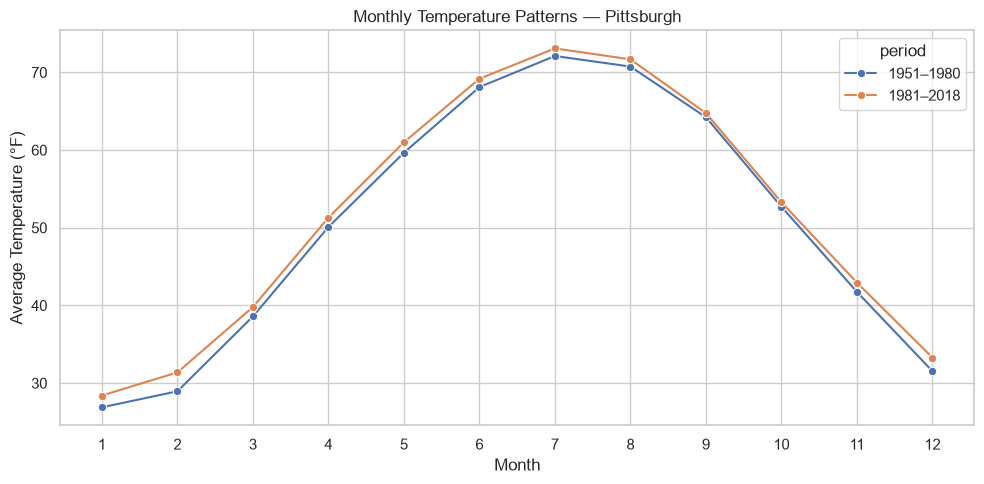

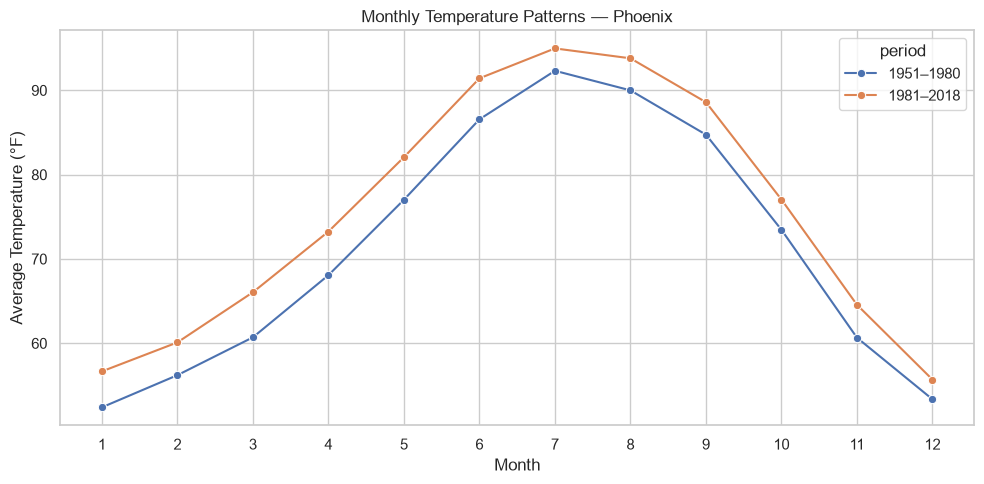

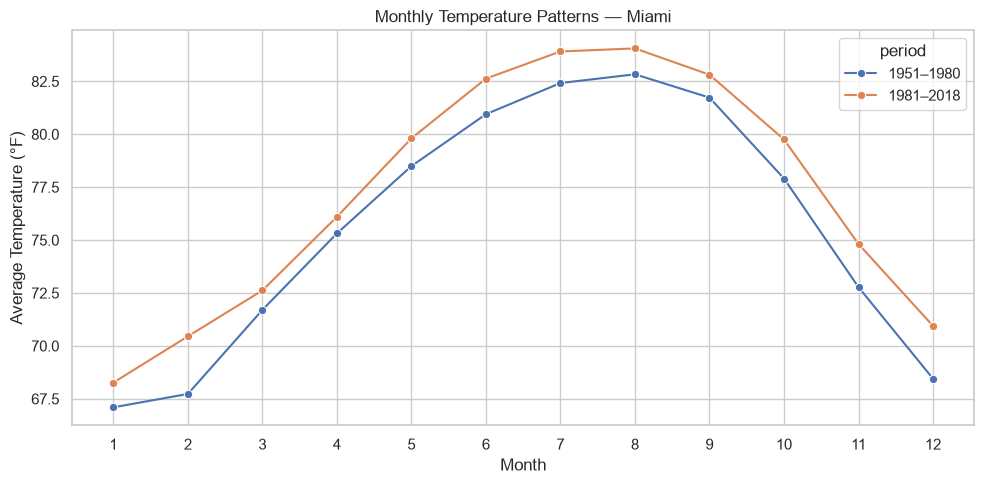

In [133]:
monthly["season"] = monthly["Month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
})

selected_cities = [
    "Pittsburgh",
    "Phoenix",
    "Miami"
]

for city in selected_cities:

    city_monthly = monthly[
        monthly["Name"] == city
    ].copy()

    # Compare historical periods
    city_monthly["period"] = pd.cut(
        city_monthly["Year"],
        bins=[1950, 1980, 2018],
        labels=["1951–1980", "1981–2018"]
    )

    seasonal_summary = (
        city_monthly
        .groupby(["period", "Month"], observed=True)
        ["avg_temp"]
        .mean()
        .reset_index()
    )

    plt.figure(figsize=(10, 5))

    sns.lineplot(
        data=seasonal_summary,
        x="Month",
        y="avg_temp",
        hue="period",
        marker="o"
    )

    plt.title(f"Monthly Temperature Patterns — {city}")
    plt.xlabel("Month")
    plt.ylabel("Average Temperature (°F)")
    plt.xticks(range(1, 13))
    plt.tight_layout()
    plt.show()

In [134]:
seasonal_temp = (
    monthly.groupby(
        ["ID", "Name", "Year", "season"]
    )["avg_temp"]
    .mean()
    .reset_index()
)

seasonal_temp = seasonal_temp[
    seasonal_temp["season"].isin(["Summer", "Winter"])
]

display(seasonal_temp.head())

,ID,Name,Year,season,avg_temp
2,USC00042863,Escondido,1894,Summer,72.854839
3,USC00042863,Escondido,1894,Winter,52.037442
6,USC00042863,Escondido,1895,Summer,72.487789
7,USC00042863,Escondido,1895,Winter,51.658589
10,USC00042863,Escondido,1896,Summer,73.796953


In [135]:
from scipy.stats import linregress

seasonal_trends = []

recent_seasonal = seasonal_temp[
    seasonal_temp["Year"].between(1989, 2018)
]

for (city_id, city_name, season), group in (
    recent_seasonal.groupby(["ID", "Name", "season"])
):

    valid = group.dropna(subset=["avg_temp"])

    if len(valid) < 20:
        continue

    result = linregress(
        valid["Year"],
        valid["avg_temp"]
    )

    seasonal_trends.append({
        "ID": city_id,
        "Name": city_name,
        "season": season,
        "slope_per_decade": result.slope * 10,
        "r_squared": result.rvalue ** 2,
        "valid_years": len(valid)
    })

seasonal_trends = pd.DataFrame(seasonal_trends)

display(seasonal_trends.head())

,ID,Name,season,slope_per_decade,r_squared,valid_years
0,USC00042863,Escondido,Summer,0.857943,0.192144,29
1,USC00042863,Escondido,Winter,0.575971,0.093360,29
2,USC00166584,Natchitoches,Summer,0.676726,0.080375,30
3,USC00166584,Natchitoches,Winter,0.610028,0.057034,30
4,USC00280734,Belvidere,Summer,0.239598,0.015495,30


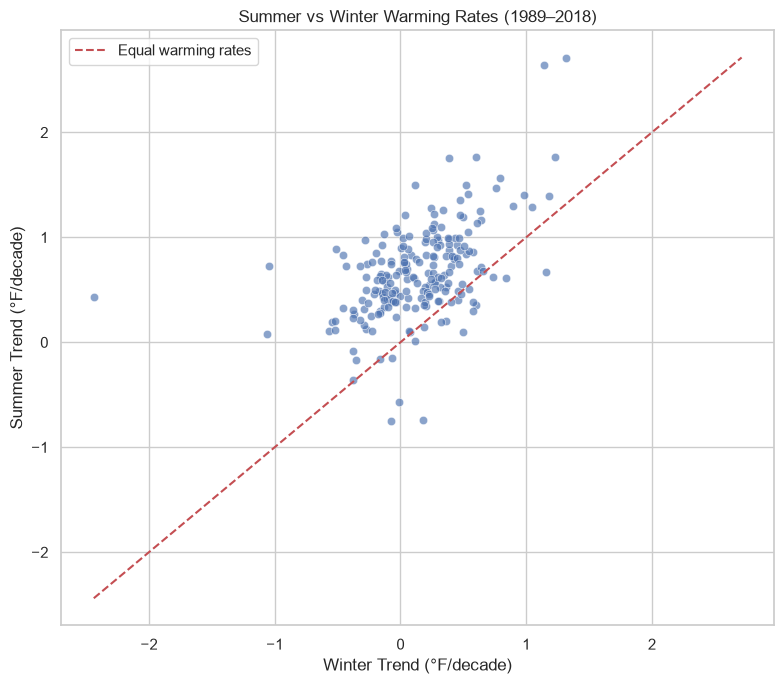

In [136]:
seasonal_comparison = (
    seasonal_trends
    .pivot(
        index=["ID", "Name"],
        columns="season",
        values="slope_per_decade"
    )
    .dropna()
    .reset_index()
)

plt.figure(figsize=(8, 7))

sns.scatterplot(
    data=seasonal_comparison,
    x="Winter",
    y="Summer",
    alpha=0.65
)

limits = [
    min(
        seasonal_comparison["Winter"].min(),
        seasonal_comparison["Summer"].min()
    ),
    max(
        seasonal_comparison["Winter"].max(),
        seasonal_comparison["Summer"].max()
    )
]

plt.plot(
    limits,
    limits,
    "r--",
    label="Equal warming rates"
)

plt.xlabel("Winter Trend (°F/decade)")
plt.ylabel("Summer Trend (°F/decade)")
plt.title("Summer vs Winter Warming Rates (1989–2018)")
plt.legend()
plt.tight_layout()
plt.show()

In [137]:
daily["hot_day_90"] = daily["tmax"] >= 90

hot_day_counts = (
    daily.groupby(["ID", "Name", "Year"])
    .agg(
        hot_days_90=("hot_day_90", "sum"),
        observed_tmax_days=("tmax", "count")
    )
    .reset_index()
)

# Only use years with sufficient Tmax observations
hot_day_counts["valid_hot_day_count"] = (
    hot_day_counts["observed_tmax_days"] >=
    np.where(
        (
            (hot_day_counts["Year"] % 4 == 0) &
            (
                (hot_day_counts["Year"] % 100 != 0) |
                (hot_day_counts["Year"] % 400 == 0)
            )
        ),
        356,
        355
    )
)

hot_day_counts["hot_days_90_clean"] = (
    hot_day_counts["hot_days_90"].where(
        hot_day_counts["valid_hot_day_count"]
    )
)

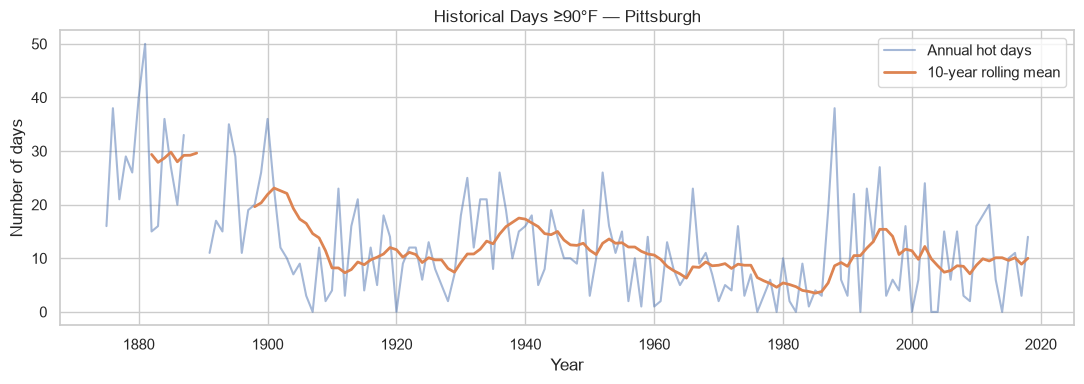

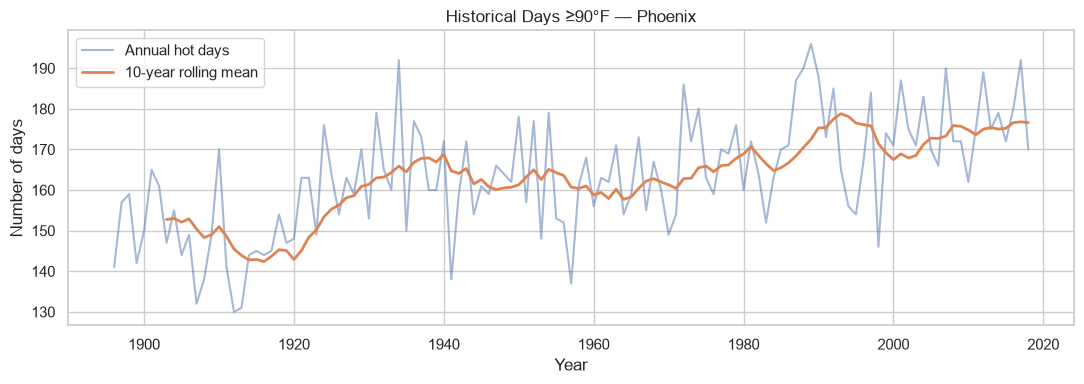

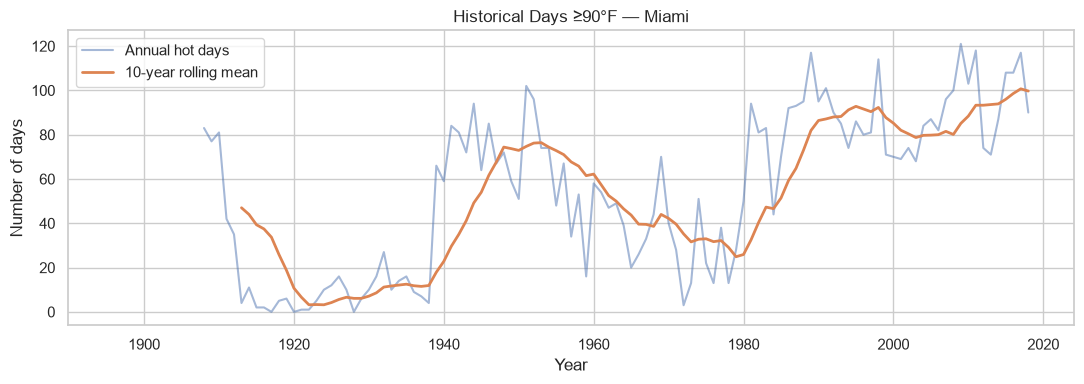

In [138]:
for city in selected_cities:

    city_hot_days = hot_day_counts[
        hot_day_counts["Name"] == city
    ].sort_values("Year")

    plt.figure(figsize=(11, 4))

    plt.plot(
        city_hot_days["Year"],
        city_hot_days["hot_days_90_clean"],
        alpha=0.5,
        label="Annual hot days"
    )

    rolling = (
        city_hot_days["hot_days_90_clean"]
        .rolling(10, min_periods=8)
        .mean()
    )

    plt.plot(
        city_hot_days["Year"],
        rolling,
        linewidth=2,
        label="10-year rolling mean"
    )

    plt.title(f"Historical Days ≥90°F — {city}")
    plt.xlabel("Year")
    plt.ylabel("Number of days")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [139]:
daily_quality_report = pd.DataFrame({
    "Metric": [
        "Unique cities",
        "Daily rows",
        "City-years examined",
        "Uncertain cdd records",
        "Resolved valid cdd",
        "Resolved invalid cdd",
        "Unresolved cdd"
    ],
    "Value": [
        daily["ID"].nunique(),
        len(daily),
        daily_quality[["ID", "Year"]].drop_duplicates().shape[0],
        len(uncertain_cdd),
        (uncertain_cdd["resolved_quality"] == "valid").sum(),
        (uncertain_cdd["resolved_quality"] == "invalid").sum(),
        (uncertain_cdd["resolved_quality"] == "unresolved").sum()
    ]
})

display(daily_quality_report)

,Metric,Value
0,Unique cities,210
1,Daily rows,10245754
2,City-years examined,28052
3,Uncertain cdd records,609
4,Resolved valid cdd,261
5,Resolved invalid cdd,348
6,Unresolved cdd,0


In [140]:
seasonal_trend_report = (
    seasonal_trends.groupby("season")
    .agg(
        cities_analyzed=("ID", "count"),
        median_warming_rate=("slope_per_decade", "median"),
        mean_warming_rate=("slope_per_decade", "mean"),
        median_r_squared=("r_squared", "median")
    )
    .reset_index()
)

display(seasonal_trend_report.round(3))

,season,cities_analyzed,median_warming_rate,mean_warming_rate,median_r_squared
0,Summer,209,0.626,0.665,0.104
1,Winter,209,0.149,0.138,0.007


### City Dataset

In [144]:
cities = city.copy()
sns.set_theme(style="whitegrid")

print("Dataset shape:", cities.shape)
print("\nColumns:", cities.columns.tolist())

display(cities.head())

print("\nData types:")
display(cities.dtypes)

print("\nUnique cities:", cities["ID"].nunique())

print("\nMissing values:")
display(cities.isna().sum())

Dataset shape: (461, 7)

Columns: ['Name', 'ID', 'Lat', 'Lon', 'Stn.Name', 'Stn.stDate', 'Stn.edDate']


,Name,ID,Lat,Lon,Stn.Name,Stn.stDate,Stn.edDate
0,Lander,USW00024021,42.8153,-108.7261,LANDER WBO,1892-01-01,1946-05-28
1,Lander,USW00024021,42.8153,-108.7261,LANDER HUNT FIELD,1946-05-29,2018-12-31
2,Cheyenne,USW00024018,41.1519,-104.8061,CHEYENNE WBO,1871-01-01,1935-08-31
3,Cheyenne,USW00024018,41.1519,-104.8061,CHEYENNE MUNICIPAL ARPT,1935-09-01,2018-12-31
4,Wausau,USW00014897,44.9258,-89.6256,Wausau Record Herald,1896-01-01,1941-12-31



Data types:


Name              str
ID                str
Lat           float64
Lon           float64
Stn.Name          str
Stn.stDate     object
Stn.edDate     object
dtype: object


Unique cities: 210

Missing values:


Name          0
ID            0
Lat           0
Lon           0
Stn.Name      0
Stn.stDate    0
Stn.edDate    0
dtype: int64

In [145]:
city_info = cities.copy()

city_info["Stn.stDate"] = pd.to_datetime(
    city_info["Stn.stDate"],
    errors="coerce"
)

city_info["Stn.edDate"] = pd.to_datetime(
    city_info["Stn.edDate"],
    errors="coerce"
)

city_info = city_info.sort_values(
    ["ID", "Stn.stDate"]
).reset_index(drop=True)

display(city_info.head())

,Name,ID,Lat,Lon,Stn.Name,Stn.stDate,Stn.edDate
0,Escondido,USC00042863,33.1211,-117.0900,Escondido,1894-01-01,1979-03-31
1,Escondido,USC00042863,33.1211,-117.0900,Escondido 2,1979-04-01,2018-12-31
2,Natchitoches,USC00166584,31.8142,-93.0856,Natchitoches,1894-01-01,2010-07-31
3,Natchitoches,USC00166584,31.8142,-93.0856,Natchitoches #2,2010-08-01,2018-12-31
4,Belvidere,USC00280734,40.8292,-75.0833,Belvidere,1893-01-01,1981-10-31


In [146]:
invalid_dates = city_info[
    city_info["Stn.stDate"].notna() &
    city_info["Stn.edDate"].notna() &
    (
        city_info["Stn.stDate"] >
        city_info["Stn.edDate"]
    )
]

print("Station periods with invalid dates:", len(invalid_dates))

display(invalid_dates.head())

Station periods with invalid dates: 0


,Name,ID,Lat,Lon,Stn.Name,Stn.stDate,Stn.edDate


In [147]:
station_counts = (
    city_info.groupby(["ID", "Name"])
    .agg(
        station_records=("Stn.Name", "size"),
        unique_stations=("Stn.Name", "nunique"),
        first_station_date=("Stn.stDate", "min"),
        last_station_date=("Stn.edDate", "max")
    )
    .reset_index()
)

display(
    station_counts
    .sort_values("station_records", ascending=False)
    .head(20)
)

,ID,Name,station_records,unique_stations,first_station_date,last_station_date
34,USW00012844,WestPalmBeach,10,4,1889-01-01,2018-12-31
113,USW00014923,Moline,6,2,1872-01-01,2018-12-31
120,USW00014939,Lincoln,5,3,1887-01-01,2018-12-31
167,USW00053920,Russellville,5,3,1893-01-01,2018-12-31
180,USW00093821,Louisville,5,4,1873-01-01,2018-12-31
29,USW00012816,Gainesville,5,3,1891-01-01,2018-12-31
79,USW00014710,Manchester,4,2,1886-01-01,2018-12-31
14,USW00003856,Huntsville,4,2,1895-01-01,2018-12-31
94,USW00014836,Lansing,4,2,1864-01-01,2018-12-31
122,USW00014942,Omaha,4,3,1871-01-01,2018-12-31


In [148]:
print("Station records per city:")

display(
    station_counts["station_records"]
    .value_counts()
    .sort_index()
)

print(
    "\nCities with multiple station records:",
    (station_counts["station_records"] > 1).sum()
)

print(
    "Cities with one station record:",
    (station_counts["station_records"] == 1).sum()
)

Station records per city:


station_records
1      30
2     137
3      27
4      10
5       4
6       1
10      1
Name: count, dtype: int64


Cities with multiple station records: 180
Cities with one station record: 30


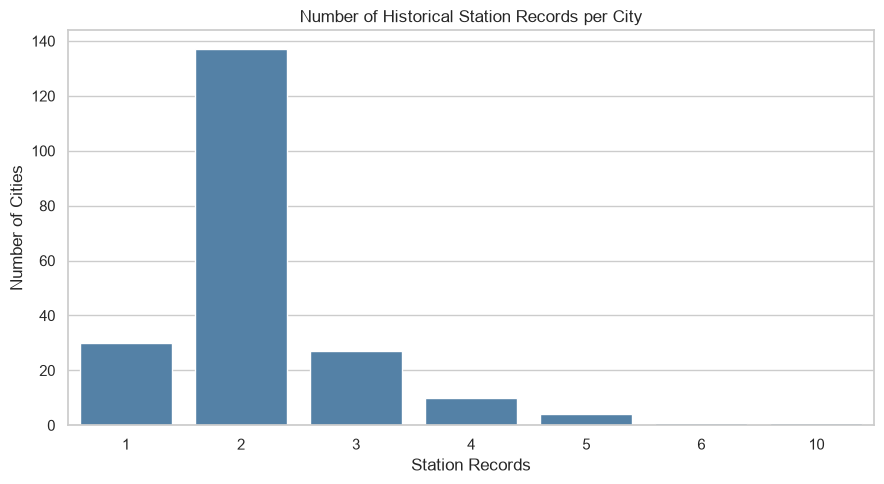

In [149]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=station_counts,
    x="station_records",
    color="steelblue"
)

plt.title("Number of Historical Station Records per City")
plt.xlabel("Station Records")
plt.ylabel("Number of Cities")

plt.tight_layout()
plt.show()

In [150]:
station_history = city_info.sort_values(
    ["ID", "Stn.stDate", "Stn.edDate"]
).copy()

station_history["previous_station"] = (
    station_history.groupby("ID")["Stn.Name"]
    .shift(1)
)

station_history["previous_end"] = (
    station_history.groupby("ID")["Stn.edDate"]
    .shift(1)
)

station_history["station_order"] = (
    station_history.groupby("ID")
    .cumcount() + 1
)

# The first station is not a transition
station_transitions = station_history[
    station_history["station_order"] > 1
].copy()

station_transitions["transition_year"] = (
    station_transitions["Stn.stDate"].dt.year
)

station_transitions["gap_days"] = (
    station_transitions["Stn.stDate"] -
    station_transitions["previous_end"]
).dt.days - 1

display(
    station_transitions[
        [
            "Name",
            "ID",
            "previous_station",
            "Stn.Name",
            "previous_end",
            "Stn.stDate",
            "transition_year",
            "gap_days"
        ]
    ].head(20)
)

,Name,ID,previous_station,Stn.Name,previous_end,Stn.stDate,transition_year,gap_days
1,Escondido,USC00042863,Escondido,Escondido 2,1979-03-31,1979-04-01,1979,0
3,Natchitoches,USC00166584,Natchitoches,Natchitoches #2,2010-07-31,2010-08-01,2010,0
5,Belvidere,USC00280734,Belvidere,Belvidere Bridge,1981-10-31,1981-11-01,1981,0
7,NewBrunswick,USC00286055,New Brunswick,Rutgers Experiment Station,1911-12-31,1912-01-01,1912,0
8,NewBrunswick,USC00286055,Rutgers Experiment Station,New Brunswick 3 SE,1968-05-31,1968-06-01,1968,0
10,Portland,USC00356749,PORTLAND RFC CITY,PORTLAND KGW-TV,1973-06-30,1973-07-01,1973,0
12,Aiken,USC00380072,Aiken 5 SE,Aiken 2 E,2008-11-01,2008-11-02,2008,0
14,Denver,USW00003017,DENVER WSO CITY,DENVER STAPLETON INTL ARPT,1949-12-31,1950-01-01,1950,0
15,Denver,USW00003017,DENVER STAPLETON INTL ARPT,DENVER INTL AP,1995-02-28,1995-03-01,1995,0
17,Flagstaff,USW00003103,FLAGSTAFF WB CITY,FLAGSTAFF PULLIAM ARPT,1950-01-11,1950-01-12,1950,0


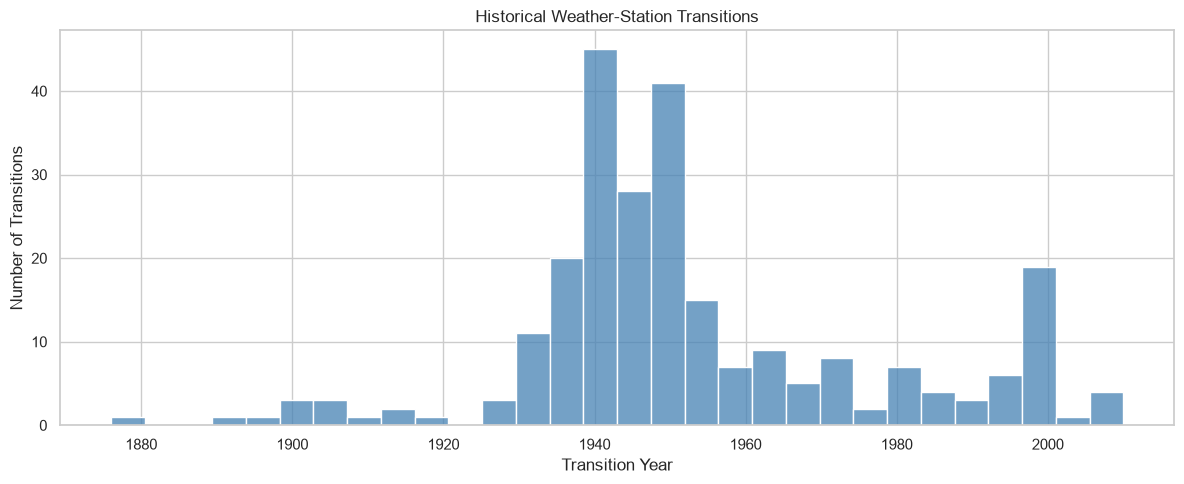

In [151]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=station_transitions,
    x="transition_year",
    bins=30,
    color="steelblue"
)

plt.title("Historical Weather-Station Transitions")
plt.xlabel("Transition Year")
plt.ylabel("Number of Transitions")

plt.tight_layout()
plt.show()

In [152]:
recent_transitions = station_transitions[
    station_transitions["transition_year"].between(
        1989, 2018
    )
]

print(
    "Station transitions during 1989–2018:",
    len(recent_transitions)
)

print(
    "Cities affected:",
    recent_transitions["ID"].nunique()
)

display(
    recent_transitions[
        [
            "Name",
            "previous_station",
            "Stn.Name",
            "transition_year"
        ]
    ].sort_values("transition_year")
)

Station transitions during 1989–2018: 32
Cities affected: 30


,Name,previous_station,Stn.Name,transition_year
413,McCook,McCook Municipal Airport,McCook,1989
191,MiddletownHarrisburg,HARRISBURG CAPITAL CITY ARPT,MIDDLETOWN HARRISBURG INTL AP,1991
282,Omaha,OMAHA WSFO,OMAHA EPPLEY AIRFIELD,1994
390,Louisville,LOUISVILLE STANDIFORD FIELD,LOUISVILLE WFO,1995
15,Denver,DENVER STAPLETON INTL ARPT,DENVER INTL AP,1995
20,Yuma,YUMA INTL ARPT,YUMA MCAS,1995
284,SiouxCity,SIOUX CITY,SIOUX CITY SIOUX GATEWAY AP,1996
423,Vancouver,Vancouver 4NNE,Vancouver Pearson AP,1996
414,McCook,McCook,McCook Municipal Airport,1997
64,Jefferson,Jefferson City Water Plant,Jefferson City Memorial Airport,1997


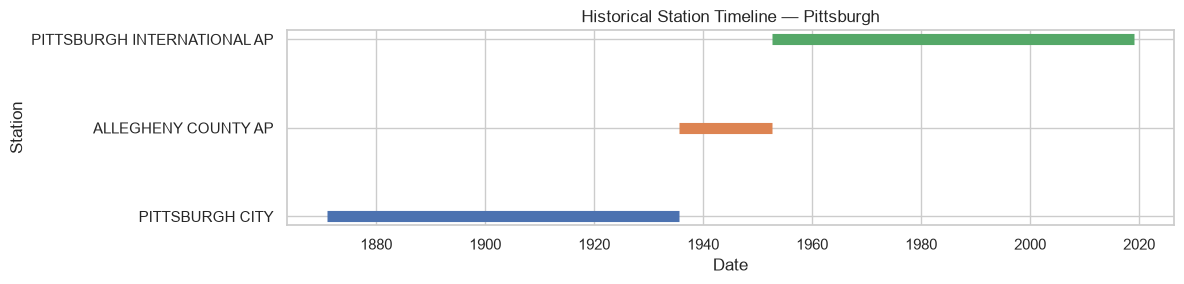

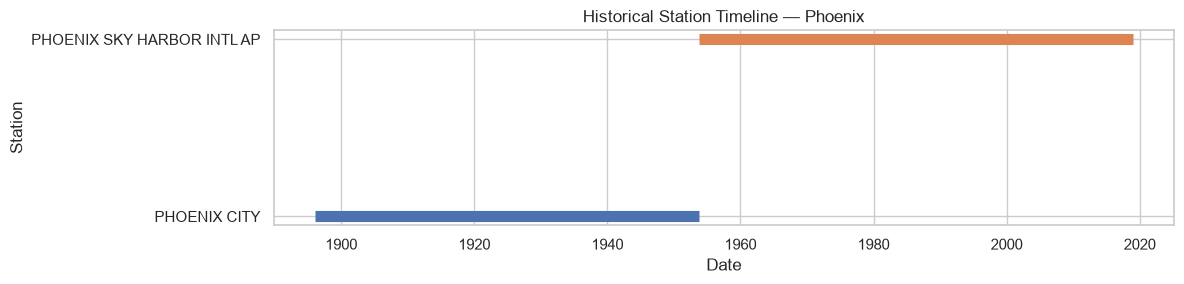

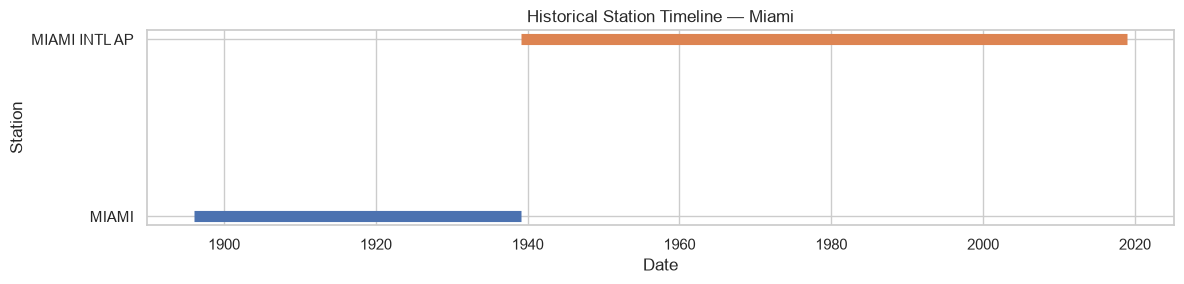

In [153]:
selected_cities = [
    "Pittsburgh",
    "Phoenix",
    "Miami"
]

for city in selected_cities:

    history = city_info[
        city_info["Name"] == city
    ].sort_values("Stn.stDate")

    if history.empty:
        continue

    fig, ax = plt.subplots(
        figsize=(12, max(3, len(history) * 0.7))
    )

    for i, (_, row) in enumerate(history.iterrows()):

        start = row["Stn.stDate"]
        end = row["Stn.edDate"]

        if pd.isna(start) or pd.isna(end):
            continue

        ax.plot(
            [start, end],
            [i, i],
            linewidth=8,
            solid_capstyle="butt"
        )

    ax.set_yticks(range(len(history)))

    ax.set_yticklabels(
        history["Stn.Name"].astype(str)
    )

    ax.set_title(f"Historical Station Timeline — {city}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Station")

    plt.tight_layout()
    plt.show()

In [154]:
annual_station = eda[
    [
        "ID",
        "Name",
        "Year",
        "Avg Temp_clean",
        "ToT Prcp_clean",
        "Max Tmax_clean",
        "cdd_clean"
    ]
].copy()

annual_station = annual_station.sort_values(
    ["ID", "Year"]
)

In [155]:
WINDOW = 5
MIN_VALID_PER_SIDE = 3

station_change_results = []

metrics = {
    "Avg Temp": "Avg Temp_clean",
    "ToT Prcp": "ToT Prcp_clean",
    "Max Tmax": "Max Tmax_clean",
    "cdd": "cdd_clean"
}

for _, transition in station_transitions.iterrows():

    city_id = transition["ID"]
    year = transition["transition_year"]

    if pd.isna(year):
        continue

    year = int(year)

    city_data = annual_station[
        annual_station["ID"] == city_id
    ]

    # Five calendar years before the transition
    before = city_data[
        city_data["Year"].between(
            year - WINDOW, year - 1
        )
    ]

    # Five calendar years after the transition
    # Exclude transition year because it may contain
    # observations from both stations.
    after = city_data[
        city_data["Year"].between(
            year + 1, year + WINDOW
        )
    ]

    for target, col in metrics.items():

        before_values = before[col].dropna()
        after_values = after[col].dropna()

        if (
            len(before_values) < MIN_VALID_PER_SIDE or
            len(after_values) < MIN_VALID_PER_SIDE
        ):
            continue

        mean_before = before_values.mean()
        mean_after = after_values.mean()

        station_change_results.append({
            "ID": city_id,
            "Name": transition["Name"],
            "transition_year": year,
            "previous_station": transition["previous_station"],
            "new_station": transition["Stn.Name"],
            "Target": target,
            "before_mean": mean_before,
            "after_mean": mean_after,
            "change": mean_after - mean_before,
            "before_valid_years": len(before_values),
            "after_valid_years": len(after_values)
        })

station_change_results = pd.DataFrame(station_change_results)

display(station_change_results.head())

,ID,Name,transition_year,previous_station,new_station,Target,before_mean,after_mean,change,before_valid_years,after_valid_years
0,USC00042863,Escondido,1979,Escondido,Escondido 2,ToT Prcp,17.406000,20.670,3.264000,5,3
1,USC00166584,Natchitoches,2010,Natchitoches,Natchitoches #2,Avg Temp,67.620000,66.456,-1.164000,3,5
2,USC00166584,Natchitoches,2010,Natchitoches,Natchitoches #2,ToT Prcp,56.467500,54.060,-2.407500,4,5
3,USC00166584,Natchitoches,2010,Natchitoches,Natchitoches #2,Max Tmax,104.666667,100.200,-4.466667,3,5
4,USC00166584,Natchitoches,2010,Natchitoches,Natchitoches #2,cdd,2699.833333,2657.400,-42.433333,3,5


In [156]:
temperature_changes = (
    station_change_results[
        station_change_results["Target"] == "Avg Temp"
    ]
    .copy()
)

temperature_changes["absolute_change"] = (
    temperature_changes["change"].abs()
)

display(
    temperature_changes
    .sort_values(
        "absolute_change",
        ascending=False
    )
    .head(20)
    .round(2)
)

,ID,Name,transition_year,previous_station,new_station,Target,before_mean,after_mean,change,before_valid_years,after_valid_years,absolute_change
634,USW00024233,Seattle,1945,SEATTLE CITY OFFICE,SEATTLE SEATTLE-TACOMA INTL AP,Avg Temp,54.26,50.01,-4.25,5,5,4.25
459,USW00014916,GrandForks,1965,GRAND FORKS UNIV NWS,GRAND FORKS INTERNATIONAL AP,Avg Temp,41.05,37.41,-3.63,5,5,3.63
541,USW00014991,EauClaire,1949,Eau Claire City,Eau Claire Chippewa Valley Regional Airport,Avg Temp,45.88,42.45,-3.44,5,5,3.44
790,USW00094850,Marquette,1979,MARQUETTE CITY,MARQUETTE WFO,Avg Temp,42.75,39.56,-3.19,5,5,3.19
597,USW00024127,SaltLakeCity,1928,SALT LAKE CITY DOWNTOWN,SALT LAKE CITY INTL ARPT,Avg Temp,52.35,49.44,-2.91,5,5,2.91
734,USW00094040,McCook,1997,McCook,McCook Municipal Airport,Avg Temp,50.90,53.70,2.81,3,5,2.81
276,USW00013882,Chattanooga,1940,CHATTANOOGA WB CITY,CHATTANOOGA LOVELL FIELD AP,Avg Temp,62.59,59.88,-2.71,5,5,2.71
139,USW00012816,Gainesville,1970,GAINESVILLE REGIONAL AP,GAINESVILLE 3 WSW,Avg Temp,68.29,70.96,2.67,5,5,2.67
699,USW00093842,ColumbusGA,1948,COLUMBUS GA,COLUMBUS METROPOLITAN ARPT,Avg Temp,67.13,64.70,-2.43,5,5,2.43
28,USW00003145,Yuma,1949,YUMA WB CITY,YUMA INTL ARPT,Avg Temp,72.45,74.88,2.43,5,5,2.43


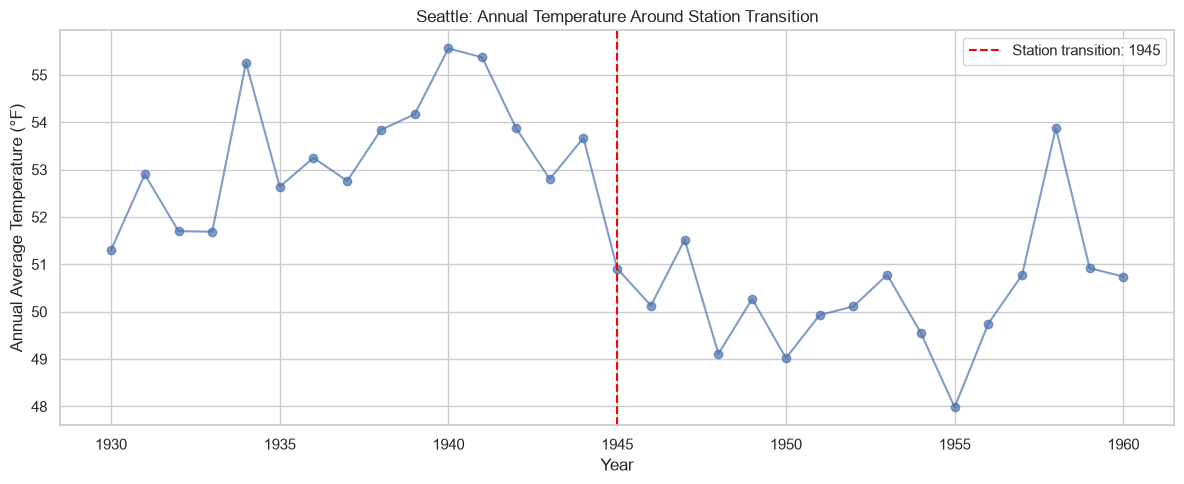

In [157]:
if not temperature_changes.empty:

    suspicious = (
        temperature_changes
        .sort_values("absolute_change", ascending=False)
        .iloc[0]
    )

    city_id = suspicious["ID"]
    city_name = suspicious["Name"]
    transition_year = int(suspicious["transition_year"])

    city_data = annual_station[
        annual_station["ID"] == city_id
    ]

    plot_data = city_data[
        city_data["Year"].between(
            transition_year - 15,
            transition_year + 15
        )
    ]

    plt.figure(figsize=(12, 5))

    plt.plot(
        plot_data["Year"],
        plot_data["Avg Temp_clean"],
        marker="o",
        alpha=0.7
    )

    plt.axvline(
        transition_year,
        color="red",
        linestyle="--",
        label=f"Station transition: {transition_year}"
    )

    plt.title(
        f"{city_name}: Annual Temperature Around Station Transition"
    )

    plt.xlabel("Year")
    plt.ylabel("Annual Average Temperature (°F)")
    plt.legend()

    plt.tight_layout()
    plt.show()

In [158]:
from sklearn.neighbors import BallTree

locations = (
    eda[
        ["ID", "Name", "Lat", "Lon"]
    ]
    .drop_duplicates("ID")
    .dropna(subset=["Lat", "Lon"])
    .reset_index(drop=True)
)

coords_rad = np.radians(
    locations[["Lat", "Lon"]].to_numpy()
)

tree = BallTree(
    coords_rad,
    metric="haversine"
)

# Find up to 5 neighbors plus the city itself
k = min(6, len(locations))

distances, indices = tree.query(
    coords_rad,
    k=k
)

neighbor_lookup = {}

for i, city_id in enumerate(locations["ID"]):

    neighbor_ids = [
        locations.iloc[j]["ID"]
        for j in indices[i]
        if locations.iloc[j]["ID"] != city_id
    ]

    neighbor_lookup[city_id] = neighbor_ids[:5]

In [159]:
regional_comparisons = []

for _, row in temperature_changes.iterrows():

    city_id = row["ID"]
    year = int(row["transition_year"])

    neighbor_ids = neighbor_lookup.get(city_id, [])

    neighbor_changes = []

    for neighbor_id in neighbor_ids:

        neighbor_data = annual_station[
            annual_station["ID"] == neighbor_id
        ]

        before = neighbor_data[
            neighbor_data["Year"].between(
                year - WINDOW, year - 1
            )
        ]["Avg Temp_clean"].dropna()

        after = neighbor_data[
            neighbor_data["Year"].between(
                year + 1, year + WINDOW
            )
        ]["Avg Temp_clean"].dropna()

        if (
            len(before) >= MIN_VALID_PER_SIDE and
            len(after) >= MIN_VALID_PER_SIDE
        ):

            neighbor_changes.append(
                after.mean() - before.mean()
            )

    if not neighbor_changes:
        continue

    regional_change = np.median(neighbor_changes)

    regional_comparisons.append({
        "ID": city_id,
        "Name": row["Name"],
        "transition_year": year,
        "city_change": row["change"],
        "regional_change": regional_change,
        "difference_from_region": (
            row["change"] - regional_change
        ),
        "neighbors_used": len(neighbor_changes)
    })

regional_comparisons = pd.DataFrame(regional_comparisons)

regional_comparisons["absolute_difference"] = (
    regional_comparisons["difference_from_region"].abs()
)

display(
    regional_comparisons
    .sort_values(
        "absolute_difference",
        ascending=False
    )
    .head(20)
    .round(2)
)

,ID,Name,transition_year,city_change,regional_change,difference_from_region,neighbors_used,absolute_difference
191,USW00094850,Marquette,1979,-3.19,0.76,-3.95,3,3.95
155,USW00024233,Seattle,1945,-4.25,-1.22,-3.02,5,3.02
5,USW00003103,Flagstaff,1950,-1.89,0.95,-2.84,5,2.84
170,USW00093842,ColumbusGA,1948,-2.43,0.21,-2.64,5,2.64
169,USW00093824,Zaneville,1946,-2.26,0.21,-2.47,4,2.47
27,USW00003947,KansasCity,1972,-1.77,0.69,-2.46,2,2.46
51,USW00012960,Houston,1969,-1.87,0.55,-2.42,5,2.42
132,USW00014991,EauClaire,1949,-3.44,-1.08,-2.36,3,2.36
164,USW00093815,Dayton,1948,-1.41,0.90,-2.31,4,2.31
67,USW00013882,Chattanooga,1940,-2.71,-0.41,-2.31,5,2.31


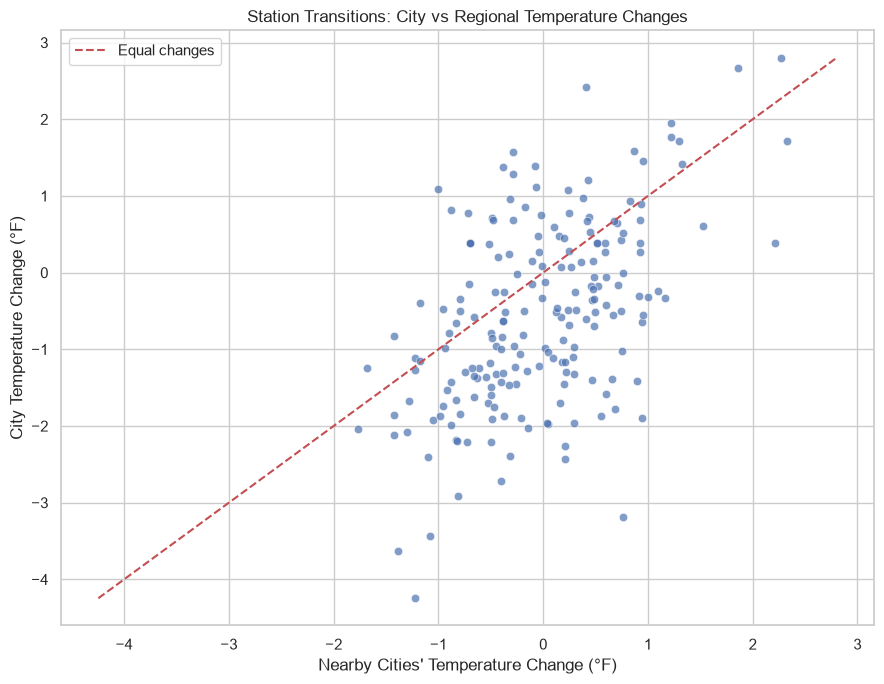

In [160]:
if not regional_comparisons.empty:

    plt.figure(figsize=(9, 7))

    sns.scatterplot(
        data=regional_comparisons,
        x="regional_change",
        y="city_change",
        alpha=0.7
    )

    limits = [
        min(
            regional_comparisons["city_change"].min(),
            regional_comparisons["regional_change"].min()
        ),
        max(
            regional_comparisons["city_change"].max(),
            regional_comparisons["regional_change"].max()
        )
    ]

    plt.plot(
        limits,
        limits,
        "r--",
        label="Equal changes"
    )

    plt.xlabel("Nearby Cities' Temperature Change (°F)")
    plt.ylabel("City Temperature Change (°F)")

    plt.title(
        "Station Transitions: City vs Regional Temperature Changes"
    )

    plt.legend()
    plt.tight_layout()
    plt.show()

In [161]:
REVIEW_THRESHOLD = 2.0

regional_comparisons["review_station_change"] = (
    regional_comparisons["absolute_difference"] >=
    REVIEW_THRESHOLD
)

station_review = (
    regional_comparisons[
        regional_comparisons["review_station_change"]
    ]
    .sort_values(
        "absolute_difference",
        ascending=False
    )
)

print(
    "Transitions requiring closer investigation:",
    len(station_review)
)

print(
    "Cities affected:",
    station_review["ID"].nunique()
)

display(station_review.head(20).round(2))

Transitions requiring closer investigation: 19
Cities affected: 19


,ID,Name,transition_year,city_change,regional_change,difference_from_region,neighbors_used,absolute_difference,review_station_change
191,USW00094850,Marquette,1979,-3.19,0.76,-3.95,3,3.95,True
155,USW00024233,Seattle,1945,-4.25,-1.22,-3.02,5,3.02,True
5,USW00003103,Flagstaff,1950,-1.89,0.95,-2.84,5,2.84,True
170,USW00093842,ColumbusGA,1948,-2.43,0.21,-2.64,5,2.64,True
169,USW00093824,Zaneville,1946,-2.26,0.21,-2.47,4,2.47,True
27,USW00003947,KansasCity,1972,-1.77,0.69,-2.46,2,2.46,True
51,USW00012960,Houston,1969,-1.87,0.55,-2.42,5,2.42,True
132,USW00014991,EauClaire,1949,-3.44,-1.08,-2.36,3,2.36,True
164,USW00093815,Dayton,1948,-1.41,0.90,-2.31,4,2.31,True
67,USW00013882,Chattanooga,1940,-2.71,-0.41,-2.31,5,2.31,True


In [162]:
transition_summary = (
    station_transitions.groupby("ID")
    .agg(
        transition_count=("transition_year", "count"),
        latest_transition=("transition_year", "max")
    )
    .reset_index()
)

review_counts = (
    station_review.groupby("ID")
    .size()
    .rename("flagged_transitions")
    .reset_index()
)

city_station_report = (
    station_counts
    .merge(
        transition_summary,
        on="ID",
        how="left"
    )
    .merge(
        review_counts,
        on="ID",
        how="left"
    )
)

city_station_report[
    ["transition_count", "flagged_transitions"]
] = (
    city_station_report[
        ["transition_count", "flagged_transitions"]
    ]
    .fillna(0)
    .astype(int)
)

display(
    city_station_report
    .sort_values(
        ["flagged_transitions", "transition_count"],
        ascending=False
    )
    .head(20)
)

,ID,Name,station_records,unique_stations,first_station_date,last_station_date,transition_count,latest_transition,flagged_transitions
8,USW00003145,Yuma,3,3,1876-01-01,2018-12-31,2,1995.0,1
23,USW00003947,KansasCity,3,3,1889-01-01,2018-12-31,2,1972.0,1
7,USW00003103,Flagstaff,2,2,1899-01-01,2018-12-31,1,1950.0,1
38,USW00012960,Houston,2,2,1889-01-01,2018-12-31,1,1969.0,1
40,USW00013733,Lynchburg,2,2,1893-01-01,2018-12-31,1,1944.0,1
55,USW00013882,Chattanooga,2,2,1879-01-01,2018-12-31,1,1940.0,1
82,USW00014735,Albany,2,2,1874-01-01,2018-12-31,1,1938.0,1
84,USW00014742,Burlington,2,2,1884-01-01,2018-12-31,1,1943.0,1
88,USW00014764,PortlandME,2,2,1872-01-01,2018-12-31,1,1940.0,1
109,USW00014916,GrandForks,2,2,1893-01-01,2018-12-31,1,1965.0,1


In [163]:
final_city_info_report = pd.DataFrame({
    "Metric": [
        "Total cities",
        "Total station records",
        "Cities with multiple station records",
        "Recorded station transitions",
        "Transitions during 1989–2018",
        "Transitions evaluated for temperature changes",
        "Transitions with regional comparisons",
        "Transitions flagged for investigation"
    ],
    "Value": [
        city_info["ID"].nunique(),
        len(city_info),
        (station_counts["station_records"] > 1).sum(),
        len(station_transitions),
        len(recent_transitions),
        len(temperature_changes),
        len(regional_comparisons),
        len(station_review)
    ]
})

display(final_city_info_report)

,Metric,Value
0,Total cities,210
1,Total station records,461
2,Cities with multiple station records,180
3,Recorded station transitions,251
4,Transitions during 1989–2018,32
5,Transitions evaluated for temperature changes,199
6,Transitions with regional comparisons,198
7,Transitions flagged for investigation,19
